# Lab01 - sprint 1

**Статистическое исследование ферментативного гидролиза крахмала глюкоамилазой(свободной и иммобилизованной на мезопористом TiO₂) по теме: "Иммобилизация глюкоамилазы на мезопористом диоксиде титана и исследование ее активности при гидролизе крахмала"**

Дисциплина «ИнфоХимия», ИТМО · Команда: Рахмангулова Галия(Инфохимия)

Данные: собственные лабораторные измерения оптических плотностей и степени гидролиза по ним(фотометрические спектры на длине волны 580нм)

Спринт 1 — всё, кроме генератора случайных чисел: три случайные величины, их природа, EDA, распределения, независимость, состоятельность оценок, выборки и гипотезы. Тяжёлый код по ТЗ вынесен в пакет `labtools/`, в ноутбуке остаются вызовы, графики и интерпретация. Все случайные эксперименты воспроизводимы: зерно `SEED = 20261021`(стартовое число для генератора случайных чисел) задано в `labtools/__init__.py`. Поэтому все графики и цифры у всех будут одинаковыми (воспроизводимыми).

## Содержание

1. [Introduction](#introduction)
2. [Dataset Description](#dataset)
3. [Data Validation](#validation)
4. [Random Variable 01 — оптическая плотность контроля $A_\text{к}$](#rv1)
    - [Description](#rv1-description) · [EDA & Distribution](#rv1-eda) · [Independence & Estimations](#rv1-independence) · [Sampling](#rv1-sampling) · [Hypothesis Testing](#rv1-hypotheses) · [Resume](#rv1-resume)
5. [Random Variable 02 — оптическая плотность пробы с ферментом $A_\text{п}$](#rv2)
    - [Description](#rv2-description) · [EDA & Distribution](#rv2-eda) · [Independence & Estimations](#rv2-independence) · [Sampling](#rv2-sampling) · [Hypothesis Testing](#rv2-hypotheses) · [Resume](#rv2-resume)
6. [Random Variable 03 — степень гидролиза $X$](#rv3)
    - [Description](#rv3-description) · [EDA & Distribution](#rv3-eda) · [Independence & Estimations](#rv3-independence) · [Sampling](#rv3-sampling) · [Hypothesis Testing](#rv3-hypotheses) · [Resume](#rv3-resume)
7. [Comparative Analysis](#comparative)
8. [Lab resume](#resume) · [cat_mark_table](#cat-mark-table)
9. [References](#references)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display

from labtools import SEED
from labtools import data as ld, validation as vd, stats_tools as st, plots as pl

pl.apply_style() #вызов функции из вашего пакета labtools/plots.py, применяет единый стиль ко всем графикам
pd.set_option("display.float_format", lambda v: f"{v:.4g}") #настройка библиотеки pandas
pd.set_option("display.max_columns", 40) #настройки отображения таблиц(до 40 столбцов)
pd.set_option("display.width", 200) #настройки отображения таблиц(делают окно шире)
print("SEED =", SEED)

SEED = 20261021


numpy (Numerical Python): Это библиотека для быстрых математических вычислений.\
pandas: Это главный инструмент для работы с таблицами.\
matplotlib.pyplot (импортируется как plt): Библиотека для рисования графиков.\
scipy (Scientific Python): Это библиотека для сложной научной математики.\
statsmodels: Дополнительная библиотека для статистики.\
\
data.py: Код, который читает CSV и размечает данные.\
validation.py: Код, который проверяет тройки и ищет ошибки в таблицах.\
stats_tools.py: Все ваши сложные статистические тесты и бутстрепы.\
plots.py: Код, который рисует красивые графики (он импортируется как pl).

<a id="introduction"></a>
## Introduction(Введение)

**Цель.** Показать, какие величины в нашем эксперименте случайные, как устроена их случайность и что из этого следует для выводов о разных пробах фермента. Для этого берём три случайные величины, описываем их распределения, проверяем независимость, состоятельность оценок и гипотезы о влиянии условий опыта. После этого мы можем сделать выводы о наших результатах.

**Химическая задача.** Глюкоамилаза (экзо-1,4-α-глюкозидаза) последовательно отщепляет глюкозу от невосстанавливающих концов цепей крахмала. Свободные фермнеты не всегда удобно использовать в реакционной смеси, тк они часто бывают неставиблыми и их сложно отделить от реакционной смеси. Поэтому иммобилизация фермнета на твердом носители является основным способом устранения этой проблемы.
Остаток крахмала определяют анализируется йодометрическим методом: йод встраивается в спирали длинных цепей и даёт синий комплекс, который поглощает свет при 580 нм. Чем больше крахмала осталось, тем выше оптическая плотность (закон Бугера–Ламберта–Бера):

$$A_{580} = \varepsilon\, l\, c_{\text{комплекса}} \;\propto\; c_{\text{крахмала}}.$$

Сравнивали три типа проб: **контроль** (крахмал без фермента), **свободный фермент**(свободная глюкоамилаза в растовре) и **иммобилизованный фермент** (глюкоамилазу, адсорбированную на мезопористом TiO₂ после сонохимической и термической обработки). Иммобилизованный фермент использовали повторно, в циклах 1–3. Степень гидролиза считается по паре «контроль — проба» при одинаковых условиях:

$$X = \frac{A_\text{к} - A_\text{п}}{A_\text{к}}\cdot 100\,\% .$$

**Источник данных.** Только реальные лабораторные измерения оптических плотностей на спектрофотометре: кварцевая кювета 1 см, базовая линия по дистиллированной воде, каждая проба — отдельный сосуд. Синтетические данные в спринте 1 не используются. Датасет 2 (степень гидролиза) вычислен из датасета 1, поэтому мы пересчитали его сами и сверили с исходной таблицей.

**Модель измерения.** Условия опыта — температура $T$, pH, концентрация крахмала $C$, время $t$, тип фермента $E$ и номер цикла $k$ — задаёт экспериментатор. Это управляемые факторы, а не случайные величины. Измеренную ОП раскладываем на систематическую часть и случайную ошибку. Ошибка мультипликативная: относительная, а не абсолютная, поэтому работаем в логарифмах:

$$\ln A_{ij} = \ln \mu(T, \mathrm{pH}, C, t, E, k) + \delta_{ij}, \qquad \mathbb E\,\delta_{ij} = 0,$$

где $\mu$ — истинная ОП при данных условиях, $\delta_{ij}$ — случайная ошибка сосуда $j$ в условии $i$ (пипетирование, приготовление растворов, развитие окраски, установка кюветы, шум фотометра).

**Три случайные величины** выбраны так, чтобы покрыть всю цепочку измерения:

| СВ | Величина | Датасет | Что в ней случайно |
|---|---|---|---|
| 01 | ОП контроля $A_\text{к}$ | 1 | ошибка приготовления и измерения без реакции |
| 02 | ОП пробы с ферментом $A_\text{п}$ | 1 | то же + разброс ферментативной реакции |
| 03 | степень гидролиза $X$ | 2 (пересчитан) | функция двух случайных ОП |

СВ-01 и СВ-02 одной природы (обе — ОП), поэтому по ТЗ проверяем их независимость. СВ-03 вычисляется из СВ-01 и СВ-02, и зависимость от них у неё функциональная, по построению: это объясняем, а не «открываем».

**Главный методический принцип — единица анализа.** Независимыми считаем только то, что действительно получено независимо. Ниже увидим, что сосуды одной серии делят общие ошибки приготовления растворов. Поэтому гипотезы о систематических эффектах проверяем на уровне серий, а не отдельных точек: иначе одно и то же приготовление посчитается много раз, это называется псевдоповторностями.

<a id="dataset"></a>
## Dataset Description

Датасет 1 (`data/raw/od_statistika_list1.csv`, исходное имя «Статистика – Лист1») — 588 значений ОП. Строки идут тройками: одно условие опыта и три значения. Датасет 2 (`data/raw/hydrolysis_tablichki_list2.csv`, «Таблички – Лист2») — 148 строк со степенью гидролиза и столбцом «Погрешность». Десятичный разделитель в файлах — запятая; функция `ld.load_od` приводит всё к числам и переводит заголовки на английский, имена переменных в коде — латиницей.

| Фактор | Обозначение | Единицы | Уровни |
|---|---|---|---|
| Температура | $T$ | °C | 25, 30, 40, 50, 60, 70, 80, 90 |
| pH | pH | — | 3,8; 4,2; 4,7; 5,0; 5,4; 5,8 |
| Концентрация крахмала | $C$ | % (г/100 мл) | 0,25; 0,5; 0,75; 1; 1,25 |
| Время реакции | $t$ | мин | 5, 10, 15, 20, 25, 30 |
| Тип пробы | $E$ | — | контроль, свободный, иммобилизованный |
| Цикл (иммобилизованный) | $k$ | — | 1, 2, 3 |
| Оптическая плотность | $A$ | отн. ед. | измеряемая величина |

Данные — пять отдельных экспериментов. В каждом меняли один фактор, остальные держали постоянными (однофакторный дизайн).

In [2]:
od = ld.add_series(ld.load_od()) #окрывает csv, объединяет данные
table = ld.load_table() #загружает второй csv
print(f"Датасет 1: {od.shape[0]} строк, {od['triplet_id'].nunique()} троек; датасет 2: {table.shape[0]} строк") #показывает данные
display(ld.experiments_overview(od)) #выврл табоицы

Датасет 1: 588 строк, 196 троек; датасет 2: 148 строк


,эксперимент,описание,строки №,условий (троек),контроль,свободный,иммобилизованный,циклы
0,conc,"Концентрация крахмала 0,25–1,25 %; 30 °C; pH 4...",1–330,110,30,30,50,"1, 2, 3"
1,kin90,"Кинетика при 90 °C; C = 1 %; pH 4,7; t = 5–30 мин",331–390,20,6,6,8,"1, 2, 3"
2,kin60,"Кинетика при 60 °C; C = 1 %; pH 4,7; t = 5–30 мин",391–480,30,6,6,18,"1, 2, 3"
3,temp,"Температура 25–90 °C; C = 1 %; pH 4,7; t = 30 мин",481–534,18,6,6,6,1
4,ph,"pH 3,8–5,8; 30 °C; C = 1 %; t = 30 мин",535–588,18,6,6,6,1


**Что видно.** Самый большой эксперимент - это анализ влияния концентрация(0,25; 0,50; 1,00; 1,25): 110 условий, кинетика 5–30 мин при пяти концентрациях(0,25; 0,50; 1,00; 1,25). Температурный и pH-эксперименты сняты только при 30 мин. Циклы 2–3 иммобилизованного фермента есть в трёх экспериментах из пяти.

Каждый фактор менялся в своём эксперименте, взаимодействия факторов (например, T × pH) по этим данным оценить нельзя. Условие «30 °C, pH 4,7, C = 1 %, 30 мин» встречается в двух разных экспериментах, а «90 °C, 30 мин» — тоже в двух. Это даёт редкую возможность оценить, насколько результат меняется от одной постановки опыта к другой.

<a id="validation"></a>
## Data Validation

Прежде чем считать статистику, проверяем сами данные: типы, пропуски, дубли, допустимые значения и то, что три значения в тройке действительно независимые сосуды. Последний пункт оказался главным.

In [3]:
checks = pd.Series({
    "строк в датасете 1": len(od),
    "троек (условий опыта)": od["triplet_id"].nunique(),
    "пропусков": int(od.isna().sum().sum()),
    "полных дублей строк (без №)": int(od.drop(columns="row_id").duplicated().sum()),
    "ОП ≤ 0": int((od["absorbance"] <= 0).sum()),
    "ОП > 2 (вне линейного диапазона фотометра)": int((od["absorbance"] > 2).sum()),
    "минимальная ОП": od["absorbance"].min(),
    "максимальная ОП": od["absorbance"].max(),
    "строк в датасете 2": len(table),
    "пропусков в датасете 2": int(table.isna().sum().sum()),
}, name="значение")
display(checks.to_frame()) #певарщает в табличку
display(od.dtypes.rename("тип данных").to_frame().T) #вывод типов данных для каждого значения

,значение
строк в датасете 1,588
троек (условий опыта),196
пропусков,0
полных дублей строк (без №),0
ОП ≤ 0,0
ОП > 2 (вне линейного диапазона фотометра),0
минимальная ОП,0.09537
максимальная ОП,1.545
строк в датасете 2,148
пропусков в датасете 2,0


,row_id,absorbance,temperature_c,ph,substrate_pct,time_min,sample_type,cycle,experiment,triplet_id,position,is_measured,series
тип данных,int64,float64,int64,float64,float64,int64,str,int64,str,int64,int64,bool,str


**Что видно.** Пропусков и дублей строк нет. Все ОП положительны и лежат в диапазоне 0,095–1,55, то есть в рабочем диапазоне фотометра, где выполняется закон Бугера-Ламберта-Бера. Типы данных правильные: ОП, pH и концентрация — вещественные числа, остальные факторы — целые или категории.

### Независимы ли три значения в тройке

Если три сосуда независимы, их ОП — три разные реализации случайной величины, и ни одна не выражается через другие. Проверяем обратное: нет ли в тройке значения, которое в точности вычисляется из двух других. Допуск $10^{-9}$ означает точное равенство, потому что значения записаны с 5–6 знаками.

In [4]:
triplets = vd.classify_triplets(od) #пытается понять, является ли третье значение (A3) вычисленным.
kinds = triplets["third_kind"].map(vd.KIND_LABELS).value_counts().rename_axis("третье значение").to_frame("троек")
display(kinds) #код берет результаты проверки и считает, сколько троек попало в каждую категорию
display(pd.crosstab(triplets["experiment"], triplets["third_kind"].map(vd.KIND_LABELS), margins=True, margins_name="всего")) #оздает сводную таблицу
examples = od[od["row_id"].between(79, 81) | od["row_id"].between(88, 90)] #код выбирает конкретные строки из датасета
display(examples[["row_id", "sample_type", "substrate_pct", "time_min", "position", "absorbance"]]
        .style.format({"absorbance": "{:.5f}"}).hide(axis="index")) #выводит таблицу с номерами

,троек
третье значение,
A₃ = (A₁ + A₂)/2,104
A₃ = 2·A₁ − A₂,59
не связано формулой,33


third_kind,A₃ = (A₁ + A₂)/2,A₃ = 2·A₁ − A₂,не связано формулой,всего
experiment,,,,
conc,50,30,30,110
kin60,21,8,1,30
kin90,12,8,0,20
ph,11,5,2,18
temp,10,8,0,18
всего,104,59,33,196


row_id,sample_type,substrate_pct,time_min,position,absorbance
79,free,0.500000,5,1,0.49872
80,free,0.500000,5,2,0.50902
81,free,0.500000,5,3,0.50387
88,free,0.500000,20,1,0.33990
89,free,0.500000,20,2,0.33899
90,free,0.500000,20,3,0.34081


**Что видно.** В 163 из 196 троек третье значение — функция первых двух:

- в 104 тройках это их среднее: в строках 79–81 $0{,}50387 = (0{,}49872 + 0{,}50902)/2$;
- в 59 тройках это «зеркало» $A_3 = 2A_1 - A_2$: в строках 88–90 $0{,}34081 = 2\cdot 0{,}3399 - 0{,}33899$, и тогда средним выглядит первое значение.

Вариант $2A_2 - A_1$ не встречается ни разу. Значит, вычислена именно третья позиция, а первые две — измерения. Это подтверждает и сверка с датасетом 2 ниже.

In [5]:
pairs = ld.add_series(ld.measured_pairs(od)) #берет только два измеренных сосуда (позиции 1 и 2) из каждой тройки и считает для них стандартное отклонение (sd)
expected = vd.expected_chance_coincidences(pairs["sd"].to_numpy(), tol=6e-6, n_sim=20_000, seed=SEED) #берет реальные значения разброса (SD) из ваших данных и генерирует 20 000 искусственных (случайных) троек
observed = int((triplets["third_kind"] != "unlinked").sum()) #смотрит сколько исскуственных троек в наших ральных тройках
print(f"Ожидается при независимых сосудах: {expected:.2f} тройки; наблюдается: {observed}")

Ожидается при независимых сосудах: 0.85 тройки; наблюдается: 163


**Вывод и решение.** Случайно ожидалось меньше одной такой тройки, а наблюдается 163, так что третье значение в них вычислено. По ТЗ (п. 2.1) случайная величина — то, что нельзя вычислить формулой, поэтому вычисленное значение в анализ не входит.

Исходные файлы не меняем. У каждой строки есть флаг `is_measured`: позиции 1–2 — измеренные сосуды, позиция 3 — вычисленная или неподтверждённая. Во всём анализе используем позиции 1–2 во всех 196 тройках — одно правило для всех. У 33 троек, не связанных формулой, происхождение третьего значения тоже не подтверждается: часть строк датасета 2 по этим условиям не сходится с текущими ОП (см. ниже).

Что меняется, если вычисленное значение всё же считать сосудом:

In [6]:
impact = vd.impact_of_third_value(triplets) #берет данные и считает статистику двумя способами
display(impact["pooled_sd"]) #выводит таблицу с разбросом данных
display(impact["ratios"]) #выводит таблицу с соотношением стандартных отклонений
display(impact["welch"]) #выводит таблицу с результатами t-теста Уэлча (сравнение свободного и иммобилизованного фермента)
print(f"Вывод «есть различие / нет различия» меняется в {impact['welch_flips']} условиях из {impact['welch']['условий'].iloc[0]}")

,как считаем,пулированное SD ln A,степеней свободы
0,тройка целиком (n = 3),0.0433,392
1,два измеренных сосуда (n = 2),0.0555,196


,тип третьего значения,троек,SD тройки / SD пары,«Погрешность» по 3 / по 2
0,A₃ = (A₁ + A₂)/2,104,0.7071,0.667–0.667
1,A₃ = 2·A₁ − A₂,59,1.414,1.251–1.412


,как считаем,условий,значимых различий (p < 0.05)
0,тройка целиком (n = 3),54,12
1,два измеренных сосуда (n = 2),54,3


Вывод «есть различие / нет различия» меняется в 9 условиях из 54


**Что видно.**

- **Разброс.** Среднее в третьей позиции занижает SD тройки ровно в $\sqrt2$ раз (×0,707), «зеркало» завышает во столько же (×1,414). Пулированное SD $\ln A$ — средний разброс сосудов — по тройкам целиком на 22 % меньше, чем по двум измеренным сосудам.
- **Степени свободы.** Формально их вдвое больше, хотя информации столько же, сколько от двух сосудов.
- **Тесты.** Из 54 сравнений свободного и иммобилизованного фермента «значимых» 12 с третьим значением и только 3 без него. Девять выводов создаёт досчитанное число.

### Воспроизводимость датасета 2 и формула «Погрешности»

Пересчитываем каждую строку «Табличек» по формуле $X = (A_\text{к} - A_\text{п})/A_\text{к}\cdot100\,\%$ из троек ОП. Если не сходится, пробуем убрать из тройки одно значение. Отдельно проверяем формулу «Погрешности», которой пользовались в Excel: `=СРОТКЛ(A)/A_ср*100`.

In [7]:
audit = vd.audit_table(table, triplets)
status_labels = {"exact": "сходится с тройками целиком", "two_of_three": "сходится, только если убрать одно значение",
                 "not_reproducible": "не воспроизводится"}
basis_labels = {"all3": "по трём значениям", "p12": "по двум измеренным (поз. 1–2)", "p13": "по позициям 1 и 3",
                "p23": "по позициям 2 и 3", "none": "не совпадает ни с одним вариантом"}
display(audit["status"].map(status_labels).value_counts().to_frame("строк"))
display(audit["err_basis"].map(basis_labels).value_counts().rename_axis("«Погрешность» посчитана").to_frame("строк"))
display(audit[audit["status"] == "not_reproducible"][["file_line", "table_block", "x_pct", "err_pct"]])
dups = vd.table_duplicates(table)
display(dups[["file_line", "table_block", "temperature_c", "sample_type", "x_pct", "err_pct"]])

,строк
status,
сходится с тройками целиком,114
"сходится, только если убрать одно значение",28
не воспроизводится,6


,строк
«Погрешность» посчитана,
по трём значениям,80
по двум измеренным (поз. 1–2),58
не совпадает ни с одним вариантом,10


,file_line,table_block,x_pct,err_pct
2,4,conc,48.42,1.624
4,6,conc,63.33,2.981
6,8,conc,20.36,0.484
8,10,conc,49.26,0.7501
9,11,conc,55.08,4.181
125,127,temp,12.23,4.727


,file_line,table_block,temperature_c,sample_type,x_pct,err_pct
115,117,kin90,90,immobilized,15.93,4.029
134,136,temp,90,immobilized,15.93,4.029
53,55,conc,30,immobilized,20.44,3.454
128,130,temp,30,immobilized,20.44,3.454
47,49,conc,30,free,32.56,2.79
119,121,temp,30,free,32.56,2.79
91,93,kin60,60,immobilized,80.88,0.03411
131,133,temp,60,immobilized,80.88,0.03411
85,87,kin60,60,free,87.66,2.85
122,124,temp,60,free,87.66,2.85


**Что видно.**

- **Сверка.** 114 строк из 148 точно получаются из текущих ОП. Ещё 28 сходятся, только если из тройки убрать одно значение: таблицу считали по другой версии ОП. 6 строк не воспроизводятся никак — пять в блоке $C = 0{,}25\,\%$ и строка «90 °C, свободный, 12,23 %».
- **Дубли.** 5 строк повторены: точки 30, 60 и 90 °C из кинетических экспериментов скопированы в температурную серию. Одно измерение не должно попасть в статистику дважды.
- **Что такое «Погрешность».** `СРОТКЛ` — это функция AVEDEV, среднее абсолютное отклонение $\frac1n\sum|A_j-\bar A|$, а не стандартное отклонение. В таблице она посчитана то по трём значениям (80 строк), то по двум (58).

Главное: эта величина — относительный разброс ОП *пробы* в процентах от самой ОП. Это не погрешность степени гидролиза, по двум причинам. Разброс контроля в ней не учтён. И единицы другие: проценты от $A_\text{п}$, а не процентные пункты $X$.

**Решение.** Пересчитываем датасет 2 из измеренных сосудов. Погрешность $X$ получаем по закону распространения неопределённостей (вывод формулы — в СВ-3):

$$u(X) = 100\,\%\cdot\frac{\bar A_\text{п}}{\bar A_\text{к}}\sqrt{\left(\frac{u_\text{п}}{\bar A_\text{п}}\right)^2+\left(\frac{u_\text{к}}{\bar A_\text{к}}\right)^2}, \qquad u = \frac{s}{\sqrt n}.$$

In [8]:
hyd = ld.add_series(ld.recompute_hydrolysis(pairs))
used = od[od["is_measured"]].copy()            # 392 измеренных значения ОП
ctrl = pairs[pairs["sample_type"] == "control"].copy()
enz = pairs[pairs["sample_type"] != "control"].copy()

processed = ld.DATA_DIR / "processed"
used.to_csv(processed / "od_measured.csv", index=False)
pairs.to_csv(processed / "od_pairs.csv", index=False)
hyd.to_csv(processed / "hydrolysis_recomputed.csv", index=False)
print(f"Измеренных ОП: {len(used)}; условий: {len(pairs)} (контроль {len(ctrl)}, с ферментом {len(enz)}); "
      f"пересчитанных степеней гидролиза: {len(hyd)}")
display(hyd.head(3))

Измеренных ОП: 392; условий: 196 (контроль 54, с ферментом 142); пересчитанных степеней гидролиза: 142


,triplet_id,experiment,temperature_c,ph,substrate_pct,time_min,sample_type,cycle,a_sample,a_control,x_pct,u_x_pct,x_vessel1,x_vessel2,series
0,6,conc,30,4.7,0.25,5,free,1,0.2622,0.3316,20.93,1.952,22.78,19.07,conc 0.25 %
1,7,conc,30,4.7,0.25,10,free,1,0.1961,0.3376,41.93,5.609,47.54,36.32,conc 0.25 %
2,8,conc,30,4.7,0.25,15,free,1,0.1798,0.3393,47.01,1.996,48.3,45.72,conc 0.25 %


<a id="rv1"></a>
## Random Variable 01 — оптическая плотность контроля $A_\text{к}$

<a id="rv1-description"></a>
### Description

**Определение.** $A_\text{к}$ — оптическая плотность при 580 нм сосуда с крахмалом и йодом без фермента. Измерена в 54 условиях по 2 сосуда, всего 108 значений.

**Физический смысл.** Контроль показывает, сколько крахмала было бы в растворе без гидролиза. По закону Бера $A_\text{к}$ пропорциональна концентрации йод-крахмального комплекса, то есть заданной концентрации крахмала $C$. Возможные значения — положительные числа, в наших данных 0,33–1,52.

**Почему это случайная величина.** Систематическая часть ОП контроля задаётся условиями: прежде всего $C$, а ещё время и температура инкубации. Но два сосуда, приготовленные при *одних и тех же* условиях, дают разные ОП. Это различие нельзя вычислить ни по одной формуле от условий — это и есть случайная составляющая. Её источники:

- навеска и растворение крахмала, разбавление до заданной концентрации;
- пипетирование крахмала и раствора йода;
- развитие окраски: время между добавлением йода и измерением, температура;
- установка кюветы, пузырьки, шум фотометра.

**Как отделить случайное от систематического.** У каждого условия $i$ есть два сосуда, а ошибка мультипликативная (см. Introduction). Возьмём разность логарифмов:

$$D_i = \ln A_{i1} - \ln A_{i2} = \bigl(\ln\mu_i + \delta_{i1}\bigr) - \bigl(\ln\mu_i + \delta_{i2}\bigr) = \delta_{i1} - \delta_{i2}.$$

Систематическая часть $\mu_i$ сокращается, какой бы сложной ни была её зависимость от условий. Остаётся чистая случайная ошибка. Если $\delta_{ij}$ независимы и имеют одинаковое распределение со средним 0 и дисперсией $\sigma^2$, то

$$\mathbb E D = 0, \qquad \operatorname{Var} D = 2\sigma^2 \;\Rightarrow\; \sigma = \frac{\operatorname{SD}(D)}{\sqrt 2}.$$

Здесь $\sigma$ — относительная ошибка одного сосуда: $\sigma = 0{,}02$ означает около 2 % от ОП.

Дальше СВ-01 исследуем с двух сторон. **Значения** $A_\text{к}$ (108 штук) нужны для EDA и выборок. **Случайная составляющая** $D_\text{к}$ (54 штуки) нужна для распределения, независимости и состоятельности.

<a id="rv1-eda"></a>
### EDA & Distribution

#### Описательные статистики $A_\text{к}$

In [9]:
a_ctrl = used[used["sample_type"] == "control"].copy()
groups = {"все 108": a_ctrl["absorbance"]}
for c in [0.25, 0.5, 0.75, 1.0, 1.25]:
    groups[f"conc, C = {c:g} %"] = a_ctrl.loc[(a_ctrl["experiment"] == "conc") & (a_ctrl["substrate_pct"] == c), "absorbance"]
for e in ["kin60", "kin90", "temp", "ph"]:
    groups[f"{e}, C = 1 %"] = a_ctrl.loc[a_ctrl["experiment"] == e, "absorbance"]
display(st.describe_groups(groups).T)

,n,среднее,медиана,дисперсия,SD,минимум,максимум,Q1,Q3,IQR,"CV, %",асимметрия,эксцесс
все 108,108,1.044,1.182,0.1226,0.3501,0.329,1.523,0.8432,1.266,0.4232,33.54,-0.8608,-0.4943
"conc, C = 0.25 %",12,0.3399,0.3381,7.363e-05,0.008581,0.329,0.3526,0.3332,0.3491,0.01591,2.524,0.2028,-1.525
"conc, C = 0.5 %",12,0.6012,0.6035,0.0001443,0.01201,0.5756,0.6224,0.5959,0.6082,0.01222,1.998,-0.5231,1.126
"conc, C = 0.75 %",12,0.8605,0.8601,0.0004561,0.02136,0.8276,0.8963,0.8432,0.8722,0.02906,2.482,0.2295,-0.7737
"conc, C = 1 %",12,1.146,1.158,0.0009881,0.03143,1.073,1.186,1.126,1.165,0.03909,2.742,-1.216,1.342
"conc, C = 1.25 %",12,1.448,1.438,0.001927,0.0439,1.382,1.523,1.416,1.485,0.06891,3.032,0.3818,-0.9615
"kin60, C = 1 %",12,1.2,1.21,0.0008475,0.02911,1.134,1.234,1.189,1.219,0.02967,2.425,-1.164,1.168
"kin90, C = 1 %",12,1.331,1.333,0.0009777,0.03127,1.286,1.406,1.309,1.345,0.03659,2.348,0.9896,2.02
"temp, C = 1 %",12,1.257,1.225,0.008771,0.09365,1.171,1.452,1.196,1.266,0.07023,7.45,1.526,1.321
"ph, C = 1 %",12,1.21,1.215,0.0009501,0.03082,1.152,1.249,1.193,1.234,0.04054,2.547,-0.5378,-0.6306


**Что видно.**

- **Все 108 значений вместе** — это смесь пяти уровней концентрации. Отсюда большой коэффициент вариации (34 %) и отрицательная асимметрия: точек при $C = 1\,\%$ больше всего. Распределение такой смеси описывает дизайн опыта, а не случайность, поэтому закон распределения по нему не подбираем.
- **Внутри одной серии** CV всего 2–3 %, и он почти не зависит от уровня $C$. Значит, SD растёт пропорционально ОП, ошибка мультипликативная, и логарифмическая шкала выбрана правильно.
- **Температурный эксперимент** даёт CV 7,5 %, но это систематика: контроль при 90 °C заметно выше. Видно на графике ниже.

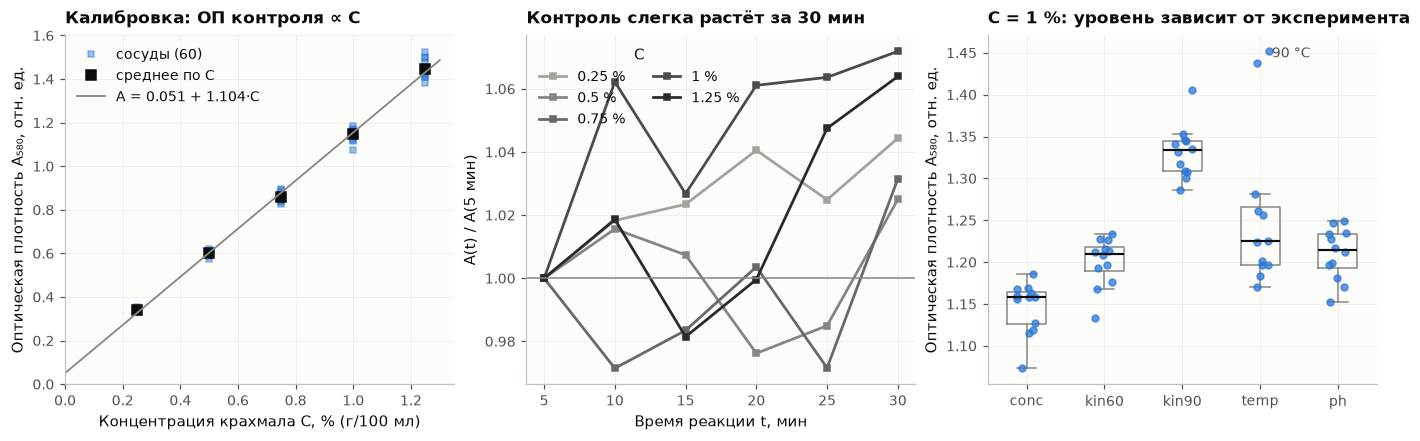

In [10]:
cal = a_ctrl[a_ctrl["experiment"] == "conc"]
cal_means = cal.groupby("substrate_pct")["absorbance"].mean()
lr5 = stats.linregress(cal_means.index, cal_means.values)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9))
ax = axes[0]
ax.plot(cal["substrate_pct"], cal["absorbance"], ls="none", marker="s", markersize=4, alpha=0.45,
        color=pl.TYPE_COLORS["control"], label="сосуды (60)")
ax.plot(cal_means.index, cal_means.values, ls="none", marker="s", markersize=7, color=pl.INK, label="среднее по C")
grid = np.linspace(0, 1.3, 50)
ax.plot(grid, lr5.intercept + lr5.slope * grid, color=pl.MUTED, lw=1.2,
        label=f"A = {lr5.intercept:.3f} + {lr5.slope:.3f}·C")
ax.set(xlabel=pl.AXIS_LABELS["C"], ylabel=pl.AXIS_LABELS["A"], title="Калибровка: ОП контроля ∝ C", xlim=(0, 1.35), ylim=(0, 1.6))
ax.legend(loc="upper left")

ax = axes[1]
for color, (c, g) in zip(pl.ORDINAL5, cal.groupby("substrate_pct")):
    m = g.groupby("time_min")["absorbance"].mean()
    ax.plot(m.index, m.values / m.iloc[0], marker="s", markersize=4, color=color, label=f"{c:g} %")
ax.axhline(1, color=pl.MUTED, lw=1)
ax.set(xlabel=pl.AXIS_LABELS["t"], ylabel="A(t) / A(5 мин)", title="Контроль слегка растёт за 30 мин")
ax.legend(title="C", ncol=2)

ax = axes[2]
c1 = a_ctrl[a_ctrl["substrate_pct"] == 1.0]
order = ["conc", "kin60", "kin90", "temp", "ph"]
pl.strip_by_group(ax, {e: c1.loc[c1["experiment"] == e, "absorbance"].to_numpy() for e in order},
                  {e: pl.TYPE_COLORS["control"] for e in order}, ylabel=pl.AXIS_LABELS["A"],
                  title="C = 1 %: уровень зависит от эксперимента")
t90 = c1[(c1["experiment"] == "temp") & (c1["temperature_c"] == 90)]["absorbance"]
ax.annotate("90 °C", (3.15, t90.mean()), fontsize=9, color=pl.INK2)
plt.show()

**Что видно.**

- **Калибровка.** Средние по уровням $C$ ложатся на прямую почти идеально ($R^2 = 0{,}999$ по пяти средним). Наклон 1,10 ОП на 1 % крахмала. Свободный член около 0,05 ОП; значим ли он, проверяем в Hypothesis Testing.
- **Дрейф во времени.** Без фермента ОП за 25 минут в большинстве серий подрастает на 2–7 %. Возможные причины — испарение воды при термостатировании или медленное доразвитие окраски комплекса. Эффект проверяем как гипотезу.
- **Разные эксперименты.** При одной и той же $C = 1\,\%$ средний уровень контроля различается: 1,15 в концентрационном эксперименте, около 1,2 в kin60, pH- и температурном и 1,33 в kin90. Самые высокие значения — при 90 °C (1,33 в kin90 и 1,44 в температурном эксперименте), где окраска контроля интенсивнее. Поэтому степень гидролиза надо считать только с контролем из того же эксперимента, той же температуры и того же времени. Так мы и делаем.

#### Случайная составляющая $D_\text{к}$: форма распределения

Смотрим на $D_\text{к}$ тремя способами:

- **Гистограмма** — оценка плотности, но её вид зависит от ширины столбцов. Ширину выбираем правилом Фридмана–Диакониса.
- **Эмпирическая функция распределения (ECDF)** — $\hat F(x) = \frac{1}{n}\#\{D_i \le x\}$, доля значений не больше $x$. Не зависит ни от каких настроек, по ней работает критерий Колмогорова–Смирнова.
- **Q-Q-график** — квантили выборки против квантилей теоретического закона. Если закон подходит, точки лежат на прямой. Изгиб на краях означает «тяжёлые» или «лёгкие» хвосты, S-образность — асимметрию.

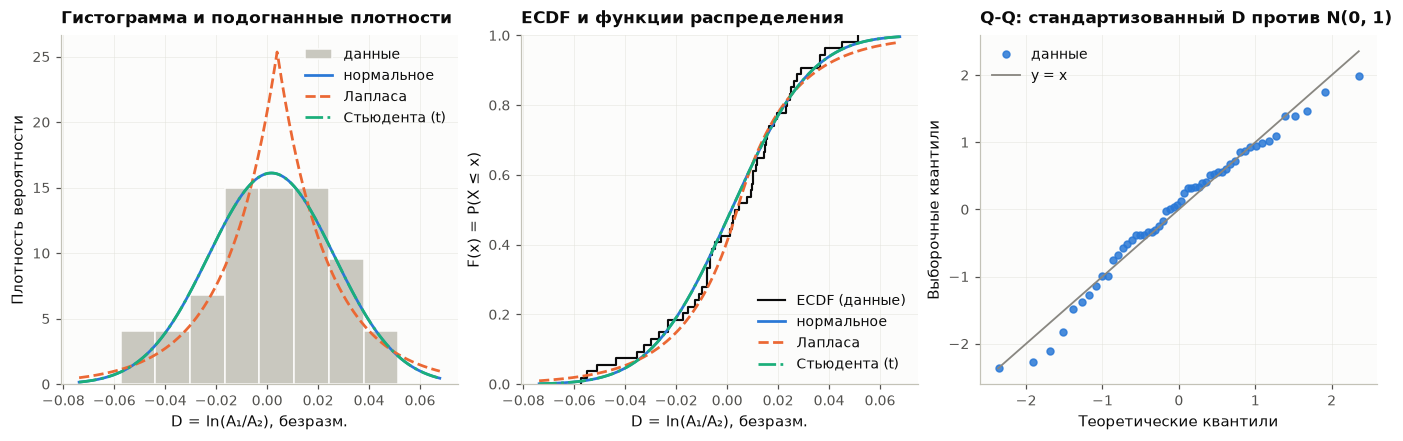

,n,среднее,медиана,дисперсия,SD,минимум,максимум,Q1,Q3,IQR,"CV, %",асимметрия,эксцесс
D_к,54,0.001643,0.00391,0.0006242,0.02498,-0.05748,0.05142,-0.01074,0.01794,0.02868,NaN,-0.4603,-0.0345


In [11]:
D_c = ctrl["log_ratio"].to_numpy()
fits_c = st.fit_candidates(D_c, names=("norm", "laplace", "t"), n_boot=300, seed=SEED)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9))
pl.hist_with_fits(axes[0], D_c, fits_c, xlabel=pl.AXIS_LABELS["D"], title="Гистограмма и подогнанные плотности")
pl.ecdf_with_fits(axes[1], D_c, fits_c, xlabel=pl.AXIS_LABELS["D"], title="ECDF и функции распределения")
pl.qq_plot(axes[2], (D_c - D_c.mean()) / D_c.std(ddof=1), "norm", params=(0, 1),
           title="Q-Q: стандартизованный D против N(0, 1)", color=pl.TYPE_COLORS["control"])
plt.show()
display(st.describe(D_c, cv=False).to_frame("D_к").T)

**Что видно.** Гистограмма одновершинная и почти симметричная. ECDF идёт вдоль функции распределения нормального закона, точки Q-Q-графика лежат на прямой без изгибов на краях. Среднее $D_\text{к}$ близко к нулю (0,0016), эксцесс почти нулевой (−0,03), асимметрия −0,46 — небольшая при $n = 54$.

Коэффициент вариации для $D$ не считаем: у величины со средним около нуля он теряет смысл, потому что делит на почти ноль.

#### Проверка нормальности и сравнение кандидатов

Один тест не решает вопрос о нормальности, поэтому используем четыре — каждый чувствителен к своему отклонению. Нулевая гипотеза везде одна: $H_0$ — выборка из нормального распределения с неизвестными $\mu,\sigma$; уровень значимости $\alpha = 0{,}05$.

Кандидаты выбраны по физике ошибки:

- **нормальный** — сумма многих мелких независимых ошибок (центральная предельная теорема);
- **Лапласа** — острый пик и тяжёлые хвосты, как бывает при смеси условий с разным разбросом;
- **Стьюдента** — тоже тяжёлые хвосты, но с параметром $\nu$, который при $\nu\to\infty$ превращает закон в нормальный.

Параметры оцениваем методом максимального правдоподобия (ММП). Сравниваем по информационному критерию Акаике $\mathrm{AIC} = 2k - 2\ln L$: он штрафует за лишние параметры. Ещё сравниваем по критерию Колмогорова–Смирнова с p-value из параметрического бутстрепа. Обычный КС-тест с оценёнными по той же выборке параметрами даёт завышенный p.

In [12]:
display(st.normality_tests(D_c))
display(fits_c.drop(columns=["параметры", "код"]).set_index("распределение"))
display(st.describe_params(fits_c).to_frame())
display(st.compare_moments(D_c, fits_c))

,тест,статистика,p-value,что проверяет
0,Шапиро–Уилк,0.9765,0.3638,форма в целом; мощный при n < 2000
1,Д'Агостино–Пирсон K²,2.099,0.3501,асимметрия + эксцесс
2,Андерсон–Дарлинг A²,0.3843,0.15,"хвосты; p по таблицам, обрезан до 0,01–0,15"
3,"Лиллиефорс (КС с оценёнными μ, σ)",0.08568,0.4374,максимальное расхождение ECDF и CDF


,lnL,AIC,BIC,D (КС),"p (КС, бутстреп)",ΔAIC
распределение,,,,,,
нормальное,123.1,-242.2,-238.3,0.0868,0.3887,0
Лапласа,120.6,-237.3,-233.3,0.08586,0.5017,4.937
Стьюдента (t),123.1,-240.2,-234.3,0.0868,0.3289,2


,оценки параметров (ММП)
нормальное,"μ = 0.0016, σ = 0.0248"
Лапласа,"μ = 0.0039, b = 0.0197"
Стьюдента (t),"ν = 193094920.77, μ = 0.0016, s = 0.0248"


,выборка,нормальное,Лапласа,Стьюдента (t)
среднее,0.001643,0.001643,0.00391,0.001643
SD,0.02498,0.02475,0.02785,0.02475
асимметрия,-0.4603,0,0,0
эксцесс,-0.0345,0,3,3.107e-08
Q 5 %,-0.04641,-0.03907,-0.04144,-0.03907
Q 25 %,-0.01074,-0.01505,-0.009742,-0.01505
медиана,0.00391,0.001643,0.00391,0.001643
Q 75 %,0.01794,0.01834,0.01756,0.01834
Q 95 %,0.03712,0.04236,0.04926,0.04236


**Что видно.**

- **Нормальность не отвергается** ни одним из четырёх тестов: Шапиро–Уилк $p = 0{,}36$, Д'Агостино $p = 0{,}35$, Андерсон–Дарлинг $A^2 = 0{,}38$ ($p \ge 0{,}15$), Лиллиефорс $p = 0{,}44$. Это не доказывает, что $D_\text{к}$ нормальна: при $n = 54$ тесты не заметят слабых отклонений. Но явных противоречий с нормальной моделью нет.
- **Сравнение кандидатов.** Нормальный закон имеет наименьший AIC. Распределение Стьюдента ушло в $\nu\to\infty$, то есть само превратилось в нормальное и проиграло только штраф за лишний параметр ($\Delta\mathrm{AIC} = 2$). Лаплас хуже на $\Delta\mathrm{AIC} \approx 5$. КС-тест не отвергает ни одного кандидата — при такой выборке он малочувствителен, поэтому решают AIC и физика.
- **Моменты** нормальной модели совпадают с выборочными: среднее, SD, квантили 25–75 %. Эксцесс Лапласа равен 3, а у данных около 0 — это ещё один аргумент против него.

**Выбор: $D_\text{к} \sim N(\mu, \sigma_D^2)$** с $\hat\mu = 0{,}0016$, $\hat\sigma_D = 0{,}025$. Относительная ошибка одного сосуда контроля $\hat\sigma = 0{,}025/\sqrt2 \approx 1{,}8\,\%$.

#### Математическая база нормального распределения

Плотность и функция распределения $N(\mu, \sigma^2)$:

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}\exp\!\left(-\frac{(x-\mu)^2}{2\sigma^2}\right), \qquad F(x) = \Phi\!\left(\frac{x-\mu}{\sigma}\right), \quad \Phi(z) = \int_{-\infty}^{z}\frac{e^{-u^2/2}}{\sqrt{2\pi}}\,du.$$

Свойства, на которые мы опираемся:

1. $\mathbb E X = \mu$, $\operatorname{Var} X = \sigma^2$, асимметрия 0, избыточный эксцесс 0. Медиана и мода совпадают со средним.
2. **Сумма и разность независимых нормальных величин нормальна**, дисперсии складываются. Поэтому $D = \delta_1 - \delta_2 \sim N(0, 2\sigma^2)$.
3. **Центральная предельная теорема.** Сумма многих независимых малых ошибок (пипетка, навеска, кювета, фотометр) приближённо нормальна, какими бы ни были отдельные ошибки. Это физическая причина ожидать нормальный шум.
4. **Связь с логнормальным законом.** Если $\ln A \sim N(m, s^2)$, то сама $A$ логнормальна: $\mathbb E A = e^{m + s^2/2}$, $\mathrm{CV}(A) = \sqrt{e^{s^2}-1} \approx s$. Так выглядит распределение ОП одного условия. При $s \approx 0{,}02$ логнормальный и нормальный законы для $A$ практически неразличимы, но для анализа удобна логарифмическая шкала: на ней разброс не зависит от уровня.
5. Правило трёх сигм: в $\mu\pm\sigma$, $\mu\pm2\sigma$ и $\mu\pm3\sigma$ лежит 68,3 %, 95,4 % и 99,7 % значений.

#### Стандартизация (нормализация)

Стандартизация переводит величину в «единицы стандартного отклонения»:

$$Z = \frac{X - \mu}{\sigma}.$$

Если $X \sim N(\mu, \sigma^2)$, то $Z \sim N(0, 1)$ — стандартное нормальное распределение. Зачем это нужно:

- величины разной природы и масштаба (ОП контроля и ОП пробы) становятся сравнимыми;
- можно пользоваться одной таблицей $\Phi(z)$;
- выбросы сразу видны как $|z| > 3$;
- Q-Q-график строится против одного эталона.

Преобразование корректно для любой величины с конечной дисперсией: среднее 0 и SD 1 получатся всегда. Но $Z$ будет *стандартным нормальным* только при нормальном $X$. Когда $\mu$ и $\sigma$ заменены выборочными оценками, $Z$ лишь приблизительно $N(0,1)$; точное распределение отношения $(X-\bar X)/s$ связано с распределением Стьюдента.

In [13]:
z_c = (D_c - D_c.mean()) / D_c.std(ddof=1)
share = pd.DataFrame({
    "доля в данных": [np.mean(np.abs(z_c) <= k) for k in (1, 2, 3)],
    "N(0, 1)": [2 * stats.norm.cdf(k) - 1 for k in (1, 2, 3)],
}, index=["|z| ≤ 1", "|z| ≤ 2", "|z| ≤ 3"])
print(f"После стандартизации: среднее = {z_c.mean():.2e}, SD = {z_c.std(ddof=1):.3f}, "
      f"max |z| = {np.abs(z_c).max():.2f}")
display(share)

После стандартизации: среднее = -3.71e-17, SD = 1.000, max |z| = 2.37


,доля в данных,"N(0, 1)"
|z| ≤ 1,0.7222,0.6827
|z| ≤ 2,0.9444,0.9545
|z| ≤ 3,1,0.9973


**Что видно.** После стандартизации среднее 0 и SD 1, как и должно быть. В пределах ±1, ±2 и ±3 SD лежит 72 %, 94 % и 100 % значений против 68 %, 95 % и 99,7 % у $N(0,1)$. Для 54 наблюдений это хорошее совпадение. Выбросов ($|z| > 3$) нет: максимальное $|z| = 2{,}4$.

<a id="rv1-independence"></a>
### Independence & Estimations

#### Независимы ли наблюдения $D_\text{к}$

Все дальнейшие методы — подбор закона, тесты, выборки — предполагают, что наблюдения независимы. Сосуды разные, но независимость надо проверить, а не предположить. Проверяем тремя способами:

1. **Однофакторный дисперсионный анализ по сериям** — отличаются ли средние $D_\text{к}$ в разных сериях (одно приготовление растворов). Если отличаются, у сосудов одной серии есть общая ошибка, и наблюдения внутри серии зависимы. Силу зависимости покажет **внутриклассовая корреляция** ICC — доля дисперсии, общая для наблюдений одной серии. ICC = 0 — полная независимость, ICC = 1 — внутри серии все одинаковы.
2. **Тест серий Вальда–Вольфовица и автокорреляция** — случайно ли чередуются значения выше и ниже медианы в порядке записи.
3. **Связь $|D|$ с уровнем ОП** (корреляция Спирмена) — проверка, что на логарифмической шкале разброс не зависит от уровня.

Нулевая корреляция ещё не означает независимости: она ловит только линейную связь. Поэтому смотрим и на средние по группам, и на последовательность, и на разброс.

,n,среднее D,SD D
series,,,
conc 0.25 %,6,-0.03347,0.02165
conc 0.5 %,6,0.001624,0.02018
conc 0.75 %,6,-0.01608,0.01621
conc 1 %,6,0.008185,0.01937
conc 1.25 %,6,0.004129,0.01377
kin60,6,0.02406,0.01024
kin90,6,0.02536,0.02285
ph,6,-0.00741,0.02217
temp,6,0.008385,0.02117


,групп (серий),наблюдений,F (ANOVA),p (ANOVA),τ (SD эффекта серии),σ_e (SD внутри серии),ICC
D_к по 9 сериям,9,54,5.756,4.669e-05,0.01697,0.01906,0.4422


Тест серий: z = -1.92, p = 0.054; автокорреляция лага 1 = 0.45
Спирмен |D| vs уровень ОП: ρ = -0.09, p = 0.51
Шапиро–Уилк для остатков внутри серий: p = 0.13


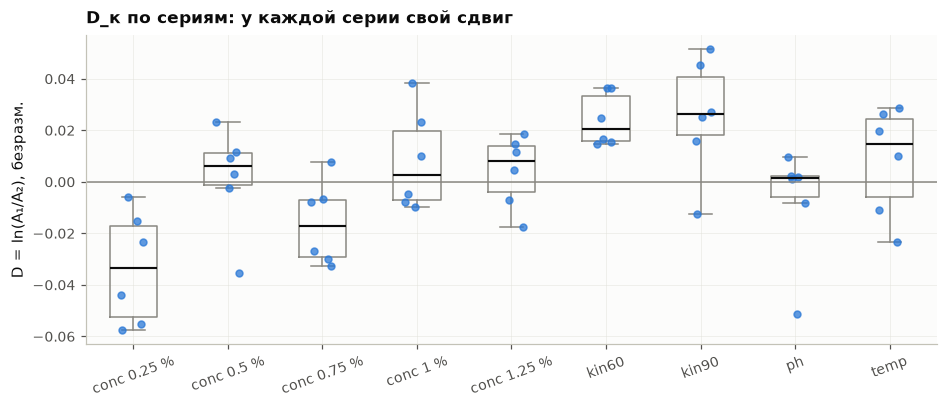

In [14]:
by_series = ctrl.groupby("series")["log_ratio"].agg(["count", "mean", "std"]).rename(
    columns={"count": "n", "mean": "среднее D", "std": "SD D"})
display(by_series)
icc_c = st.random_effects_icc(ctrl["log_ratio"], ctrl["series"])
display(icc_c.to_frame("D_к по 9 сериям").T)
z_runs, p_runs = st.runs_test(D_c)
rho_lvl = stats.spearmanr(ctrl["mean"], np.abs(D_c))
print(f"Тест серий: z = {z_runs:.2f}, p = {p_runs:.3f}; автокорреляция лага 1 = {st.lag1_autocorrelation(D_c):.2f}")
print(f"Спирмен |D| vs уровень ОП: ρ = {rho_lvl.statistic:.2f}, p = {rho_lvl.pvalue:.2f}")
resid_c = ctrl["log_ratio"] - ctrl.groupby("series")["log_ratio"].transform("mean")
print(f"Шапиро–Уилк для остатков внутри серий: p = {stats.shapiro(resid_c).pvalue:.2f}")

fig, ax = plt.subplots(figsize=(8.5, 3.6))
series_order = by_series.index.tolist()
pl.strip_by_group(ax, {s: ctrl.loc[ctrl["series"] == s, "log_ratio"].to_numpy() for s in series_order},
                  {s: pl.TYPE_COLORS["control"] for s in series_order}, ylabel=pl.AXIS_LABELS["D"],
                  title="D_к по сериям: у каждой серии свой сдвиг")
ax.axhline(0, color=pl.MUTED, lw=1)
ax.tick_params(axis="x", labelrotation=20)
plt.show()

**Что видно.**

- **Серии различаются.** Однофакторный дисперсионный анализ показывает разные средние $D_\text{к}$ ($p \approx 5\cdot10^{-5}$), ICC ≈ 0,44. Почти половина разброса между двумя сосудами — сдвиг, общий для всей серии. В серии «conc 0,25 %» сосуд 1 стабильно на 3 % ниже сосуда 2, в kin60 и kin90 — на 2–3 % выше.
- **Объяснение.** Видимо, два «ряда» сосудов в каждой серии готовились из разных порций раствора: отдельная навеска, отдельное разбавление. Ошибка приготовления порции одна для всех точек по времени. Отсюда и положительная автокорреляция соседних значений, 0,45, и пограничный тест серий ($p = 0{,}05$).
- **Разброс не зависит от уровня ОП** ($\rho \approx -0{,}09$, $p = 0{,}5$), то есть логарифмическая шкала выбрана верно.

**Что из этого следует для анализа:**

1. Сосуды *независимы как сосуды*, но их ошибки состоят из двух частей: общей для серии ($\tau \approx 0{,}017$) и индивидуальной ($\sigma_e \approx 0{,}019$). Обе на шкале $D$; для одного сосуда делим на $\sqrt2$.
2. Распределение $D_\text{к}$ по всем 54 значениям остаётся честным описанием шума — смеси двух нормальных компонент, которая тоже нормальна. Остатки внутри серий тоже согласуются с нормальным законом (Шапиро–Уилк $p = 0{,}13$).
3. Гипотезы о систематических эффектах проверяем **на уровне серий**: одна серия — одно независимое наблюдение. Иначе общая ошибка серии посчитается много раз, и p-value будет занижен.

#### Состоятельность оценок

**Определение.** Оценка $\hat\theta_n$ параметра $\theta$ по выборке объёма $n$ называется **состоятельной**, если она сходится к истинному значению по вероятности:

$$\forall\varepsilon > 0:\quad \lim_{n\to\infty} P\bigl(|\hat\theta_n - \theta| > \varepsilon\bigr) = 0.$$

**Почему среднее и дисперсия состоятельны.** Для независимых одинаково распределённых наблюдений с конечной дисперсией $\mathbb E\bar X = \mu$ и $\operatorname{Var}\bar X = \sigma^2/n \to 0$. По неравенству Чебышёва

$$P\bigl(|\bar X - \mu| > \varepsilon\bigr) \le \frac{\sigma^2}{n\varepsilon^2} \to 0.$$

Это закон больших чисел. Выборочная дисперсия $s^2 = \frac{1}{n-1}\sum(X_i-\bar X)^2$ несмещённая и тоже состоятельна. Достаточно конечной дисперсии, а при конечном четвёртом моменте её разброс убывает как $1/\sqrt n$. Тогда состоятельно и $s = \sqrt{s^2}$, потому что непрерывная функция состоятельной оценки состоятельна.

**Эксперимент.** Берём модель, выбранную выше: $D \sim N(\hat\mu, \hat\sigma_D^2)$, и считаем её параметры «истинными». Для каждого $n$ генерируем 2000 выборок и смотрим на три вещи: коридор оценок, разброс оценок и долю оценок, промахнувшихся мимо истинного значения больше чем на $\varepsilon$ — это прямо определение выше.

истинное  среднее оценок   смещение  SD оценок    Q 2,5 %  Q 97,5 %     ε  P(|θ̂ − θ| > ε)
оценка     n                                                                                               
SD s       5      0.02498         0.02346  -0.001527   0.008779    0.00833   0.04269 0.005           0.5945
           50     0.02498          0.0249 -8.045e-05   0.002519    0.02012   0.02998 0.005           0.0475
           500    0.02498         0.02496 -2.544e-05  0.0007753    0.02347   0.02646 0.005                0
           2000   0.02498         0.02498 -8.029e-06  0.0003928    0.02426   0.02577 0.005                0
среднее x̄ 5     0.001643        0.001453 -0.0001908    0.01121   -0.01978   0.02314 0.005           0.6465
           50    0.001643        0.001586 -5.744e-05    0.00361  -0.005651  0.008542 0.005            0.164
           500   0.001643        0.001646  2.407e-06   0.001125 -0.0005773  0.003769 0.005                0
           2000  0.001643        0.001632 -1.191e-05  0.0005577  0.0004923  0.002725 0.005                0

Наклон lg(SD оценки) от lg(n): {'среднее x̄': -0.498, 'SD s': -0.515} (теория: −0,5)


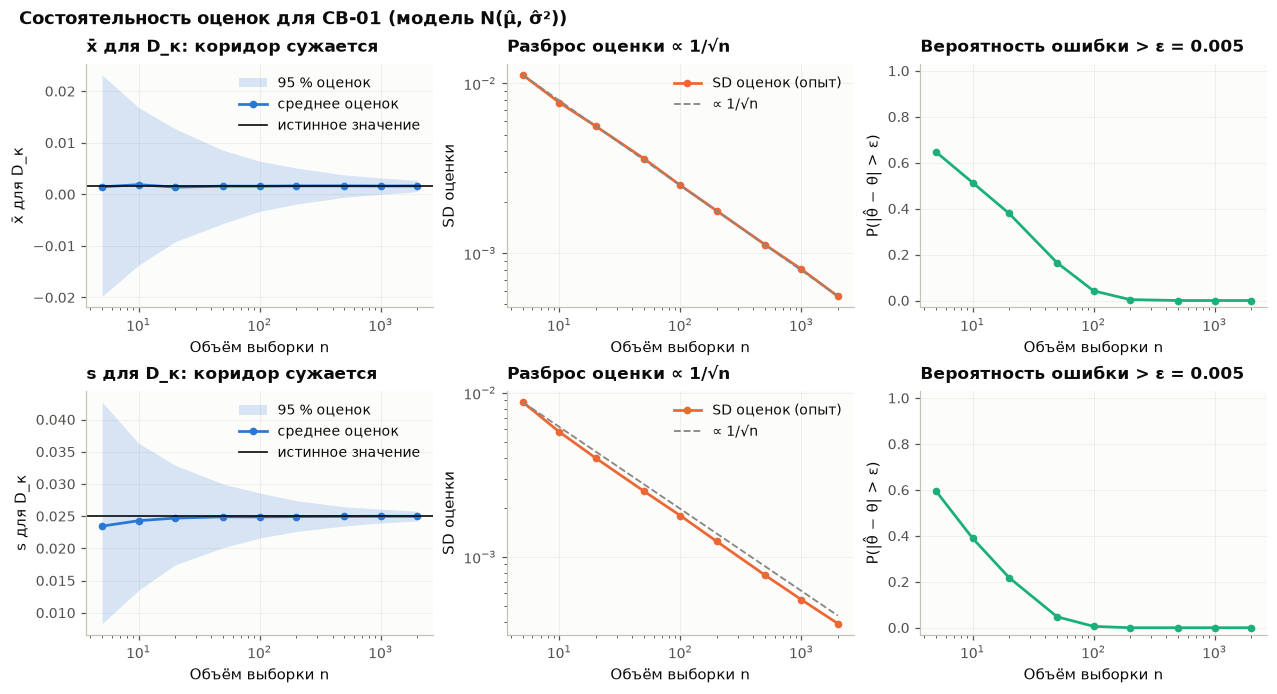

In [15]:
mu_c, sd_c = D_c.mean(), D_c.std(ddof=1)
ns = [5, 10, 20, 50, 100, 200, 500, 1000, 2000]
sim_c = st.consistency_sim(lambda rng, size: rng.normal(mu_c, sd_c, size),
                           {"среднее x̄": lambda s: s.mean(axis=1), "SD s": lambda s: s.std(axis=1, ddof=1)},
                           ns, n_rep=2000, seed=SEED)
summ_c = st.consistency_summary(sim_c, truth={"среднее x̄": mu_c, "SD s": sd_c}, eps={"среднее x̄": 0.005, "SD s": 0.005})
display(summ_c[summ_c["n"].isin([5, 50, 500, 2000])].set_index(["оценка", "n"]))
print("Наклон lg(SD оценки) от lg(n):",
      {e: round(st.loglog_slope(summ_c, e), 3) for e in ["среднее x̄", "SD s"]}, "(теория: −0,5)")
pl.consistency_figure(summ_c, ["среднее x̄", "SD s"], {"среднее x̄": "x̄ для D_к", "SD s": "s для D_к"},
                      "Состоятельность оценок для СВ-01 (модель N(μ̂, σ̂²))")
plt.show()

**Что видно.**

- **Нет смещения.** При любом $n$ средние оценок совпадают с истинными значениями. У $s$ при малых $n$ есть небольшое известное смещение вниз: $\mathbb E s < \sigma$, хотя $\mathbb E s^2 = \sigma^2$. Оно исчезает с ростом $n$.
- **Разброс убывает как $1/\sqrt n$.** Наклон $\lg(\mathrm{SD})$ по $\lg n$ равен −0,5, как предсказывает теория: в 4 раза больше данных — вдвое точнее.
- **Ошибка больше $\varepsilon = 0{,}005$ становится редкой.** Её вероятность падает от 0,6–0,65 при $n = 5$ до нуля при $n \ge 500$. Это и есть сходимость по вероятности.

**Почему график — не доказательство.** Мы видим конечное число $n$ и конечное число повторов. Кроме того, данные сгенерированы из модели, в которой оценки заведомо состоятельны. Эксперимент *иллюстрирует* теорему и проверяет, что наша реализация оценок работает. Доказательство состоятельности — аналитическое: закон больших чисел и неравенство Чебышёва выше. Для реальных $D_\text{к}$ есть оговорка: из-за общего сдвига серий эффективный объём выборки меньше 54, поэтому теорема применяется к сериям, а не к отдельным точкам.

<a id="rv1-sampling"></a>
### Sampling

**Генеральная совокупность.** Здесь это конечное множество из всех 108 измеренных ОП контроля, $N = 108$. Её характеристики известны точно: $\mu = \frac1N\sum x_i$ и $\sigma^2 = \frac1N\sum(x_i-\mu)^2$. Теоретическую модель $N(\mu,\sigma^2)$ из предыдущего раздела здесь не используем, чтобы не смешивать два подхода.

**Две схемы выборки:**

- **с возвращением** — каждый элемент после выбора «возвращается», его можно вытянуть снова. Наблюдения независимы, $\operatorname{Var}\bar x = \sigma^2/n$;
- **без возвращения** — элемент выбирается не более одного раза, как в реальном отборе проб. Наблюдения слегка отрицательно зависимы: если вытянули большое значение, больших осталось меньше. Поэтому

$$\operatorname{Var}\bar x = \frac{\sigma^2}{n}\cdot\frac{N-n}{N-1}.$$

Множитель $\frac{N-n}{N-1}$ — поправка на конечность совокупности (finite population correction, FPC). При $n = N$ выборка без возвращения совпадает с совокупностью, и ошибки нет совсем.

,совокупность (N),с возвращением,без возвращения
n,108,30,30
среднее,1.044,0.9434,1.027
дисперсия,0.1214,0.1307,0.1517
SD,0.3485,0.3615,0.3894
медиана,1.182,1.172,1.167
Q1,0.8432,0.6061,0.6641
Q3,1.266,1.227,1.324
минимум,0.329,0.3366,0.329
максимум,1.523,1.382,1.523
разных элементов,108,23,30


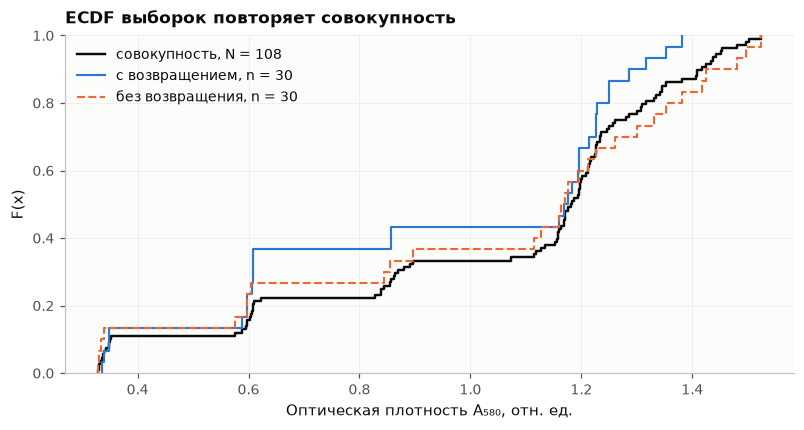

In [16]:
pop1 = a_ctrl["absorbance"].to_numpy()
cmp1, s_with1, s_without1 = st.population_vs_samples(pop1, n=30, seed=SEED)
display(cmp1)

fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.ecdf(pop1, color=pl.INK, lw=1.6, label=f"совокупность, N = {len(pop1)}")
ax.ecdf(s_with1, color=pl.SERIES[0], lw=1.4, label="с возвращением, n = 30")
ax.ecdf(s_without1, color=pl.SERIES[1], lw=1.4, ls="--", label="без возвращения, n = 30")
ax.set(xlabel=pl.AXIS_LABELS["A"], ylabel="F(x)", title="ECDF выборок повторяет совокупность")
ax.legend(loc="upper left")
plt.show()

**Что видно.** Одна выборка $n = 30$ (28 % совокупности) передаёт медиану и диапазон значений. Среднее и первый квартиль отличаются заметно: в выборке с возвращением среднее 0,94 против 1,04, а $Q_1$ около 0,61–0,66 против 0,84. Причина — совокупность состоит из пяти уровней $C$, и нижний квартиль попадает в «провал» между уровнями. Двухвыборочный КС-тест отличий не находит ($p = 0{,}44$ и $0{,}98$), но при $n = 30$ он малочувствителен. В выборке с возвращением только 23 разных элемента из 30: часть сосудов попала дважды. По одной выборке судить рано, поэтому повторим отбор много раз и сравним разброс выборочного среднего с теорией.

,n,доля N,Var с возвр. (опыт),Var с возвр. (теория),Var без возвр. (опыт),Var без возвр. (теория)
0,5,0.0463,0.02469,0.02429,0.02283,0.02338
1,10,0.09259,0.01178,0.01214,0.01126,0.01112
2,20,0.1852,0.00601,0.006072,0.005123,0.004994
3,30,0.2778,0.004044,0.004048,0.002905,0.002951
4,50,0.463,0.002397,0.002429,0.001315,0.001317
5,75,0.6944,0.001599,0.001619,0.0004976,0.0004994
6,100,0.9259,0.001194,0.001214,9.309e-05,9.079e-05


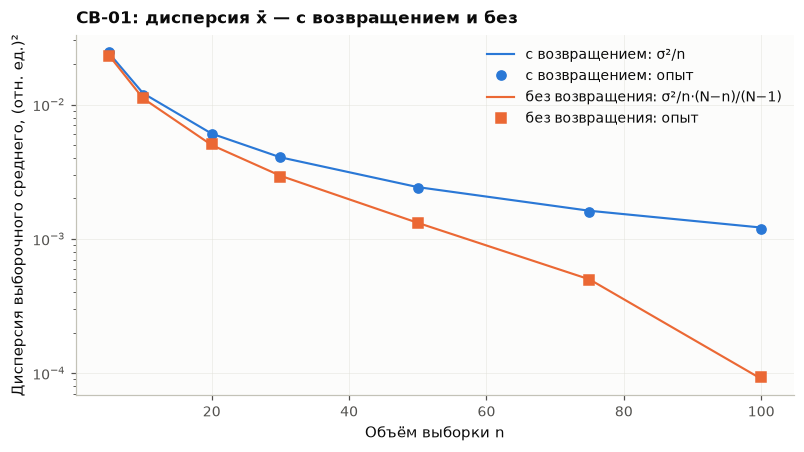

Размещение стратифицированной выборки по C: {'0.25 %': 4, '0.5 %': 3, '0.75 %': 3, '1 %': 17, '1.25 %': 3}


,схема,среднее оценок,SD оценок,истинное среднее
0,простая случайная,1.045,0.05459,1.044
1,стратифицированная,1.044,0.009511,1.044


In [17]:
samp1 = st.sampling_distribution(pop1, ns=[5, 10, 20, 30, 50, 75, 100], n_rep=5000, seed=SEED)
display(samp1)
pl.sampling_figure(samp1, "отн. ед.", "СВ-01: дисперсия x̄ — с возвращением и без")
plt.show()
strat1, alloc1 = st.stratified_vs_simple(pop1, a_ctrl["substrate_pct"].to_numpy(), n=30, n_rep=5000, seed=SEED)
print("Размещение стратифицированной выборки по C:", {f"{k:g} %": int(v) for k, v in alloc1.items()})
display(strat1)

**Что видно.**

- **Теория сходится с опытом.** Эмпирические дисперсии среднего совпадают с формулами для обеих схем.
- **Без возвращения точнее.** Разница растёт с долей выборки: при $n = 100$ из 108 дисперсия без возвращения почти в 13 раз меньше. При малых $n$ схемы практически не различаются, потому что $\frac{N-n}{N-1} \approx 1$.
- **Стратификация.** Совокупность состоит из пяти уровней $C$, разброс между ними огромный. Если брать элементы из каждого уровня пропорционально его доле (стратифицированная выборка), SD оценки среднего падает почти в 6 раз (0,0095 против 0,055) по сравнению с простой случайной выборкой того же объёма. Вывод для планирования опытов: если совокупность неоднородна, выборку надо строить по слоям.

<a id="rv1-hypotheses"></a>
### Hypothesis Testing

Проверяем три гипотезы. Уровень значимости $\alpha = 0{,}05$. Поправка на множественные сравнения по методу Холма делается в [Lab resume](#resume) для всех гипотез сразу, здесь — исходные p-value. Единица анализа — серия, по причинам из раздела Independence.

#### H1.1. Растёт ли ОП контроля со временем

- $H_0$: средний наклон $\ln A_\text{к}$ по времени равен 0 (дрейфа нет);
- $H_1$: наклон $\ne 0$.

**Метод — анализ сводных показателей.** В каждой из 7 кинетических серий подбираем прямую $\ln\bar A_\text{к}(t)$ по шести точкам, её наклон — одно наблюдение. Семь наклонов независимы, потому что серии готовились отдельно. Проверяем одновыборочным t-тестом, что их среднее равно 0. Применимость t-теста — приблизительная нормальность наклонов — проверяем тестом Шапиро–Уилка.

In [18]:
kin_ctrl = ctrl[ctrl["experiment"].isin(["conc", "kin60", "kin90"])]
slopes = kin_ctrl.groupby("series").apply(lambda g: np.polyfit(g["time_min"], np.log(g["mean"]), 1)[0], include_groups=False)
slopes_tbl = pd.DataFrame({"наклон, 1/мин": slopes, "изменение за 25 мин, %": 100 * (np.exp(25 * slopes) - 1)})
display(slopes_tbl)
h11 = stats.ttest_1samp(slopes, 0.0)
ci11 = h11.confidence_interval(0.95)
print(f"t = {h11.statistic:.2f}, df = {h11.df}, p = {h11.pvalue:.4f}; Шапиро–Уилк для наклонов: p = {stats.shapiro(slopes).pvalue:.2f}")
print(f"Средний дрейф за 25 мин: {100 * (np.exp(25 * slopes.mean()) - 1):.1f} %, "
      f"95 % ДИ: {100 * (np.exp(25 * ci11.low) - 1):.1f}…{100 * (np.exp(25 * ci11.high) - 1):.1f} %")

,"наклон, 1/мин","изменение за 25 мин, %"
series,,
conc 0.25 %,0.001445,3.68
conc 0.5 %,-6.491e-07,-0.001623
conc 0.75 %,0.001003,2.539
conc 1 %,0.002194,5.639
conc 1.25 %,0.002354,6.061
kin60,0.001152,2.922
kin90,-0.0001037,-0.2588


t = 3.16, df = 6, p = 0.0195; Шапиро–Уилк для наклонов: p = 0.47
Средний дрейф за 25 мин: 2.9 %, 95 % ДИ: 0.7…5.2 %


**Результат.** Наклон положителен в 5 сериях из 7. Средний дрейф +2,9 % за 25 минут, 95 % ДИ от +0,7 до +5,2 %. $t = 3{,}16$ при 6 степенях свободы, $p = 0{,}019 < 0{,}05$, так что $H_0$ отвергается до поправки на множественность. Наклоны согласуются с нормальным законом.

**Химическая интерпретация.** Без фермента ОП контроля медленно растёт — на 1–3 % за полчаса. Возможные причины: испарение воды при термостатировании (концентрирование раствора) или медленное доразвитие окраски йод-крахмального комплекса. При 90 °C и в серии 0,5 % дрейфа нет. На степень гидролиза эффект почти не влияет, потому что контроль берётся в ту же минуту, что и проба. Но для точных измерений время между добавлением йода и измерением стоит фиксировать.

#### H1.2. Есть ли у калибровки свободный член — фоновое поглощение

- $H_0$: в модели $A_\text{к} = a + bC$ свободный член $a = 0$, ОП строго пропорциональна крахмалу;
- $H_1$: $a \ne 0$.

Это важно для формулы степени гидролиза: $X = (A_\text{к}-A_\text{п})/A_\text{к}$ верна только при $a = 0$. Сравниваем две модели, и разница между ними — урок про псевдоповторности.

In [19]:
m_vessels = smf.ols("absorbance ~ substrate_pct", data=cal).fit()
m_hc3 = smf.ols("absorbance ~ substrate_pct", data=cal).fit(cov_type="HC3")
lof = sm.stats.anova_lm(m_vessels, smf.ols("absorbance ~ C(substrate_pct)", data=cal).fit())
t5 = lr5.intercept / lr5.intercept_stderr
calib = pd.DataFrame({
    "a (свободный член)": [m_vessels.params["Intercept"], m_hc3.params["Intercept"], lr5.intercept],
    "SE(a)": [m_vessels.bse["Intercept"], m_hc3.bse["Intercept"], lr5.intercept_stderr],
    "p": [m_vessels.pvalues["Intercept"], m_hc3.pvalues["Intercept"], 2 * stats.t.sf(abs(t5), df=3)],
    "b (наклон)": [m_vessels.params["substrate_pct"], m_hc3.params["substrate_pct"], lr5.slope],
    "R²": [m_vessels.rsquared, m_hc3.rsquared, lr5.rvalue ** 2],
    "наблюдений": [len(cal), len(cal), 5],
}, index=["МНК по 60 сосудам", "то же, SE HC3", "МНК по 5 средним (серии)"])
display(calib)
print(f"Проверка адекватности линейной модели (lack-of-fit): F = {lof['F'].iloc[1]:.2f}, p = {lof['Pr(>F)'].iloc[1]:.4f}")

,a (свободный член),SE(a),p,b (наклон),R²,наблюдений
МНК по 60 сосудам,0.0509,0.008884,3.786e-07,1.104,0.9946,60
"то же, SE HC3",0.0509,0.007109,8.044e-13,1.104,0.9946,60
МНК по 5 средним (серии),0.0509,0.01787,0.0652,1.104,0.9989,5


Проверка адекватности линейной модели (lack-of-fit): F = 4.85, p = 0.0046


**Результат.** Обе модели дают одну и ту же оценку $a = 0{,}051$, но совсем разную уверенность в ней:

- **по 60 сосудам** $p < 10^{-6}$, и устойчивые к неоднородности дисперсии ошибки HC3 это не меняют;
- **по 5 средним** $p = 0{,}065$.

Правильна вторая модель. Каждая концентрация — своя серия со своим приготовлением раствора, поэтому ошибка приготовления общая для всех 12 сосудов уровня. Значит, независимых точек калибровки пять, а не шестьдесят. Тест на адекватность (lack-of-fit, $p = 0{,}005$) это подтверждает: средние уровней отклоняются от прямой сильнее, чем разрешает разброс внутри уровня. Это и есть ошибка приготовления каждой серии.

**Вывод.** При $\alpha = 0{,}05$ нулевую гипотезу не отвергаем. Фоновое поглощение около 0,05 ОП возможно, но по этим данным не доказано. Отсутствие значимости не доказывает, что $a = 0$: при пяти точках у теста низкая мощность. Для ответа нужен прямой «бланк» — раствор йода без крахмала. Если фон есть, формула занижает $X$ примерно на 4 % относительных при $C = 1\,\%$ и на 15 % при $C = 0{,}25\,\%$.

#### H1.3. Отличаются ли систематически сосуды 1 и 2 у контроля

- $H_0$: среднее $D_\text{к}$ по сериям равно 0, порядковой разницы сосудов нет;
- $H_1$: $\ne 0$.

Единица анализа — среднее $D_\text{к}$ серии (9 значений). Используем t-тест и точный знаково-ранговый тест Уилкоксона, который не требует нормальности.

In [20]:
series_mean_c = ctrl.groupby("series")["log_ratio"].mean()
h13_t = stats.ttest_1samp(series_mean_c, 0.0)
h13_w = stats.wilcoxon(series_mean_c, method="exact")
print(f"Серий с A1 < A2: {(series_mean_c < 0).sum()} из {len(series_mean_c)}; t-тест p = {h13_t.pvalue:.2f}; "
      f"Уилкоксон p = {h13_w.pvalue:.2f}")

Серий с A1 < A2: 3 из 9; t-тест p = 0.80; Уилкоксон p = 0.65


**Результат.** Знаки средних по сериям случайны: $A_1 < A_2$ в 3 сериях из 9, $p = 0{,}80$ по t-тесту и $p = 0{,}65$ по Уилкоксону. $H_0$ не отвергается: у контроля систематической разницы между сосудами 1 и 2 не видно. Это пригодится в СВ-02, где у проб с ферментом такая разница есть.

<a id="rv1-resume"></a>
### Resume

1. **Природа.** ОП контроля определяется концентрацией крахмала (прямая $A = 0{,}051 + 1{,}104\,C$), но при одних условиях два сосуда дают разные значения. Значит, $A_\text{к}$ — случайная величина. Её ошибка мультипликативная: CV 2–3 % при любой $C$.
2. **Распределение.** Случайная составляющая $D_\text{к} = \ln(A_1/A_2)$ согласуется с нормальным законом $N(0{,}0016;\ 0{,}025^2)$. Четыре теста нормальность не отвергают, AIC лучший, моменты совпадают. Относительная ошибка одного сосуда около 1,8 %. После стандартизации получаем $N(0,1)$ с ожидаемыми долями ±1/±2/±3 SD.
3. **Независимость.** Сосуды разные, но около 44 % разброса — общий сдвиг серии (ICC = 0,44), то есть ошибка приготовления порции раствора. Поэтому систематические эффекты проверяем на уровне серий.
4. **Состоятельность.** $\bar x$ и $s$ сходятся к истинным значениям, разброс $\propto 1/\sqrt n$, вероятность ошибки больше $\varepsilon$ стремится к 0. Это иллюстрация закона больших чисел, а не его доказательство.
5. **Выборки.** 30 элементов из 108 воспроизводят характеристики совокупности. Без возвращения оценка точнее (FPC), стратификация по $C$ уменьшает разброс почти в 6 раз.
6. **Гипотезы.** Дрейф контроля +2,9 % за 25 мин ($p = 0{,}019$ до поправки). Фон калибровки 0,05 ОП не доказан ($p = 0{,}065$, нужен бланк). Порядкового эффекта у контроля нет.

<a id="rv2"></a>
## Random Variable 02 — оптическая плотность пробы с ферментом $A_\text{п}$

<a id="rv2-description"></a>
### Description

**Определение.** $A_\text{п}$ — ОП при 580 нм сосуда, в котором крахмал инкубировали с глюкоамилазой: свободной или иммобилизованной (циклы 1–3). Измерена в 142 условиях по 2 сосуда, всего 284 значения.

**Физический смысл.** Это крахмал, оставшийся к моменту измерения. Чем активнее фермент и чем дольше реакция, тем меньше $A_\text{п}$. Возможные значения — от нуля (крахмал гидролизован полностью) до уровня контроля (гидролиза нет).

**Стохастическая природа.** К источникам случайности контроля (СВ-01) добавляются источники, связанные с реакцией:

- дозирование фермента и момент его добавления;
- точность момента остановки реакции и выход сосуда на температуру;
- для иммобилизованного фермента — разное количество фермента на носителе, его частичная десорбция, диффузия крахмала в поры TiO₂.

Систематическая часть $\mu(T, \mathrm{pH}, C, t, E, k)$ здесь — кинетика реакции, и сложную функцию от шести факторов мы не моделируем. Случайную составляющую выделяем, как в СВ-01, разностью логарифмов двух сосудов одного условия: $D_\text{п} = \ln(A_1/A_2)$.

СВ-02 одной природы с СВ-01 (обе — оптическая плотность того же раствора йод-крахмального комплекса), поэтому в разделе Independence проверяем их взаимную зависимость.

<a id="rv2-eda"></a>
### EDA & Distribution

In [21]:
a_enz = used[used["sample_type"] != "control"].copy()
a_enz["group"] = np.where(a_enz["sample_type"] == "free", "свободный",
                          np.where(a_enz["cycle"] == 1, "иммоб., цикл 1", "иммоб., циклы 2–3"))
display(st.describe_groups({"все 284": a_enz["absorbance"],
                            **{g: v["absorbance"] for g, v in a_enz.groupby("group")}}).T)

,n,среднее,медиана,дисперсия,SD,минимум,максимум,Q1,Q3,IQR,"CV, %",асимметрия,эксцесс
все 284,284,0.764,0.8233,0.1355,0.3681,0.09537,1.497,0.4453,1.091,0.6459,48.18,-0.2669,-1.23
"иммоб., цикл 1",108,0.6841,0.6828,0.1264,0.3556,0.09537,1.318,0.3457,0.995,0.6492,51.98,0.03217,-1.254
"иммоб., циклы 2–3",68,1.037,1.088,0.06124,0.2475,0.3226,1.497,1.035,1.152,0.1174,23.87,-1.514,2.399
свободный,108,0.6721,0.6975,0.1314,0.3624,0.09795,1.289,0.3326,1.01,0.6777,53.93,0.02314,-1.25


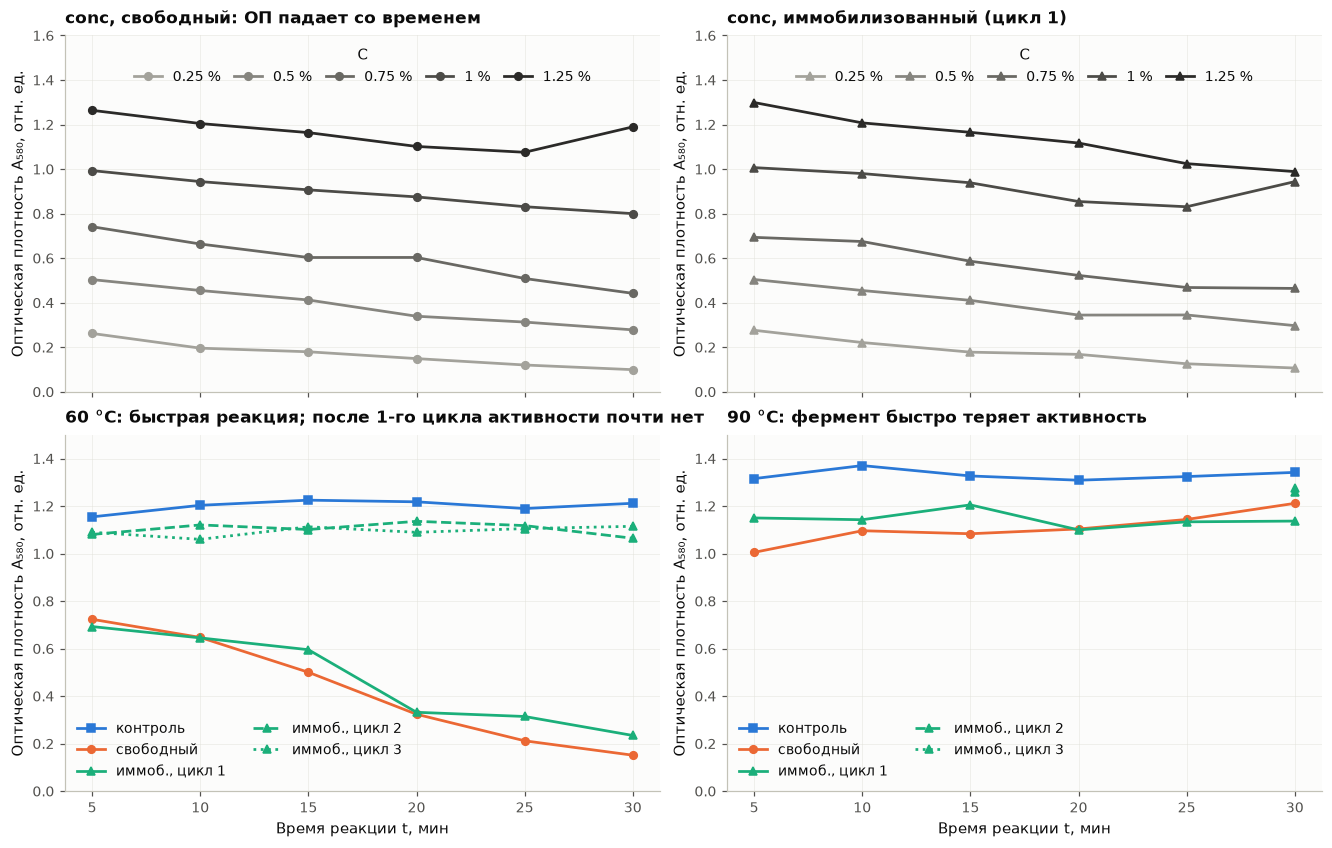

In [22]:
def curve(df, **flt):
    for k, v in flt.items():
        df = df[df[k] == v]
    return df.sort_values("time_min")

fig, axes = plt.subplots(2, 2, figsize=(12, 7.6), sharex=True)
for ax, tp, title in [(axes[0, 0], "free", "conc, свободный: ОП падает со временем"),
                      (axes[0, 1], "immobilized", "conc, иммобилизованный (цикл 1)")]:
    for color, c in zip(pl.ORDINAL5, [0.25, 0.5, 0.75, 1.0, 1.25]):
        d = curve(pairs, experiment="conc", sample_type=tp, substrate_pct=c, cycle=1)
        ax.plot(d["time_min"], d["mean"], marker=pl.TYPE_MARKERS[tp], markersize=5, color=color, label=f"{c:g} %")
    ax.set(ylabel=pl.AXIS_LABELS["A"], title=title, ylim=(0, 1.6))
    ax.legend(title="C", ncol=5, loc="upper center", columnspacing=1.0)
for ax, exp, title in [(axes[1, 0], "kin60", "60 °C: быстрая реакция; после 1-го цикла активности почти нет"),
                       (axes[1, 1], "kin90", "90 °C: фермент быстро теряет активность")]:
    d = curve(pairs, experiment=exp, sample_type="control")
    ax.plot(d["time_min"], d["mean"], marker="s", markersize=5, color=pl.TYPE_COLORS["control"], label="контроль")
    d = curve(pairs, experiment=exp, sample_type="free")
    ax.plot(d["time_min"], d["mean"], marker="o", markersize=5, color=pl.TYPE_COLORS["free"], label="свободный")
    for cyc, ls in [(1, "-"), (2, "--"), (3, ":")]:
        d = curve(pairs, experiment=exp, sample_type="immobilized", cycle=cyc)
        ax.plot(d["time_min"], d["mean"], marker="^", markersize=5, ls=ls, color=pl.TYPE_COLORS["immobilized"],
                label=f"иммоб., цикл {cyc}")
    ax.set(xlabel=pl.AXIS_LABELS["t"], ylabel=pl.AXIS_LABELS["A"], title=title, ylim=(0, 1.5))
    ax.legend(ncol=2, loc="lower left")
axes[1, 0].set_xticks([5, 10, 15, 20, 25, 30])
plt.show()

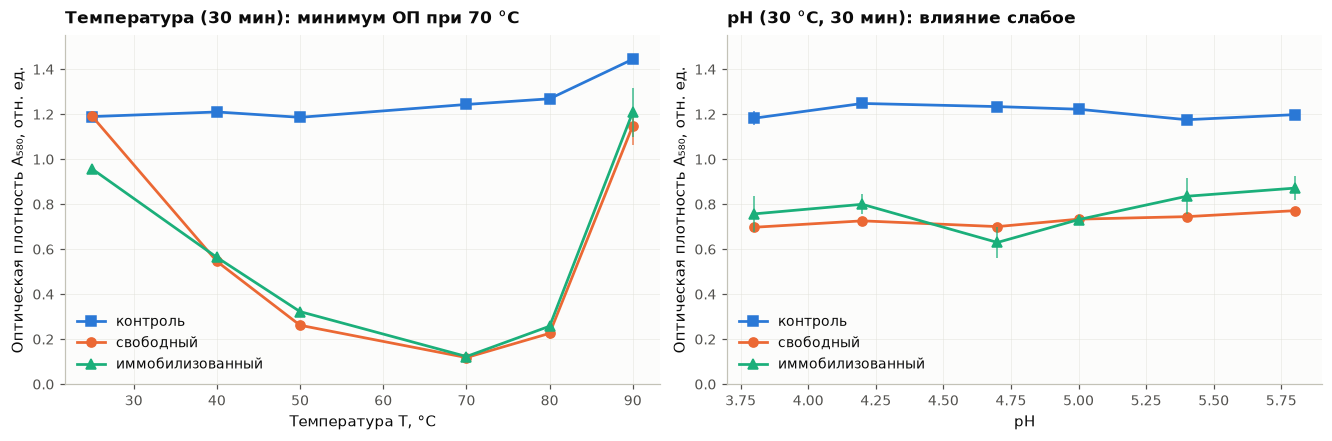

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for ax, exp, fac, xlabel, title in [
        (axes[0], "temp", "temperature_c", pl.AXIS_LABELS["T"], "Температура (30 мин): минимум ОП при 70 °C"),
        (axes[1], "ph", "ph", pl.AXIS_LABELS["pH"], "pH (30 °C, 30 мин): влияние слабое")]:
    for tp in ["control", "free", "immobilized"]:
        d = pairs[(pairs["experiment"] == exp) & (pairs["sample_type"] == tp)].sort_values(fac)
        ax.plot(d[fac], d["mean"], marker=pl.TYPE_MARKERS[tp], markersize=6, color=pl.TYPE_COLORS[tp], label=pl.TYPE_LABELS[tp])
        ax.vlines(d[fac], d[["a1", "a2"]].min(axis=1), d[["a1", "a2"]].max(axis=1), color=pl.TYPE_COLORS[tp], lw=1.2, alpha=0.7)
    ax.set(xlabel=xlabel, ylabel=pl.AXIS_LABELS["A"], title=title, ylim=(0, 1.55))
    ax.legend(loc="lower left")
plt.show()

**Что видно.** Вертикальные отрезки на нижнем графике — размах между двумя сосудами.

- **Описательные статистики.** Вместе 284 значения образуют широкую смесь: ОП от 0,095 до 1,50, CV 48 %. Её форму задают условия опыта, а не случайность. В циклах 2–3 иммобилизованного фермента ОП почти как у контроля: фермент почти не работает.
- **Кинетика.** ОП пробы падает со временем, крахмал расходуется. Чем выше $C$, тем выше вся кривая, а относительное падение больше при малых $C$: фермента столько же, крахмала меньше. Свободный и иммобилизованный фермент в первом цикле ведут себя похоже. Отдельные точки выбиваются из гладкой кривой — например, 1,25 % при 30 мин у свободного фермента и 1 % при 30 мин у иммобилизованного. Это условия, где два сосуда сильно разошлись (см. выбросы ниже).
- **60 °C** — самая быстрая реакция. **90 °C** — после короткого начального гидролиза ОП пробы даже немного растёт, как у контроля: фермент, по-видимому, быстро инактивируется.
- **Температура.** Минимум ОП, то есть максимум гидролиза, при 70 °C. При 25 °C свободный фермент почти не работает: ОП пробы равна контролю.
- **pH.** Влияние заметно слабее, чем у температуры. У иммобилизованного фермента размах между сосудами большой — шум сравним с эффектом.

#### Случайная составляющая $D_\text{п}$

,n,среднее,медиана,дисперсия,SD,минимум,максимум,Q1,Q3,IQR,асимметрия,эксцесс,доля A₁ < A₂
контроль (СВ-01),54,0.001643,0.00391,0.0006242,0.02498,-0.05748,0.05142,-0.01074,0.01794,0.02868,-0.4603,-0.0345,0.4259
свободный,54,-0.02672,-0.02622,0.005056,0.07111,-0.1937,0.2115,-0.05506,-0.002619,0.05244,0.786,2.784,0.7778
"иммоб., цикл 1",54,-0.02173,-0.009485,0.01128,0.1062,-0.3788,0.2155,-0.06683,0.00842,0.07525,-0.154,2.403,0.6852
"иммоб., циклы 2–3",34,-0.06945,-0.06437,0.002425,0.04924,-0.1918,0.02421,-0.0988,-0.03319,0.06561,-0.4909,-0.02276,0.9412


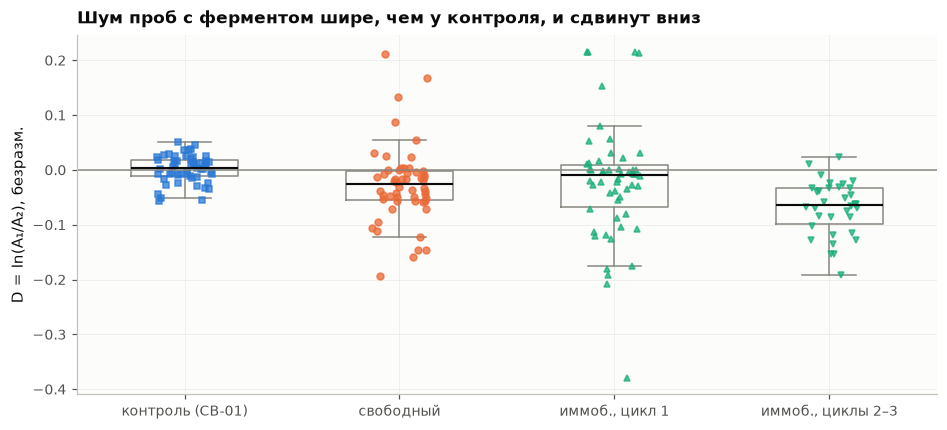

In [24]:
enz["group"] = np.where(enz["sample_type"] == "free", "свободный",
                        np.where(enz["cycle"] == 1, "иммоб., цикл 1", "иммоб., циклы 2–3"))
noise_groups = {"контроль (СВ-01)": ctrl["log_ratio"].to_numpy(),
                **{g: enz.loc[enz["group"] == g, "log_ratio"].to_numpy()
                   for g in ["свободный", "иммоб., цикл 1", "иммоб., циклы 2–3"]}}
tbl = st.describe_groups(noise_groups, cv=False).T.drop(columns="CV, %")
tbl["доля A₁ < A₂"] = [np.mean(v < 0) for v in noise_groups.values()]
display(tbl)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
colors = {"контроль (СВ-01)": pl.TYPE_COLORS["control"], "свободный": pl.TYPE_COLORS["free"],
          "иммоб., цикл 1": pl.TYPE_COLORS["immobilized"], "иммоб., циклы 2–3": pl.TYPE_COLORS["immobilized"]}
markers = {"контроль (СВ-01)": "s", "свободный": "o", "иммоб., цикл 1": "^", "иммоб., циклы 2–3": "v"}
pl.strip_by_group(ax, noise_groups, colors, markers, ylabel=pl.AXIS_LABELS["D"],
                  title="Шум проб с ферментом шире, чем у контроля, и сдвинут вниз")
ax.axhline(0, color=pl.MUTED, lw=1)
plt.show()

**Что видно.**

- **Разброс шире.** SD $D$ у свободного фермента 0,071, у иммобилизованного в первом цикле 0,106 — в 3–4 раза больше, чем у контроля (0,025). Реакция добавляет к ошибкам приготовления свою случайность: старт, остановку, количество фермента.
- **Тяжёлые хвосты.** Избыточный эксцесс 2,4–2,8, а у нормального закона 0. Большинство пар сосудов согласуются хорошо, но есть отдельные сильно расходящиеся: до ±0,2–0,4 по $D$, то есть ОП сосудов различается на 20–45 %.
- **Сдвиг вниз.** Среднее и медиана $D$ отрицательны: сосуд 1 чаще даёт *меньшую* ОП, чем сосуд 2 — в 78 % условий у свободного фермента и в 69 % у иммобилизованного. У контроля доля 43 %, близко к 50 %. Эффект проверяем в Hypothesis Testing.
- **Циклы 2–3** иммобилизованного: шум меньше (0,049) и без тяжёлых хвостов, но сдвиг вниз самый устойчивый — 94 %.

#### Какое распределение у $D_\text{п}$

Подбираем те же три закона отдельно для свободного фермента и для иммобилизованного в первом цикле. Объединять их нельзя: разброс у них разный, и смесь двух законов исказит форму.

— свободный (n = 54)


,тест,статистика,p-value
0,Шапиро–Уилк,0.9115,0.0007215
1,Д'Агостино–Пирсон K²,12.67,0.001771
2,Андерсон–Дарлинг A²,1.763,0.01
3,"Лиллиефорс (КС с оценёнными μ, σ)",0.1851,0.001


,lnL,AIC,BIC,D (КС),"p (КС, бутстреп)",ΔAIC
распределение,,,,,,
нормальное,66.63,-129.3,-125.3,0.1837,0.004975,12.69
Лапласа,72.98,-142,-138,0.1174,0.1045,0
Стьюдента (t),73.63,-141.3,-135.3,0.07899,0.3085,0.6944


,оценки параметров (ММП)
нормальное,"μ = -0.0267, σ = 0.0704"
Лапласа,"μ = -0.0262, b = 0.0476"
Стьюдента (t),"ν = 1.86, μ = -0.0284, s = 0.0345"


— иммобилизованный, цикл 1 (n = 54)


,тест,статистика,p-value
0,Шапиро–Уилк,0.9091,0.000591
1,Д'Агостино–Пирсон K²,6.426,0.04025
2,Андерсон–Дарлинг A²,1.939,0.01
3,"Лиллиефорс (КС с оценёнными μ, σ)",0.1613,0.001842


,lnL,AIC,BIC,D (КС),"p (КС, бутстреп)",ΔAIC
распределение,,,,,,
нормальное,44.96,-85.93,-81.95,0.1597,0.00995,15.23
Лапласа,52.58,-101.2,-97.18,0.161,0.004975,0
Стьюдента (t),51.57,-97.13,-91.16,0.1062,0.0796,4.027


,оценки параметров (ММП)
нормальное,"μ = -0.0217, σ = 0.1052"
Лапласа,"μ = -0.0095, b = 0.0695"
Стьюдента (t),"ν = 1.34, μ = -0.0147, s = 0.0411"


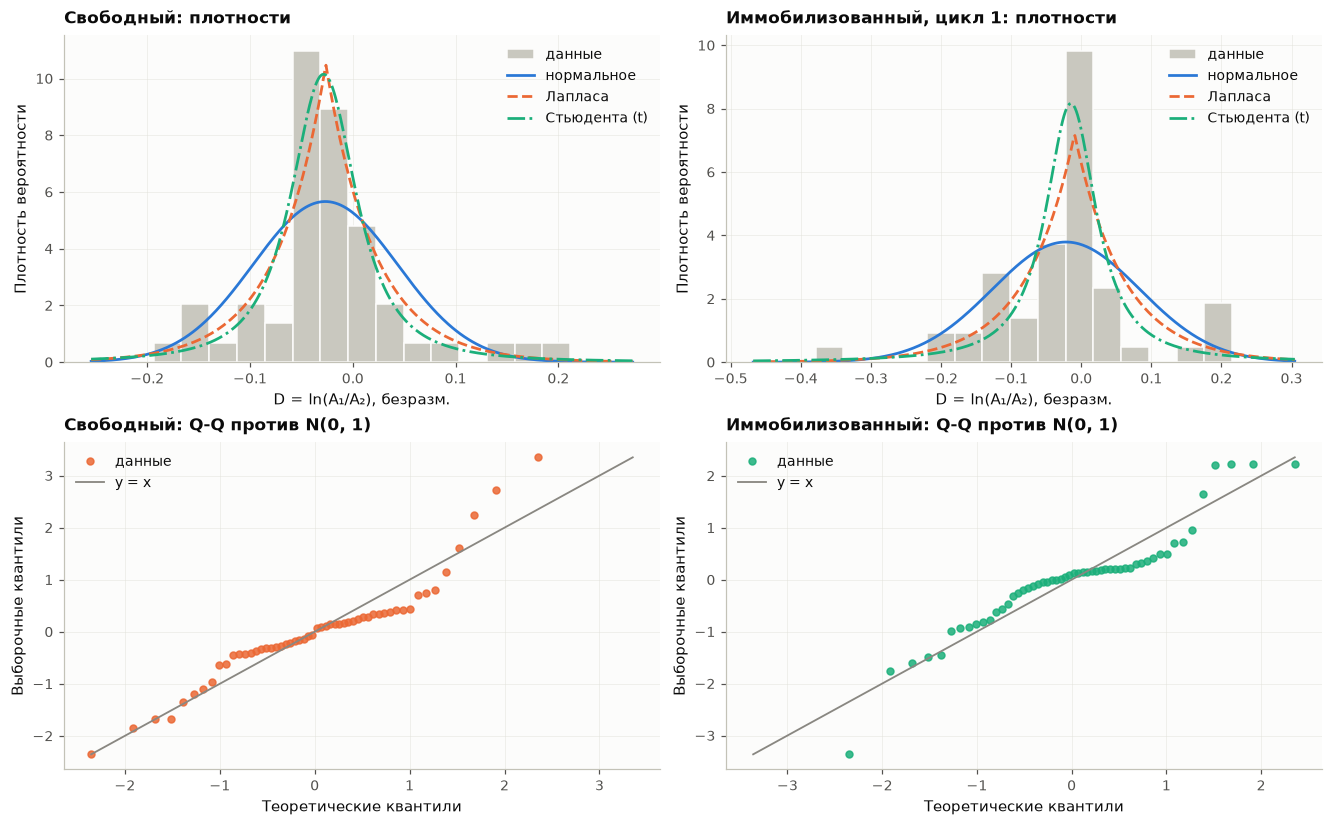

In [25]:
D_free = enz.loc[enz["group"] == "свободный", "log_ratio"].to_numpy()
D_imm = enz.loc[enz["group"] == "иммоб., цикл 1", "log_ratio"].to_numpy()
fits_free = st.fit_candidates(D_free, n_boot=200, seed=SEED)
fits_imm = st.fit_candidates(D_imm, n_boot=200, seed=SEED)
for name, x, f in [("свободный", D_free, fits_free), ("иммобилизованный, цикл 1", D_imm, fits_imm)]:
    print(f"— {name} (n = {len(x)})")
    display(st.normality_tests(x)[["тест", "статистика", "p-value"]])
    display(f.drop(columns=["параметры", "код"]).set_index("распределение"))
    display(st.describe_params(f).to_frame())

fig, axes = plt.subplots(2, 2, figsize=(12, 7.4))
pl.hist_with_fits(axes[0, 0], D_free, fits_free, bins=15, xlabel=pl.AXIS_LABELS["D"], title="Свободный: плотности")
pl.hist_with_fits(axes[0, 1], D_imm, fits_imm, bins=15, xlabel=pl.AXIS_LABELS["D"], title="Иммобилизованный, цикл 1: плотности")
pl.qq_plot(axes[1, 0], (D_free - D_free.mean()) / D_free.std(ddof=1), "norm", (0, 1),
           title="Свободный: Q-Q против N(0, 1)", color=pl.TYPE_COLORS["free"])
pl.qq_plot(axes[1, 1], (D_imm - D_imm.mean()) / D_imm.std(ddof=1), "norm", (0, 1),
           title="Иммобилизованный: Q-Q против N(0, 1)", color=pl.TYPE_COLORS["immobilized"])
plt.show()

**Что видно.**

- **Нормальный закон отвергается** у обоих типов: Шапиро–Уилк $p < 0{,}001$, параметрический бутстреп КС $p \le 0{,}01$. На Q-Q-графиках крайние точки уходят от прямой вверх справа и вниз слева. Это подпись тяжёлых хвостов.
- **Лаплас — лучший по AIC** для обоих типов ($\Delta\mathrm{AIC}$ нормального 13–15). Но для иммобилизованного фермента КС-тест отвергает и его ($p = 0{,}005$): острый пик Лапласа подходит, а промежуточные квантили — нет.
- **Распределение Стьюдента** подгоняется с $\nu \approx 1{,}9$ и $1{,}3$. При $\nu \le 2$ у закона Стьюдента *нет конечной дисперсии*. Для оптической плотности это физически невозможно: значения ограничены. Значит, такие $\nu$ говорят о нескольких выбросах в небольшой выборке, а не о настоящем законе с бесконечной дисперсией.

**Вывод о распределении.** Шум проб с ферментом — это не один простой закон, а **смесь нормальных ошибок с разным разбросом** в разных условиях плюс несколько выбросов. Ближе всего к нему по правдоподобию закон Лапласа: его можно получить как раз такой смесью. Практическое следствие: для $D_\text{п}$ надёжнее робастные оценки — медиана вместо среднего и MAD вместо SD. Как генератор для второго спринта эта величина подходит хуже, чем $D_\text{к}$.

#### Математическая база: законы Лапласа и Стьюдента

**Распределение Лапласа** с параметрами $\mu$ (центр) и $b > 0$ (масштаб):

$$f(x) = \frac{1}{2b}\exp\!\left(-\frac{|x-\mu|}{b}\right), \qquad F(x) = \begin{cases}\tfrac12 e^{(x-\mu)/b}, & x<\mu\\ 1 - \tfrac12 e^{-(x-\mu)/b}, & x\ge\mu\end{cases}$$

Свойства: $\mathbb E X = \mu$ (это и медиана), $\operatorname{Var} X = 2b^2$, асимметрия 0, избыточный эксцесс 3. ММП-оценки: $\hat\mu$ — медиана выборки, $\hat b = \frac1n\sum|x_i - \hat\mu|$. Закон Лапласа — **масштабная смесь нормальных**: если $X \mid V \sim N(\mu, V)$, а дисперсия $V$ случайна и распределена экспоненциально, то $X$ имеет распределение Лапласа. Это ровно наша ситуация: в каждом условии ошибка нормальна, но её дисперсия от условия к условию разная.

**Распределение Стьюдента** с $\nu$ степенями свободы, центром $\mu$ и масштабом $s$:

$$f(x) = \frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,s}\left(1 + \frac{(x-\mu)^2}{\nu s^2}\right)^{-\frac{\nu+1}{2}}.$$

Среднее существует при $\nu > 1$, дисперсия $\frac{\nu}{\nu-2}s^2$ — только при $\nu > 2$, эксцесс $\frac{6}{\nu-4}$ — при $\nu > 4$. Это тоже масштабная смесь нормальных, но с обратно-гамма-распределённой дисперсией. При $\nu\to\infty$ закон переходит в нормальный, поэтому для $D_\text{к}$ ММП и дал $\nu\to\infty$.

#### Нормализация при тяжёлых хвостах

Обычная z-стандартизация опирается на среднее и SD, а на них сильно влияют выбросы. Для $D_\text{п}$ используем **робастную стандартизацию**:

$$z = \frac{x - \operatorname{med}(x)}{1{,}4826\cdot\operatorname{MAD}}, \qquad \operatorname{MAD} = \operatorname{med}\bigl|x_i - \operatorname{med}(x)\bigr|.$$

Множитель 1,4826 делает $1{,}4826\cdot\mathrm{MAD}$ равным $\sigma$ для нормальных данных, поэтому шкала $z$ та же, что у обычной стандартизации. Но несколько выбросов её не раздувают.

In [26]:
def robust_z(x):
    med = np.median(x)
    return (x - med) / (1.4826 * np.median(np.abs(x - med)))

enz["z_robust"] = np.nan
for g in enz["group"].unique():
    mask = enz["group"] == g
    enz.loc[mask, "z_robust"] = robust_z(enz.loc[mask, "log_ratio"].to_numpy())
outliers = enz[np.abs(enz["z_robust"]) > 3]
print(f"Пар сосудов с |z| > 3: {len(outliers)} из {len(enz)} (при нормальном законе ожидалось бы ≈ {0.0027 * len(enz):.1f})")
display(outliers[["row_first", "experiment", "temperature_c", "ph", "substrate_pct", "time_min", "group", "a1", "a2", "log_ratio", "z_robust"]]
        .sort_values("z_robust"))

Пар сосудов с |z| > 3: 17 из 142 (при нормальном законе ожидалось бы ≈ 0.4)


,row_first,experiment,temperature_c,ph,substrate_pct,time_min,group,a1,a2,log_ratio,z_robust
16,49,conc,30,4.7,0.25,25,"иммоб., цикл 1",0.1024,0.1495,-0.3788,-7.824
7,22,conc,30,4.7,0.25,10,свободный,0.1771,0.215,-0.1937,-4.379
123,370,kin90,90,4.7,1,10,"иммоб., цикл 1",1.024,1.261,-0.2079,-4.205
192,577,ph,30,5.4,1,30,"иммоб., цикл 1",0.7555,0.9151,-0.1917,-3.86
165,496,temp,90,4.7,1,30,"иммоб., цикл 1",1.101,1.318,-0.1802,-3.617
145,436,kin60,60,4.7,1,20,"иммоб., цикл 1",0.3031,0.3611,-0.1751,-3.509
117,352,kin90,90,4.7,1,10,свободный,1.009,1.183,-0.1588,-3.466
170,511,temp,50,4.7,1,30,свободный,0.2427,0.281,-0.1466,-3.148
164,493,temp,90,4.7,1,30,свободный,1.065,1.233,-0.1464,-3.143
174,523,temp,70,4.7,1,30,"иммоб., цикл 1",0.1323,0.1135,0.1534,3.451


**Что видно.** При нормальном законе $|z| > 3$ встретилось бы примерно в 0,4 случая из 142. У нас таких пар 17. Четыре — в серии с самой низкой концентрацией 0,25 %: ОП проб там мала, и та же абсолютная ошибка даёт большую относительную. Шесть — в температурном эксперименте, в основном при 70–90 °C, где реакция идёт быстро или фермент инактивируется. Остальные разбросаны по pH-серии и кинетическим экспериментам. Удалять их не будем: это реальные сосуды, а цель — описать шум честно. Но при сравнении групп используем методы, устойчивые к выбросам.

<a id="rv2-independence"></a>
### Independence & Estimations

#### Зависимы ли СВ-01 и СВ-02

Обе величины — ОП, измеренные в одних и тех же условиях. Зависимость между ними может быть двух видов, и их важно не путать:

1. **Через общие факторы.** И $A_\text{к}$, и $A_\text{п}$ растут с концентрацией крахмала $C$. Поэтому средние по условиям коррелируют, хотя один сосуд никак не влияет на другой. Это зависимость средних, а не связь между сосудами.
2. **Через случайные ошибки.** Если бы сосуды контроля и пробы делили общую ошибку — один раствор, одна пипетка, одновременное измерение, — их случайные составляющие $D_\text{к}$ и $D_\text{п}$ коррелировали бы. По условиям опыта сосуды не связаны, и мы проверяем, что данные этому не противоречат.

Методы: корреляции Пирсона (линейная связь) и Спирмена (монотонная, устойчива к выбросам). Частная корреляция внутри уровня $C$ убирает общий фактор. p-value для шума получаем перестановочным тестом: перемешиваем одну переменную и смотрим, как часто случайная корреляция бывает не меньше наблюдаемой. Нулевая корреляция не доказывает независимость, поэтому смотрим и на $D$, и на $|D|$ — связь размаха шума.

проба,свободный,"иммоб., цикл 1"
n условий,54,54
Пирсон средних,0.7154,0.7362
Спирмен средних,0.6717,0.6977
частная r внутри C (conc),-0.3048,-0.5144
p (частная),0.1015,0.003634
Спирмен D_к vs D_п,-0.1341,-0.189
p (перест.),0.331,0.164
Спирмен |D_к| vs |D_п|,0.178,0.03991
p (перест.) |D|,0.1884,0.7654


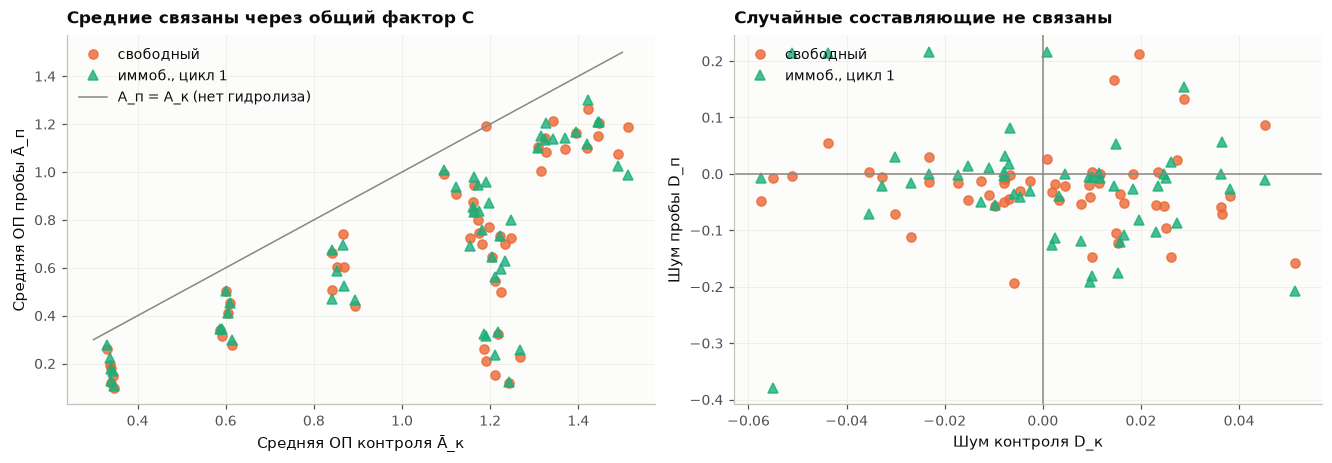

In [27]:
key = ["experiment", "temperature_c", "ph", "substrate_pct", "time_min"]
m12 = enz.merge(ctrl[key + ["mean", "log_ratio"]], on=key, suffixes=("", "_c"))
rows = []
for g in ["свободный", "иммоб., цикл 1"]:
    d = m12[m12["group"] == g]
    dc = d[d["experiment"] == "conc"]
    r_noise, p_noise = st.permutation_corr(d["log_ratio_c"], d["log_ratio"], n_perm=4999, seed=SEED)
    r_abs, p_abs = st.permutation_corr(d["log_ratio_c"].abs(), d["log_ratio"].abs(), n_perm=4999, seed=SEED)
    r_part, p_part = st.partial_corr_by_group(dc["mean_c"], dc["mean"], dc["substrate_pct"])
    rows.append({"проба": g, "n условий": len(d),
                 "Пирсон средних": stats.pearsonr(d["mean_c"], d["mean"]).statistic,
                 "Спирмен средних": stats.spearmanr(d["mean_c"], d["mean"]).statistic,
                 "частная r внутри C (conc)": r_part, "p (частная)": p_part,
                 "Спирмен D_к vs D_п": r_noise, "p (перест.)": p_noise,
                 "Спирмен |D_к| vs |D_п|": r_abs, "p (перест.) |D|": p_abs})
dep = pd.DataFrame(rows).set_index("проба")
display(dep.T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.1))
for g, tp in [("свободный", "free"), ("иммоб., цикл 1", "immobilized")]:
    d = m12[m12["group"] == g]
    axes[0].plot(d["mean_c"], d["mean"], ls="none", marker=pl.TYPE_MARKERS[tp], color=pl.TYPE_COLORS[tp], alpha=0.8, label=g)
    axes[1].plot(d["log_ratio_c"], d["log_ratio"], ls="none", marker=pl.TYPE_MARKERS[tp], color=pl.TYPE_COLORS[tp], alpha=0.8, label=g)
axes[0].plot([0.3, 1.5], [0.3, 1.5], color=pl.MUTED, lw=1, label="A_п = A_к (нет гидролиза)")
axes[0].set(xlabel="Средняя ОП контроля Ā_к", ylabel="Средняя ОП пробы Ā_п", title="Средние связаны через общий фактор C")
axes[1].axhline(0, color=pl.MUTED, lw=1); axes[1].axvline(0, color=pl.MUTED, lw=1)
axes[1].set(xlabel="Шум контроля D_к", ylabel="Шум пробы D_п", title="Случайные составляющие не связаны")
for ax in axes:
    ax.legend(loc="upper left")
plt.show()

**Что видно.**

1. **Средние сильно связаны** — Пирсон 0,72–0,74, Спирмен 0,67–0,70. Но связь создаёт общий фактор: условия с бо́льшим $C$ дают бо́льшую ОП и у контроля, и у пробы.
2. **Внутри одного уровня $C$ знак связи меняется**: частная корреляция −0,30 у свободного фермента ($p = 0{,}10$) и −0,51 у иммобилизованного ($p = 0{,}004$). Это второй общий фактор — время. Со временем контроль чуть растёт (дрейф, H1.1), а проба падает (гидролиз), поэтому внутри уровня $C$ средние связаны отрицательно. Это опять зависимость через условия, а не через сосуды.
3. **Случайные составляющие не коррелируют**: Спирмен $D_\text{к}$ vs $D_\text{п}$ −0,13 и −0,19 ($p = 0{,}33$ и $0{,}16$). Размахи $|D|$ тоже не связаны ($p = 0{,}19$ и $0{,}77$). Это согласуется с тем, что сосуды контроля и проб готовились независимо. Строго говоря, отсутствие корреляции не доказывает независимость, но признаков зависимости нет.

**Итог.** СВ-01 и СВ-02 **зависимы через общие условия опыта**: концентрацию и время. При фиксированных условиях их **случайные составляющие можно считать независимыми**. Именно это предположение нужно, чтобы считать погрешность степени гидролиза (СВ-03) по формуле для независимых ошибок.

#### Состоятельность оценок при тяжёлых хвостах

Для симметричного закона центр можно оценить средним или медианой, масштаб — SD или $1{,}4826\cdot\mathrm{MAD}$. Все четыре оценки состоятельны, пока у закона есть конечная дисперсия. Но точность у них разная.

Возьмём модель Лапласа, подогнанную к шуму свободного фермента. У закона Лапласа асимптотическая дисперсия медианы $b^2/n$, а среднего $2b^2/n$. Значит, медиана вдвое эффективнее: ей нужно вдвое меньше данных для той же точности. Каждая оценка сходится к *своему* параметру совокупности: SD — к $\sqrt2\,b$, $1{,}4826\cdot\mathrm{MAD}$ — к $1{,}4826\,b\ln2 \approx 1{,}03\,b$.

оценка,1.4826·MAD,SD,медиана,среднее,Var(ср.)/Var(мед.)
n,,,,,
5,0.03171,0.03013,0.02868,0.03086,1.157
10,0.02084,0.022,0.01802,0.02123,1.387
20,0.01572,0.01666,0.01216,0.01496,1.513
50,0.009605,0.01025,0.007518,0.009433,1.574
100,0.007006,0.007359,0.005196,0.006775,1.7
200,0.004924,0.005197,0.003547,0.004817,1.844
500,0.003185,0.003244,0.002205,0.002947,1.787
1000,0.002261,0.002386,0.001487,0.002091,1.978
2000,0.001611,0.00164,0.001113,0.001498,1.812


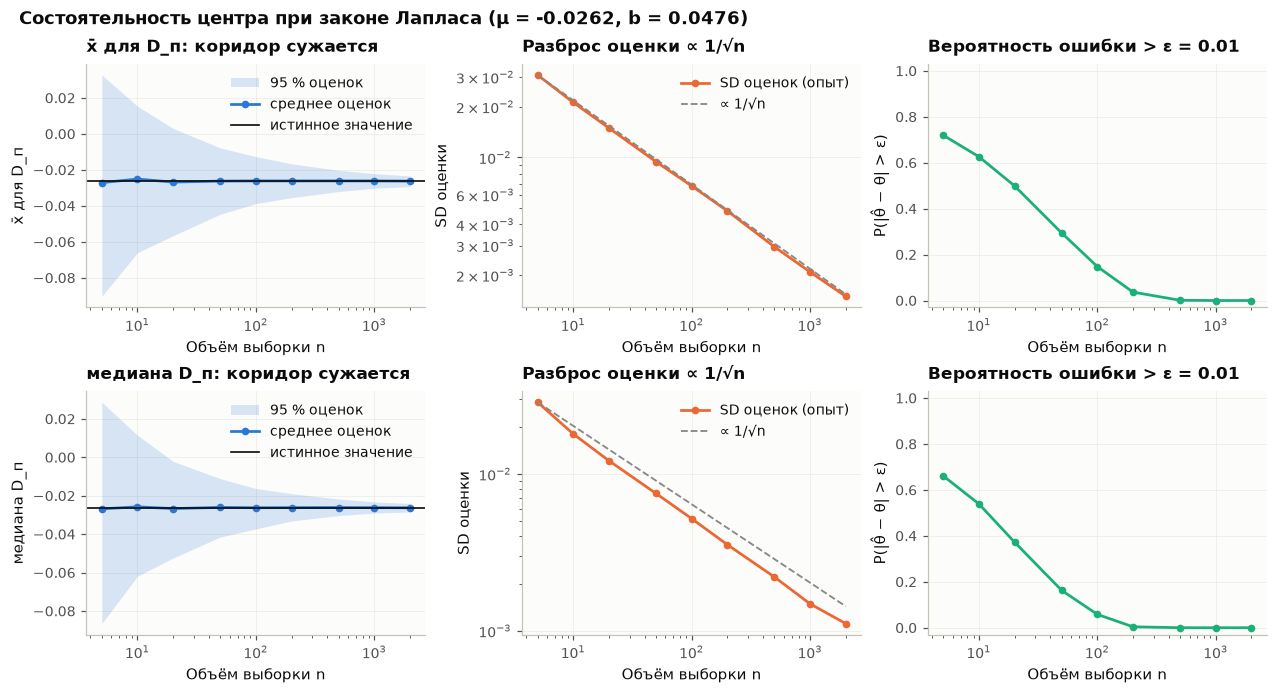

In [28]:
mu_l, b_l = fits_free.loc[fits_free["код"] == "laplace", "параметры"].iloc[0]
est = {"среднее": lambda s: s.mean(axis=1), "медиана": lambda s: np.median(s, axis=1),
       "SD": lambda s: s.std(axis=1, ddof=1),
       "1.4826·MAD": lambda s: 1.4826 * np.median(np.abs(s - np.median(s, axis=1, keepdims=True)), axis=1)}
truth = {"среднее": mu_l, "медиана": mu_l, "SD": np.sqrt(2) * b_l, "1.4826·MAD": 1.4826 * b_l * np.log(2)}
sim_l = st.consistency_sim(lambda rng, size: rng.laplace(mu_l, b_l, size), est,
                           [5, 10, 20, 50, 100, 200, 500, 1000, 2000], n_rep=2000, seed=SEED)
summ_l = st.consistency_summary(sim_l, truth, eps={k: 0.01 for k in est})
piv = summ_l.pivot(index="n", columns="оценка", values="SD оценок")
piv["Var(ср.)/Var(мед.)"] = (piv["среднее"] / piv["медиана"]) ** 2
display(piv)
pl.consistency_figure(summ_l, ["среднее", "медиана"], {"среднее": "x̄ для D_п", "медиана": "медиана D_п"},
                      f"Состоятельность центра при законе Лапласа (μ = {mu_l:.4f}, b = {b_l:.4f})")
plt.show()

**Что видно.** Обе оценки центра сходятся к $\mu$: коридор сужается, $P(|\hat\theta - \theta| > 0{,}01) \to 0$. Но у медианы коридор уже: отношение дисперсий среднего и медианы растёт к 2 (1,8–2,0 при $n \ge 200$), как предсказывает теория. Оценки масштаба тоже сходятся, каждая к своему значению.

**А если дисперсии нет?** ММП для закона Стьюдента дал $\nu \approx 1{,}9$. Посмотрим, что было бы, если бы шум действительно так распределялся. Это мысленный эксперимент, показывающий *условия* состоятельности.

In [29]:
nu_t, loc_t, sc_t = fits_free.loc[fits_free["код"] == "t", "параметры"].iloc[0]
ns_t = [10, 100, 1000, 10000]
sim_t = st.consistency_sim(lambda rng, size: loc_t + sc_t * rng.standard_t(nu_t, size),
                           {"медиана": lambda s: np.median(s, axis=1), "SD": lambda s: s.std(axis=1, ddof=1)},
                           ns_t, n_rep=400, seed=SEED)
display(sim_t.groupby(["оценка", "n"])["значение"].quantile([0.5, 0.975]).unstack().rename(
    columns={0.5: "медиана оценок", 0.975: "97,5 % оценок"}))
print(f"Модель: t с ν = {nu_t:.2f} < 2 — дисперсия бесконечна; центр μ = {loc_t:.4f}")

медиана оценок  97,5 % оценок
оценка  n                                   
SD      10            0.06156         0.2845
        100           0.08709         0.3732
        1000           0.1047         0.3731
        10000          0.1273         0.4678
медиана 10           -0.02739       0.004823
        100          -0.02825        -0.0183
        1000         -0.02847       -0.02528
        10000        -0.02846       -0.02748

Модель: t с ν = 1.86 < 2 — дисперсия бесконечна; центр μ = -0.0284


**Что видно.** Медиана по-прежнему сходится к центру $\mu$. А выборочное SD не стабилизируется: с ростом $n$ его типичное значение и особенно верхние квантили *растут*. Оценивать нечего — у закона нет конечной дисперсии, к которой можно было бы сходиться. Это иллюстрирует условие из теории: **состоятельность $s^2$ требует конечной дисперсии**.

Для реальных ОП дисперсия, конечно, конечна, поэтому модель Стьюдента с $\nu < 2$ мы и отвергли. Но урок практический: при тяжёлых хвостах SD и среднее медленно сходятся и чувствительны к выбросам, медиана и MAD надёжнее.

<a id="rv2-sampling"></a>
### Sampling

Генеральная совокупность — все 284 измеренные ОП проб с ферментом ($N = 284$). Как и для СВ-01, сравниваем одну выборку с возвращением и одну без возвращения ($n = 50$) с совокупностью, затем повторяем отбор много раз.

,совокупность (N),с возвращением,без возвращения
n,284,50,50
среднее,0.764,0.6647,0.763
дисперсия,0.135,0.174,0.1482
SD,0.3675,0.4171,0.3849
медиана,0.8233,0.6247,0.8264
Q1,0.4453,0.2438,0.3622
Q3,1.091,1.051,1.111
минимум,0.09537,0.09795,0.1024
максимум,1.497,1.497,1.344
разных элементов,284,44,50


,n,доля N,Var с возвр. (опыт),Var с возвр. (теория),Var без возвр. (опыт),Var без возвр. (теория)
0,5,0.01761,0.02734,0.02701,0.02676,0.02663
1,10,0.03521,0.01305,0.0135,0.013,0.01307
2,25,0.08803,0.005383,0.005402,0.004862,0.004944
3,50,0.1761,0.002594,0.002701,0.002258,0.002233
4,100,0.3521,0.001352,0.00135,0.0008826,0.000878
5,150,0.5282,0.0009073,0.0009003,0.0004356,0.0004263
6,200,0.7042,0.0006901,0.0006752,0.0002064,0.0002004
7,250,0.8803,0.0005591,0.0005402,6.55e-05,6.49e-05


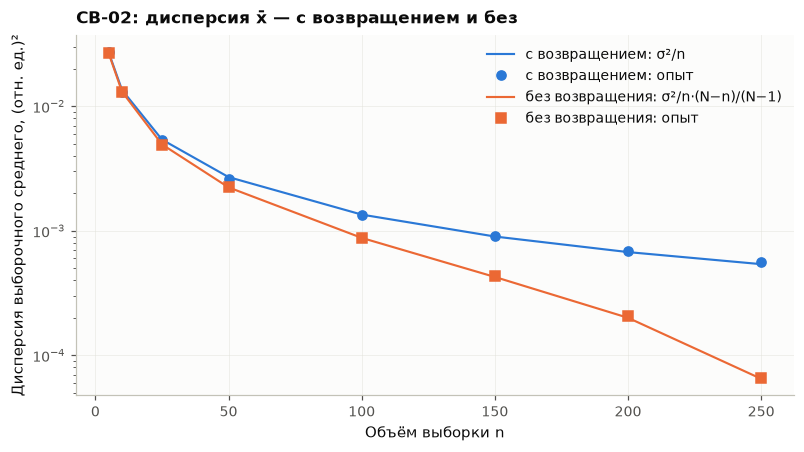

In [30]:
pop2 = a_enz["absorbance"].to_numpy()
cmp2, s_with2, s_without2 = st.population_vs_samples(pop2, n=50, seed=SEED)
display(cmp2)
samp2 = st.sampling_distribution(pop2, ns=[5, 10, 25, 50, 100, 150, 200, 250], n_rep=5000, seed=SEED)
display(samp2)
pl.sampling_figure(samp2, "отн. ед.", "СВ-02: дисперсия x̄ — с возвращением и без")
plt.show()

**Что видно.** Выборка без возвращения из 50 элементов (18 % совокупности) воспроизводит среднее (0,763 против 0,764) и медиану. Выборка с возвращением в этот раз неудачна: среднее 0,66, медиана 0,62. В неё случайно попало больше малых ОП — поздних времён с высокой активностью — и только 44 разных элемента из 50. Это обычная изменчивость одной выборки, и КС-тест различий не находит ($p = 0{,}15$ и $0{,}90$). Повторный отбор показывает, что в среднем обе схемы несмещённые, а их разброс совпадает с формулами. Преимущество выборки без возвращения растёт с долей $n/N$: при $n = 250$ из 284 её дисперсия в 8,5 раза меньше. Для совокупности большего объёма та же доля даёт тот же выигрыш, а при $n \ll N$ схемы практически равноценны.

<a id="rv2-hypotheses"></a>
### Hypothesis Testing

#### H2.1. Одинаков ли разброс у контроля, свободного и иммобилизованного фермента

- $H_0$: дисперсии случайной составляющей $D$ у трёх типов проб равны;
- $H_1$: хотя бы одна отличается.

**Выбор критерия.** Классический критерий Бартлетта очень чувствителен к ненормальности, а у $D_\text{п}$ тяжёлые хвосты. Поэтому берём **критерий Брауна–Форсайта** — дисперсионный анализ абсолютных отклонений от медианы. Для проверки добавляем ранговый **критерий Флигнера–Килина**, который вообще не требует нормальности.

Чтобы общие сдвиги серий и порядковый эффект не исказили сравнение, основной тест проводим на остатках внутри серий: $D$ минус среднее серии. Берём только группы, где в серии не меньше 6 условий.

In [31]:
pairs["grp"] = pairs["series"] + "|" + pairs["sample_type"] + "|" + pairs["cycle"].astype(str)
pairs["resid"] = pairs["log_ratio"] - pairs.groupby("grp")["log_ratio"].transform("mean")
big = pairs.groupby("grp")["log_ratio"].transform("size") >= 6
resid = {tp: pairs.loc[big & (pairs["sample_type"] == tp), "resid"].to_numpy() for tp in ["control", "free", "immobilized"]}
raw = {tp: pairs.loc[pairs["sample_type"] == tp, "log_ratio"].to_numpy() for tp in ["control", "free", "immobilized"]}
h21 = stats.levene(*resid.values(), center="median")
h21_check = stats.fligner(*raw.values())
print("SD остатков внутри серий (поправка на число степеней свободы):",
      {pl.TYPE_LABELS[k]: round(v.std(ddof=1) * np.sqrt(6 / 5), 4) for k, v in resid.items()})
print(f"Браун–Форсайт (остатки): W = {h21.statistic:.2f}, p = {h21.pvalue:.2e}")
print(f"Флигнер–Килин (исходные D): χ² = {h21_check.statistic:.2f}, p = {h21_check.pvalue:.2e}")

SD остатков внутри серий (поправка на число степеней свободы): {'контроль': np.float64(0.0192), 'свободный': np.float64(0.0729), 'иммобилизованный': np.float64(0.0955)}
Браун–Форсайт (остатки): W = 9.81, p = 8.94e-05
Флигнер–Килин (исходные D): χ² = 25.27, p = 3.26e-06


**Результат.** Разброс внутри серий у контроля 0,019, у свободного фермента 0,073, у иммобилизованного 0,096. Браун–Форсайт $p \approx 10^{-4}$, Флигнер–Килин $p \approx 3\cdot10^{-6}$. $H_0$ отвергается.

**Химическая интерпретация.** Без реакции ошибка — это только приготовление и измерение, около 1,4 % на сосуд ($0{,}019/\sqrt2$). Реакция добавляет ошибку старта и остановки и разброс количества фермента: у свободного фермента около 5 % на сосуд. Иммобилизованный фермент добавляет ещё неоднородность носителя: сколько фермента адсорбировалось на конкретной пластинке и сколько десорбировалось — около 7 % на сосуд. Вывод для эксперимента: сравнения иммобилизованного фермента требуют больше повторностей.

#### H2.2. Есть ли систематическая разница между сосудами 1 и 2 у проб с ферментом

- $H_0$: среднее $D_\text{п}$ серии равно 0;
- $H_1$: $\ne 0$.

Единица анализа — серия: 9 значений, каждое — среднее $D_\text{п}$ по свободному и иммобилизованному ферменту первого цикла в этой серии. Используем t-тест и точный тест Уилкоксона.

In [32]:
first_cycle = enz[(enz["sample_type"] == "free") | (enz["cycle"] == 1)]
series_mean_e = first_cycle.groupby("series")["log_ratio"].mean()
by_type = first_cycle.pivot_table(index="series", columns="sample_type", values="log_ratio", aggfunc="mean")
by_type["оба типа"] = series_mean_e
display(by_type.rename(columns=pl.TYPE_LABELS))
h22_t = stats.ttest_1samp(series_mean_e, 0.0)
h22_w = stats.wilcoxon(series_mean_e, method="exact")
print(f"Серий с A1 < A2: {(series_mean_e < 0).sum()} из {len(series_mean_e)}; "
      f"среднее D = {series_mean_e.mean():.4f} (сосуд 1 ниже на {100 * (1 - np.exp(series_mean_e.mean())):.1f} %); "
      f"t-тест p = {h22_t.pvalue:.4f}; Уилкоксон p = {h22_w.pvalue:.4f}")

sample_type,свободный,иммобилизованный,оба типа
series,,,
conc 0.25 %,-0.03514,0.003495,-0.01582
conc 0.5 %,-0.01246,-0.02869,-0.02058
conc 0.75 %,-0.04219,-0.002741,-0.02247
conc 1 %,-0.0379,-0.03947,-0.03869
conc 1.25 %,0.01132,-0.005496,0.002912
kin60,-0.07744,-0.02926,-0.05335
kin90,-0.03203,-0.08078,-0.05641
ph,-0.01439,6.156e-05,-0.007165
temp,-0.0002333,-0.01269,-0.006462


Серий с A1 < A2: 8 из 9; среднее D = -0.0242 (сосуд 1 ниже на 2.4 %); t-тест p = 0.0085; Уилкоксон p = 0.0078


**Результат.** В 8 сериях из 9 сосуд 1 даёт в среднем меньшую ОП, чем сосуд 2. Средний сдвиг около 2,4 %, t-тест $p = 0{,}009$, точный тест Уилкоксона $p = 0{,}008$. Без поправки на множественность $H_0$ отвергается: у проб с ферментом сосуды 1 и 2 систематически различаются, а у контроля (H1.3) — нет. С поправкой Холма по всем гипотезам работы $p = 0{,}051$ (см. [Lab resume](#resume)), так что эффект на грани строгой значимости, хотя его направление устойчиво.

**Химическая интерпретация.** Меньшая ОП означает, что в первом сосуде гидролизовалось больше крахмала. Простое объяснение — порядок работы: сосуды запускали по очереди, и первый реагировал чуть дольше второго. У контроля реакции нет, поэтому и эффекта нет — это согласуется с объяснением. Эффект невелик, но систематичен. Для точных кинетических измерений момент старта и остановки каждого сосуда нужно фиксировать или чередовать порядок сосудов.

<a id="rv2-resume"></a>
### Resume

1. **Природа.** ОП пробы с ферментом определяется кинетикой гидролиза: падает со временем, минимальна около 60–70 °C, слабо зависит от pH. Но при одних условиях два сосуда различаются, причём сильнее, чем у контроля. Это случайная величина.
2. **Распределение шума.** $D_\text{п}$ не нормальна: тяжёлые хвосты, избыточный эксцесс 2,4–2,8. Лучший по AIC закон — Лапласа, по смыслу это смесь нормальных ошибок с разным разбросом плюс несколько выбросов. Модель Стьюдента даёт $\nu < 2$, что физически невозможно. Для нормализации используем робастный $z$ по медиане и MAD.
3. **Зависимость от СВ-01.** Средние сильно связаны через общие факторы — концентрацию (+) и время (−). Случайные составляющие не коррелируют ($p > 0{,}15$), то есть при фиксированных условиях ошибки контроля и пробы независимы.
4. **Состоятельность.** Медиана и среднее сходятся к центру, медиана вдвое эффективнее. При бесконечной дисперсии (мысленная модель Стьюдента) выборочное SD не сходится — так видно условие состоятельности.
5. **Гипотезы.** Разброс у контроля, свободного и иммобилизованного фермента разный: 1,4, 5 и 7 % на сосуд. В 8 сериях из 9 сосуд 1 даёт в среднем на 2,4 % меньшую ОП ($p = 0{,}009$, после поправки Холма 0,051) — вероятно, из-за порядка запуска.

<a id="rv3"></a>
## Random Variable 03 — степень гидролиза $X$

<a id="rv3-description"></a>
### Description

**Определение.** Для каждого условия с ферментом степень гидролиза считается по средним двух сосудов пробы и контроля из того же эксперимента:

$$X = 100\,\%\cdot\left(1 - \frac{\bar A_\text{п}}{\bar A_\text{к}}\right).$$

Сосуды контроля и пробы не связаны, поэтому степень гидролиза для отдельного сосуда пробы считаем по среднему контролю: $X_j = 100\,\%\cdot(1 - A_{\text{п},j}/\bar A_\text{к})$. Это пересчитанный датасет 2: 142 условия.

**Физический смысл.** Доля крахмала — точнее, способных связывать йод длинных цепей, — которая исчезла за время реакции. Истинная степень гидролиза лежит в $[0, 100\,\%]$. *Измеренная* может оказаться немного отрицательной, если гидролиза почти нет, а шум случайно сделал $A_\text{п} > A_\text{к}$. Больше 100 % она быть не может, потому что $A_\text{п} \ge 0$.

**Стохастическая природа.** $X$ — функция двух случайных величин, СВ-01 и СВ-02, поэтому сама случайна. Её разброс складывается из шума сосудов контроля и пробы, а ещё из изменчивости между постановками опыта (см. ниже).

**Погрешность — закон распространения ошибок.** Обозначим $R = \bar A_\text{п}/\bar A_\text{к}$, тогда $X = 100(1-R)$. Разложим $R$ в ряд Тейлора первого порядка около истинных значений:

$$\frac{\delta R}{R} \approx \frac{\delta\bar A_\text{п}}{\bar A_\text{п}} - \frac{\delta\bar A_\text{к}}{\bar A_\text{к}}.$$

Ошибки контроля и пробы независимы (СВ-02, Independence), поэтому дисперсии складываются:

$$u(X) = 100\,\%\cdot R\,\sqrt{\left(\frac{u_\text{п}}{\bar A_\text{п}}\right)^2 + \left(\frac{u_\text{к}}{\bar A_\text{к}}\right)^2}, \qquad u = \frac{s}{\sqrt 2}.$$

Множитель $R = 1 - X/100$ важен: при глубоком гидролизе относительная ошибка малой ОП пробы умножается на малое $R$, поэтому $u(X)$ мала. Это и было неверно в исходной «Погрешности», которая не учитывала множитель $R$ и разброс контроля.

<a id="rv3-eda"></a>
### EDA & Distribution

#### Пересчитанный датасет 2 против исходной таблицы

,строк,"медиана |ΔX|, п.п.","макс |ΔX|, п.п."
status,,,
сходится с тройками целиком,114,0.4053,2.327
не воспроизводится,6,2.738,8.217
"сходится, только если убрать одно значение",28,0.4525,4.376


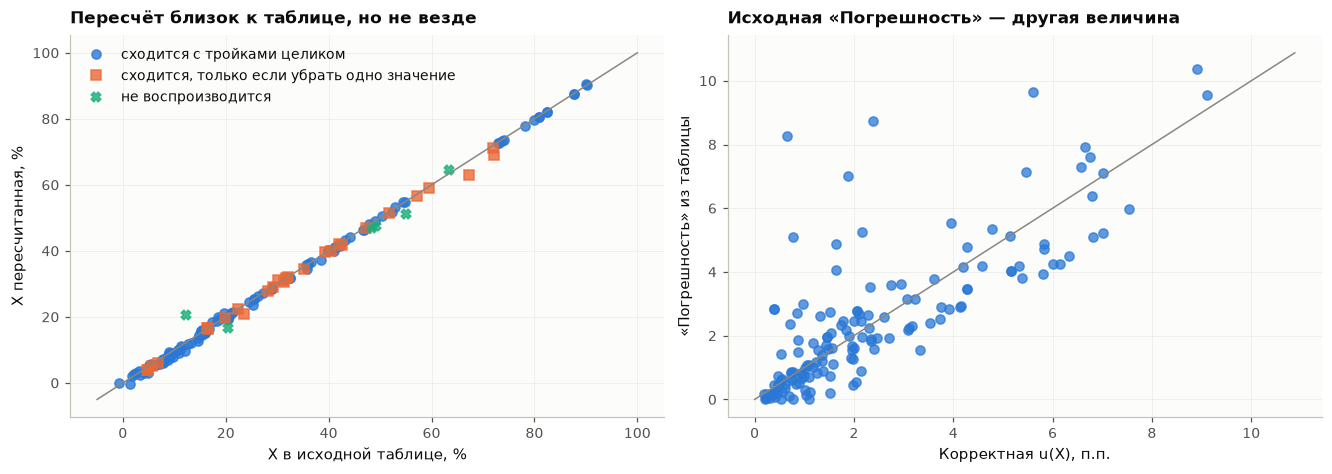

In [33]:
cmp_tab = audit.merge(hyd[["triplet_id", "x_pct", "u_x_pct"]], left_on="sample_triplet", right_on="triplet_id",
                      suffixes=("_табл", "_пересчёт"))
cmp_tab["ΔX"] = cmp_tab["x_pct_пересчёт"] - cmp_tab["x_pct_табл"]
display(cmp_tab.groupby("status")["ΔX"].agg(["count", lambda v: np.abs(v).median(), lambda v: np.abs(v).max()])
        .rename(columns={"count": "строк", "<lambda_0>": "медиана |ΔX|, п.п.", "<lambda_1>": "макс |ΔX|, п.п."})
        .rename(index=status_labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
for status, marker in [("exact", "o"), ("two_of_three", "s"), ("not_reproducible", "X")]:
    d = cmp_tab[cmp_tab["status"] == status]
    ax.plot(d["x_pct_табл"], d["x_pct_пересчёт"], ls="none", marker=marker, alpha=0.8, label=status_labels[status])
ax.plot([-5, 100], [-5, 100], color=pl.MUTED, lw=1)
ax.set(xlabel="X в исходной таблице, %", ylabel="X пересчитанная, %", title="Пересчёт близок к таблице, но не везде")
ax.legend(loc="upper left")
ax = axes[1]
ax.plot(cmp_tab["u_x_pct"], cmp_tab["err_pct"], ls="none", marker="o", color=pl.SERIES[0], alpha=0.75)
lim = [0, max(cmp_tab["u_x_pct"].max(), cmp_tab["err_pct"].max()) * 1.05]
ax.plot(lim, lim, color=pl.MUTED, lw=1)
ax.set(xlabel="Корректная u(X), п.п.", ylabel="«Погрешность» из таблицы", title="Исходная «Погрешность» — другая величина")
plt.show()

**Что видно.**

- **Пересчёт против таблицы.** Там, где таблица сходится с текущими тройками, разница возникает только из-за исключения вычисленного третьего значения: медиана 0,4 п.п., максимум 2,3 п.п. В строках, посчитанных по другой версии ОП, медиана та же, но максимум 4,4 п.п. В шести невоспроизводимых строках расхождение доходит до 8 п.п.
- **Погрешность.** Исходная «Погрешность» и корректная $u(X)$ почти не связаны: точки разбросаны по обе стороны от линии равенства. В одних условиях таблица завышает погрешность в несколько раз (глубокий гидролиз, где важен множитель $R$), в других занижает (там, где главный вклад — разброс контроля).

#### Описательные статистики

In [34]:
hyd["group"] = np.where(hyd["sample_type"] == "free", "свободный",
                        np.where(hyd["cycle"] == 1, "иммоб., цикл 1", "иммоб., циклы 2–3"))
display(st.describe_groups({"все 142": hyd["x_pct"],
                            **{g: v["x_pct"] for g, v in hyd.groupby("group")}}).T)
print("u(X), п.п.: медиана", round(hyd["u_x_pct"].median(), 2), "| 90 %-квантиль", round(hyd["u_x_pct"].quantile(0.9), 2),
      "| максимум", round(hyd["u_x_pct"].max(), 2))
display(hyd[hyd["x_pct"] < 0][["experiment", "temperature_c", "substrate_pct", "time_min", "sample_type", "cycle",
                              "x_pct", "u_x_pct", "x_vessel1", "x_vessel2"]])

,n,среднее,медиана,дисперсия,SD,минимум,максимум,Q1,Q3,IQR,"CV, %",асимметрия,эксцесс
все 142,142,29.17,21.35,524.7,22.91,-0.4311,90.49,10.09,41.9,31.81,78.52,0.9165,0.04747
"иммоб., цикл 1",54,35.82,31.63,442.3,21.03,7.987,90.11,16.64,47.89,31.25,58.71,0.82,-0.1178
"иммоб., циклы 2–3",34,6.007,5.745,8.918,2.986,-0.4311,12.15,3.707,7.818,4.111,49.72,0.2493,-0.3149
свободный,54,37.11,31.79,494.5,22.24,-0.1105,90.49,20.12,47.02,26.9,59.92,0.8025,-0.09922


u(X), п.п.: медиана 1.69 | 90 %-квантиль 5.79 | максимум 9.11


,experiment,temperature_c,substrate_pct,time_min,sample_type,cycle,x_pct,u_x_pct,x_vessel1,x_vessel2
68,conc,30,1,5,immobilized,2,-0.4311,1.976,0.03861,-0.9009
118,temp,25,1,30,free,1,-0.1105,1.989,1.799,-2.021


**Что видно.**

- **По группам.** Средняя $X$ свободного и иммобилизованного фермента в первом цикле почти одинакова: 37 % и 36 %. Во 2–3 циклах она падает до 6 %. Вся совокупность из 142 значений — смесь условий: от отрицательных до 90 %.
- **Отрицательные значения** есть в двух условиях: 25 °C, свободный фермент ($X = -0{,}1\,\%$; один сосуд $+1{,}8\,\%$, другой $-2{,}0\,\%$) и цикл 2 при 5 мин ($-0{,}4\,\%$). Истинная степень гидролиза не бывает отрицательной. Это прямое доказательство, что в измеренной $X$ есть случайная составляющая. Это и аргумент против бета-распределения: оно живёт строго на $[0, 1]$, а измеренная величина за эти границы выходит.
- **Погрешность** $u(X)$ — от 0,2 до 9 п.п., медиана 1,7 п.п.

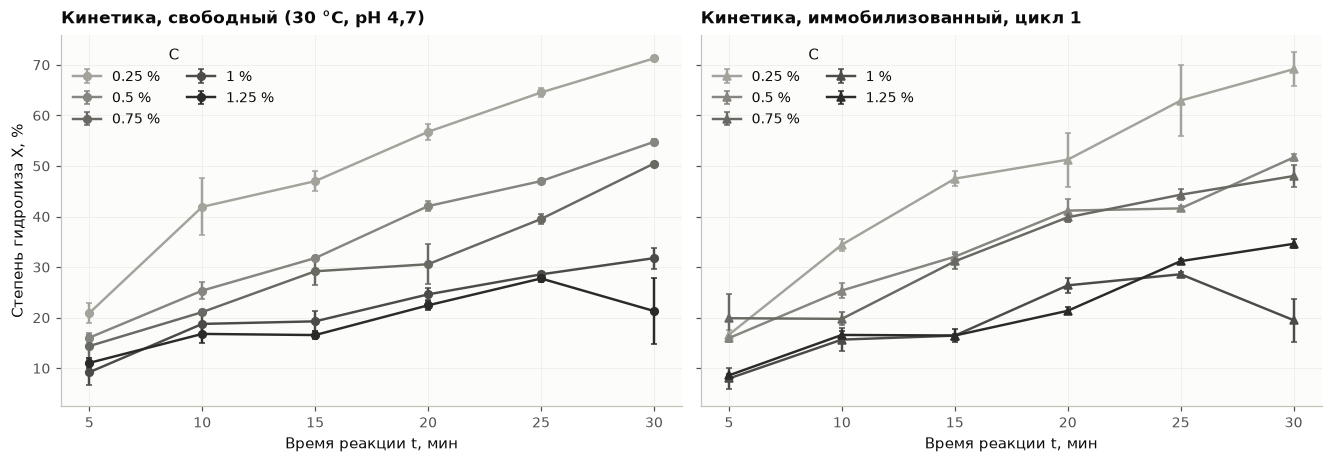

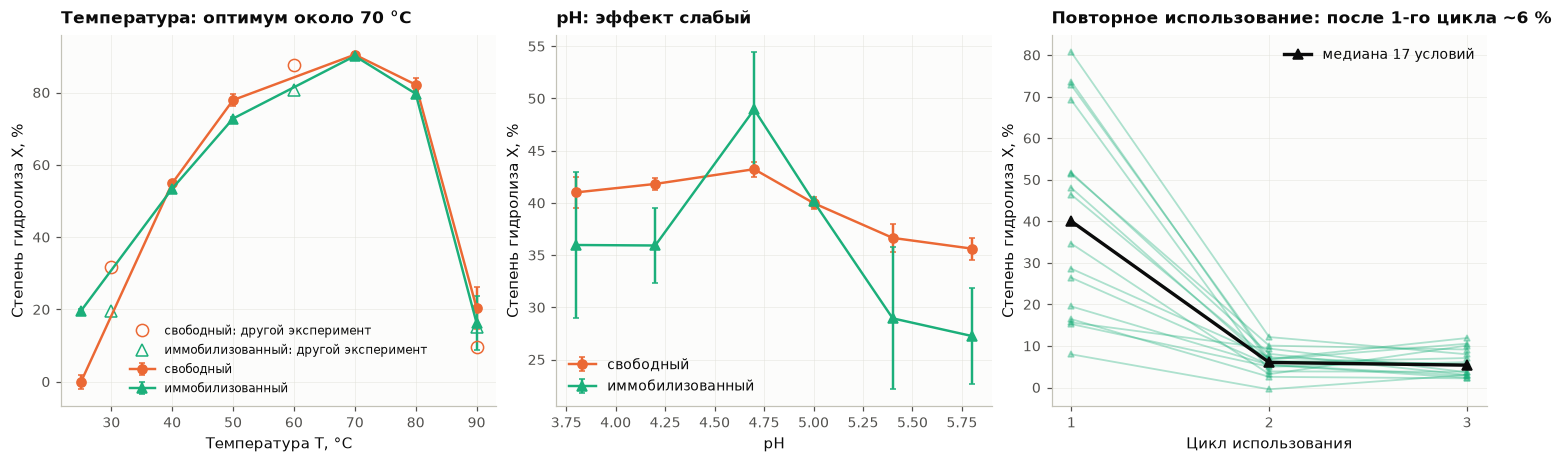

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.1), sharey=True)
for ax, tp, title in [(axes[0], "free", "Кинетика, свободный (30 °C, pH 4,7)"),
                      (axes[1], "immobilized", "Кинетика, иммобилизованный, цикл 1")]:
    for color, c in zip(pl.ORDINAL5, [0.25, 0.5, 0.75, 1.0, 1.25]):
        d = hyd[(hyd["experiment"] == "conc") & (hyd["sample_type"] == tp) & (hyd["substrate_pct"] == c) & (hyd["cycle"] == 1)].sort_values("time_min")
        ax.errorbar(d["time_min"], d["x_pct"], yerr=d["u_x_pct"], marker=pl.TYPE_MARKERS[tp], markersize=5,
                    color=color, capsize=2, lw=1.6, label=f"{c:g} %")
    ax.set(xlabel=pl.AXIS_LABELS["t"], title=title, xticks=[5, 10, 15, 20, 25, 30])
    ax.legend(title="C", ncol=2, loc="upper left")
axes[0].set_ylabel(pl.AXIS_LABELS["X"])
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.1))
for ax, exp, fac, xlabel, title in [(axes[0], "temp", "temperature_c", pl.AXIS_LABELS["T"], "Температура: оптимум около 70 °C"),
                                    (axes[1], "ph", "ph", pl.AXIS_LABELS["pH"], "pH: эффект слабый")]:
    for tp in ["free", "immobilized"]:
        d = hyd[(hyd["experiment"] == exp) & (hyd["sample_type"] == tp)].sort_values(fac)
        ax.errorbar(d[fac], d["x_pct"], yerr=d["u_x_pct"], marker=pl.TYPE_MARKERS[tp], color=pl.TYPE_COLORS[tp],
                    capsize=2, lw=1.6, label=pl.TYPE_LABELS[tp])
    ax.set(xlabel=xlabel, ylabel=pl.AXIS_LABELS["X"], title=title)
other = hyd[((hyd["experiment"] == "conc") & (hyd["substrate_pct"] == 1.0)) | hyd["experiment"].isin(["kin60", "kin90"])]
other = other[(other["time_min"] == 30) & (other["cycle"] == 1)]
for tp in ["free", "immobilized"]:
    d = other[other["sample_type"] == tp]
    axes[0].plot(d["temperature_c"], d["x_pct"], ls="none", marker=pl.TYPE_MARKERS[tp], markersize=8,
                 markerfacecolor="none", color=pl.TYPE_COLORS[tp], label=f"{pl.TYPE_LABELS[tp]}: другой эксперимент")
axes[0].legend(loc="lower center", fontsize=8)
axes[1].legend(loc="lower left")
ax = axes[2]
cyc = hyd[hyd["sample_type"] == "immobilized"].pivot_table(index=["series", "time_min", "substrate_pct"], columns="cycle", values="x_pct").dropna()
for _, row in cyc.iterrows():
    ax.plot([1, 2, 3], row[[1, 2, 3]], color=pl.TYPE_COLORS["immobilized"], alpha=0.35, lw=1.2, marker="^", markersize=4)
ax.plot([1, 2, 3], cyc[[1, 2, 3]].median(), color=pl.INK, lw=2.2, marker="^", markersize=7, label="медиана 17 условий")
ax.set(xticks=[1, 2, 3], xlabel="Цикл использования", ylabel=pl.AXIS_LABELS["X"], title="Повторное использование: после 1-го цикла ~6 %")
ax.legend(loc="upper right")
plt.show()

**Что видно.** Планки на графиках — $\pm u(X)$.

- **Кинетика.** $X$ растёт со временем, и тем быстрее, чем ниже концентрация крахмала. При $C = 0{,}25\,\%$ за 30 мин гидролизуется около 70 %, при $C = 1\,\%$ — около 20–30 %. Фермента одинаково, а субстрата больше, поэтому доля гидролизованного меньше. Провалы при 30 мин у 1,25 % (свободный) и 1 % (иммобилизованный) с большими планками — условия, где два сосуда сильно разошлись.
- **Температура.** Классическая колоколообразная кривая с оптимумом около 70 °C, где $X \approx 90\,\%$. При 90 °C активность резко падает — тепловая денатурация фермента.
- **Аномалия при 25 °C.** Свободный фермент даёт $X \approx 0$, а иммобилизованный — около 20 %. Возможно, часть крахмала адсорбируется на мезопористом TiO₂ и уходит из раствора без гидролиза. Проверить это можно только контролем «носитель без фермента», его в данных нет.
- **Полые маркеры** — точки 30, 60 и 90 °C из *других* экспериментов при тех же условиях. При 30 °C они расходятся с pH-экспериментом на 11–29 п.п. Поэтому склеивать температурную кривую из разных экспериментов, как на исходном графике, нельзя.
- **pH.** Изменения небольшие: у свободного фермента 36–43 %, максимум около pH 4,7. У иммобилизованного разброс сосудов сравним с эффектом.
- **Циклы.** После первого цикла $X$ иммобилизованного фермента падает с десятков процентов до ~6 % и больше не меняется. Это согласуется с десорбцией слабо связанного фермента в первом цикле, характерной для иммобилизации адсорбцией.

#### Нормализация: относительная активность и z-оценка

В химии «нормированная степень гидролиза» — это $X/X_\max$ внутри эксперимента, *относительная активность*. Её показывают исходные графики. Это масштабирование к максимуму, а не стандартизация из статистики:

$$a_\text{отн} = \frac{X}{X_{\max}}\cdot 100\,\%, \qquad z = \frac{X - \bar X}{s_X}.$$

Относительная активность отвечает на вопрос «какую долю от максимума даёт это условие». z-оценка отвечает на вопрос «на сколько стандартных отклонений условие отличается от среднего по эксперименту». Распределение $X$ по условиям задано дизайном, а не случайностью, поэтому $z$ здесь — только способ сравнить условия, и считать его стандартной нормальной величиной нельзя.

In [36]:
t_exp = hyd[hyd["experiment"] == "temp"].pivot_table(index="temperature_c", columns="sample_type", values="x_pct")
norm_tbl = pd.DataFrame({
    "X свободный, %": t_exp["free"], "отн. активность своб., %": 100 * t_exp["free"] / t_exp["free"].max(),
    "z своб.": (t_exp["free"] - t_exp["free"].mean()) / t_exp["free"].std(ddof=1),
    "X иммоб., %": t_exp["immobilized"], "отн. активность иммоб., %": 100 * t_exp["immobilized"] / t_exp["immobilized"].max(),
})
display(norm_tbl)

,"X свободный, %","отн. активность своб., %",z своб.,"X иммоб., %","отн. активность иммоб., %"
temperature_c,,,,,
25,-0.1105,-0.1222,-1.481,19.56,21.71
40,54.91,60.69,0.01642,53.42,59.28
50,77.93,86.12,0.6426,72.81,80.8
70,90.49,100,0.9844,90.11,100
80,82.2,90.84,0.7588,79.69,88.43
90,20.45,22.6,-0.9214,16.29,18.07


#### Распределение $X$ при фиксированных условиях

При фиксированных условиях $X$ — функция *отношения* двух случайных величин. Отношение двух нормальных величин, вообще говоря, не нормально. Если знаменатель может оказаться близким к нулю, у отношения тяжёлые хвосты, вплоть до распределения Коши. Но когда коэффициент вариации знаменателя мал, около 1 %, как у нашего контроля, знаменатель практически не может приблизиться к нулю. Тогда отношение с высокой точностью нормально — это и есть условие, при котором работает формула распространения ошибок (дельта-метод):

$$X \;\approx\; N\!\bigl(X_\text{ист},\; u^2(X)\bigr).$$

Проверим это моделированием методом Монте-Карло. Для трёх условий с низкой, средней и высокой $X$ генерируем по 100 000 «опытов». В каждом два сосуда контроля и два сосуда пробы, логнормальный шум с относительными SD, найденными в СВ-01 и СВ-02. Распределение полученных $\hat X$ сравниваем с нормальным приближением.

Относительная SD одного сосуда: {'контроль': '1.8 %', 'свободный': '5.0 %', 'иммобилизованный': '7.5 %'}


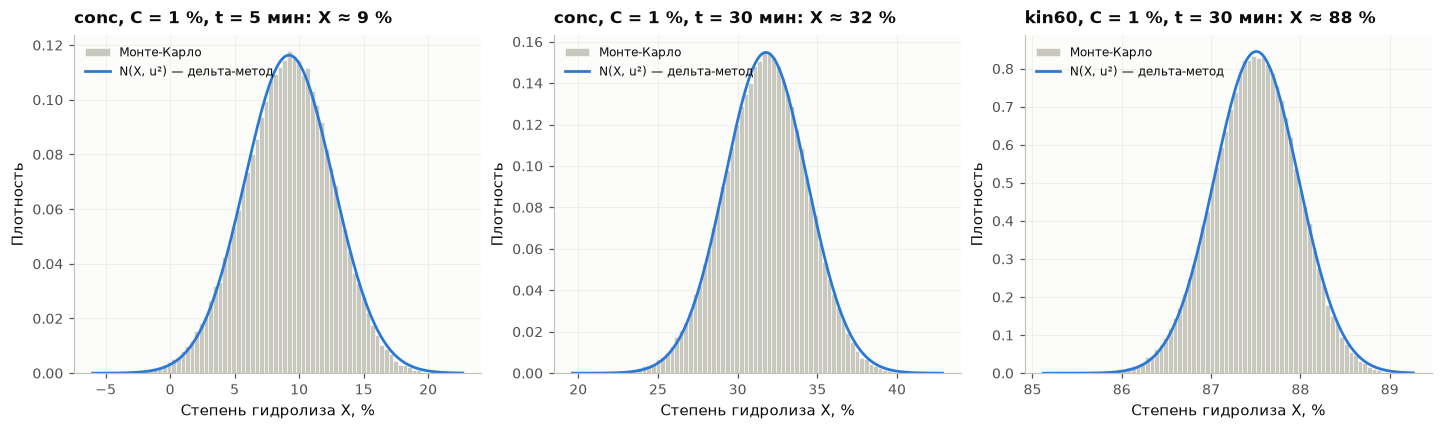

,"X, %",среднее МК,SD МК,u дельта-метод,асимметрия МК,эксцесс МК
условие,,,,,,
"conc, 1 %, 5 мин",9.216,9.109,3.425,3.429,-0.1283,0.002443
"conc, 1 %, 30 мин",31.78,31.69,2.588,2.577,-0.1137,0.03167
"kin60, 1 %, 30 мин",87.51,87.49,0.4738,0.4719,-0.1179,0.009744


In [37]:
sig_c = st.random_effects_icc(ctrl["log_ratio"], ctrl["series"])
rel_sd = {"control": np.sqrt(sig_c["τ (SD эффекта серии)"] ** 2 + sig_c["σ_e (SD внутри серии)"] ** 2) / np.sqrt(2),
          "free": D_free.std(ddof=1) / np.sqrt(2), "immobilized": D_imm.std(ddof=1) / np.sqrt(2)}
print("Относительная SD одного сосуда:", {pl.TYPE_LABELS[k]: f"{100 * v:.1f} %" for k, v in rel_sd.items()})

examples = [("conc", 1.0, 5, "free"), ("conc", 1.0, 30, "free"), ("kin60", 1.0, 30, "free")]
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
mc_rows = []
for ax, (exp, c, t, tp) in zip(axes, examples):
    row = hyd[(hyd["experiment"] == exp) & (hyd["substrate_pct"] == c) & (hyd["time_min"] == t) & (hyd["sample_type"] == tp) & (hyd["cycle"] == 1)].iloc[0]
    n_sim = 100_000
    a_c = row["a_control"] * np.exp(rng.normal(0, rel_sd["control"], (n_sim, 2))).mean(axis=1)
    a_p = row["a_sample"] * np.exp(rng.normal(0, rel_sd[tp], (n_sim, 2))).mean(axis=1)
    x_sim = 100 * (1 - a_p / a_c)
    u_delta = 100 * (row["a_sample"] / row["a_control"]) * np.sqrt(rel_sd[tp] ** 2 / 2 + rel_sd["control"] ** 2 / 2)
    ax.hist(x_sim, bins=80, density=True, color=pl.HIST_FILL, edgecolor=pl.SURFACE, linewidth=0.4, label="Монте-Карло")
    grid = np.linspace(x_sim.min(), x_sim.max(), 300)
    ax.plot(grid, stats.norm.pdf(grid, row["x_pct"], u_delta), color=pl.SERIES[0], lw=1.8, label="N(X, u²) — дельта-метод")
    ax.set(xlabel=pl.AXIS_LABELS["X"], ylabel="Плотность", title=f"{exp}, C = {c:g} %, t = {t} мин: X ≈ {row['x_pct']:.0f} %")
    ax.legend(loc="upper left", fontsize=8)
    mc_rows.append({"условие": f"{exp}, {c:g} %, {t} мин", "X, %": row["x_pct"], "среднее МК": x_sim.mean(),
                    "SD МК": x_sim.std(), "u дельта-метод": u_delta, "асимметрия МК": stats.skew(x_sim),
                    "эксцесс МК": stats.kurtosis(x_sim)})
plt.show()
display(pd.DataFrame(mc_rows).set_index("условие"))

**Что видно.** Во всех трёх условиях распределение $\hat X$ из моделирования совпадает с нормальным приближением дельта-метода: средние и SD совпадают до сотых, эксцесс около 0. Асимметрия около −0,1 — лёгкий хвост влево из-за нелинейности отношения, на практике незаметный. Значит, при наших ошибках распределение степени гидролиза в фиксированном условии нормально, а $u(X)$ корректно описывает его разброс. Это следует из малого CV знаменателя.

**Математическая база.** Пусть $U \sim N(\mu_U, \sigma_U^2)$, $V \sim N(\mu_V, \sigma_V^2)$ независимы. Плотность $W = U/V$ в общем случае выражается через функцию $\Phi$ и не нормальна, а при $\mu_V = 0$ это распределение Коши без среднего и дисперсии. Но если $P(V \le 0)$ пренебрежимо мала, то есть $\sigma_V/\mu_V \ll 1$, то линеаризация $g(U, V) \approx g(\mu) + \nabla g\cdot(\cdot - \mu)$ превращает $W$ в линейную комбинацию нормальных величин. Тогда

$$W \approx N\!\left(\frac{\mu_U}{\mu_V},\;\frac{\mu_U^2}{\mu_V^2}\Bigl(\frac{\sigma_U^2}{\mu_U^2} + \frac{\sigma_V^2}{\mu_V^2}\Bigr)\right).$$

Это и есть формула $u(X)$ выше. Отклонения от нормальности возникают во втором порядке, относительно $(\sigma_V/\mu_V)^2 \approx 10^{-4}$.

#### Где живёт случайность $X$: условия, сосуды, эксперименты

In [38]:
long = pd.concat([hyd.assign(vessel=1, x=hyd["x_vessel1"]), hyd.assign(vessel=2, x=hyd["x_vessel2"])])
ss_total = ((long["x"] - long["x"].mean()) ** 2).sum()
ss_within = ((long["x"] - long.groupby("triplet_id")["x"].transform("mean")) ** 2).sum()
print(f"Доля дисперсии X_j между условиями: η² = {1 - ss_within / ss_total:.3f}; "
      f"SD между сосудами одного условия: {np.sqrt(ss_within / (len(long) - hyd.shape[0])):.2f} п.п.")

same = hyd[(hyd["ph"] == 4.7) & (hyd["substrate_pct"] == 1.0) & (hyd["time_min"] == 30) & (hyd["cycle"] == 1)
           & hyd["temperature_c"].isin([30, 90])]
rep = same.pivot_table(index=["temperature_c", "sample_type"], columns="experiment", values=["x_pct", "u_x_pct"])
rows = []
for (temp, tp), r in rep.iterrows():
    exps = [e for e in ["conc", "ph", "kin90", "temp"] if not np.isnan(r[("x_pct", e)])]
    a, b = exps
    diff = r[("x_pct", b)] - r[("x_pct", a)]
    u_diff = np.hypot(r[("u_x_pct", a)], r[("u_x_pct", b)])
    rows.append({"T, °C": temp, "проба": pl.TYPE_LABELS[tp], f"эксперимент 1": a, "X₁, %": r[("x_pct", a)],
                 "эксперимент 2": b, "X₂, %": r[("x_pct", b)], "разница, п.п.": diff, "u разницы, п.п.": u_diff,
                 "разница / u": diff / u_diff})
display(pd.DataFrame(rows))

Доля дисперсии X_j между условиями: η² = 0.983; SD между сосудами одного условия: 4.27 п.п.


,"T, °C",проба,эксперимент 1,"X₁, %",эксперимент 2,"X₂, %","разница, п.п.","u разницы, п.п.",разница / u
0,30,свободный,conc,31.78,ph,43.23,11.45,2.186,5.239
1,30,иммобилизованный,conc,19.52,ph,48.95,29.43,6.942,4.24
2,90,свободный,kin90,9.712,temp,20.45,10.74,6.093,1.762
3,90,иммобилизованный,kin90,15.27,temp,16.29,1.014,9.132,0.1111


**Что видно.**

- **Условия против сосудов.** Условия опыта объясняют 98 % дисперсии $X$ отдельных сосудов. Разброс между сосудами одного условия около 4 п.п.
- **Между экспериментами.** Если повторить те же условия *в другой постановке опыта*, расхождение намного больше погрешности. При 30 °C свободный фермент даёт 31,8 % и 43,2 % — разница в 4–5 раз больше её погрешности. У иммобилизованного 19,5 % и 48,9 % — расхождение около 4 $u$. При 90 °C у свободного 9,7 % и 20,5 %.

Значит, у $X$ есть третий, самый большой уровень случайности — изменчивость между экспериментами: другой день, другой раствор фермента, другая партия носителя. Повторность по сосудам её не видит. В метрологии это различие между *сходимостью* (повторяемостью в одной постановке) и *промежуточной прецизионностью*.

**Практический вывод.** Сравнения внутри одного эксперимента надёжны. Сравнения между экспериментами, например температурная кривая, собранная из разных опытов, могут отражать различие постановок, а не влияние фактора.

<a id="rv3-independence"></a>
### Independence & Estimations

#### Зависимость $X$ от СВ-01 и СВ-02

Зависимость здесь **функциональная, по построению**: $X = 100(1 - A_\text{п}/A_\text{к})$. Её не нужно «доказывать» корреляцией: при фиксированных средних $X$ однозначно вычисляется, и корреляция $X$ с отношением $A_\text{п}/A_\text{к}$ равна −1. Полезнее знать чувствительность:

$$\frac{\partial X}{\partial A_\text{п}} = -\frac{100}{A_\text{к}}, \qquad \frac{\partial X}{\partial A_\text{к}} = \frac{100\,A_\text{п}}{A_\text{к}^2}.$$

Ошибка контроля сильнее всего влияет на $X$ там, где гидролиза мало ($A_\text{п} \approx A_\text{к}$). Ошибка пробы влияет одинаково на любом уровне, в пересчёте на 1/$A_\text{к}$.

Отдельный вопрос — связаны ли степени гидролиза свободного и иммобилизованного фермента в одних и тех же условиях. Обе величины одной природы, поэтому проверяем.

Пар условий: 54; Пирсон r = 0.968; Спирмен ρ = 0.947
Разности сосудов (шум) свободного и иммобилизованного: Спирмен ρ = 0.25, перестановочный p = 0.061


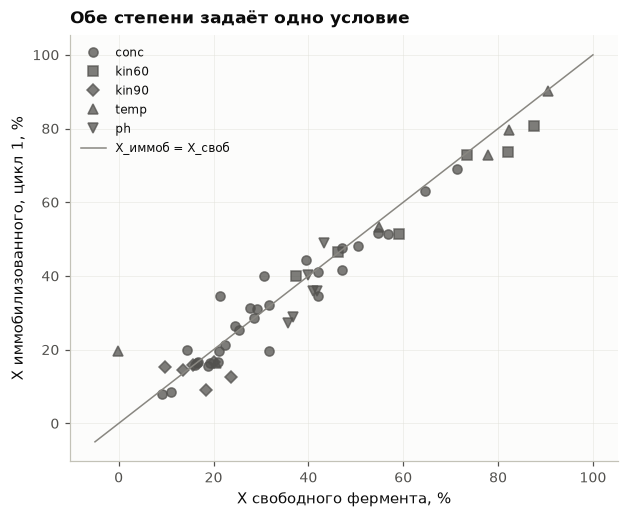

In [39]:
fi = hyd[hyd["sample_type"] == "free"].merge(
    hyd[(hyd["sample_type"] == "immobilized") & (hyd["cycle"] == 1)],
    on=["experiment", "series", "temperature_c", "ph", "substrate_pct", "time_min"], suffixes=("_f", "_i"))
print(f"Пар условий: {len(fi)}; Пирсон r = {stats.pearsonr(fi['x_pct_f'], fi['x_pct_i']).statistic:.3f}; "
      f"Спирмен ρ = {stats.spearmanr(fi['x_pct_f'], fi['x_pct_i']).statistic:.3f}")
e_f = fi["x_vessel1_f"] - fi["x_vessel2_f"]
e_i = fi["x_vessel1_i"] - fi["x_vessel2_i"]
r_e, p_e = st.permutation_corr(e_f, e_i, n_perm=4999, seed=SEED)
print(f"Разности сосудов (шум) свободного и иммобилизованного: Спирмен ρ = {r_e:.2f}, перестановочный p = {p_e:.3f}")

fig, ax = plt.subplots(figsize=(5.6, 4.6))
for exp, marker in zip(["conc", "kin60", "kin90", "temp", "ph"], ["o", "s", "D", "^", "v"]):
    d = fi[fi["experiment"] == exp]
    ax.plot(d["x_pct_f"], d["x_pct_i"], ls="none", marker=marker, color=pl.INK2, alpha=0.75, label=exp)
ax.plot([-5, 100], [-5, 100], color=pl.MUTED, lw=1, label="X_иммоб = X_своб")
ax.set(xlabel="X свободного фермента, %", ylabel="X иммобилизованного, цикл 1, %", title="Обе степени задаёт одно условие")
ax.legend(loc="upper left", fontsize=8)
plt.show()

**Что видно.** Степени гидролиза свободного и иммобилизованного фермента в одинаковых условиях почти совпадают: $r \approx 0{,}97$, точки лежат вдоль диагонали. Это зависимость через общие факторы — температуру, время, концентрацию. Сами ферменты друг на друга не влияют. Их случайные составляющие (разности сосудов) связаны слабо: $\rho = 0{,}25$, $p = 0{,}06$, на уровне 0,05 незначимо. Небольшая положительная связь ожидаема из-за общего порядкового эффекта: у обоих ферментов сосуд 1 запускался раньше (H2.2). Картина та же, что для СВ-01 и СВ-02: средние зависят от условий, шум практически независим.

#### Состоятельность оценки степени гидролиза

Оценка $\hat X_n = 100\bigl(1 - \bar A_{\text{п},n}/\bar A_{\text{к},n}\bigr)$ по $n$ сосудам контроля и пробы — **нелинейная** функция средних. Поэтому при конечном $n$ она *смещена*. По неравенству Йенсена $\mathbb E[1/\bar A_\text{к}] > 1/\mu_\text{к}$, так что $\hat X_n$ в среднем немного занижена. Тем не менее она **состоятельна**: $\bar A_{\text{п},n} \to \mu_\text{п}$ и $\bar A_{\text{к},n} \to \mu_\text{к}$ по закону больших чисел. Функция $g(a, b) = 1 - a/b$ непрерывна при $b > 0$, поэтому по теореме о непрерывном отображении $\hat X_n \to X_\text{ист}$. Проверим на модели условия «conc, 1 %, 5 мин, свободный», где ошибка контроля влияет сильнее всего.

,истинное,среднее оценок,смещение,SD оценок,P(|θ̂ − θ| > ε)
n,,,,,
2,9.116,9.103,-0.01327,3.389,0.7728
3,9.116,9,-0.1162,2.742,0.7232
5,9.116,9.139,0.02267,2.195,0.6442
10,9.116,9.132,0.01596,1.545,0.5145
20,9.116,9.109,-0.007339,1.104,0.3628
50,9.116,9.116,-0.0005438,0.692,0.1492
100,9.116,9.108,-0.008233,0.495,0.04025
500,9.116,9.122,0.005227,0.2178,0
2000,9.116,9.117,0.0006462,0.1086,0


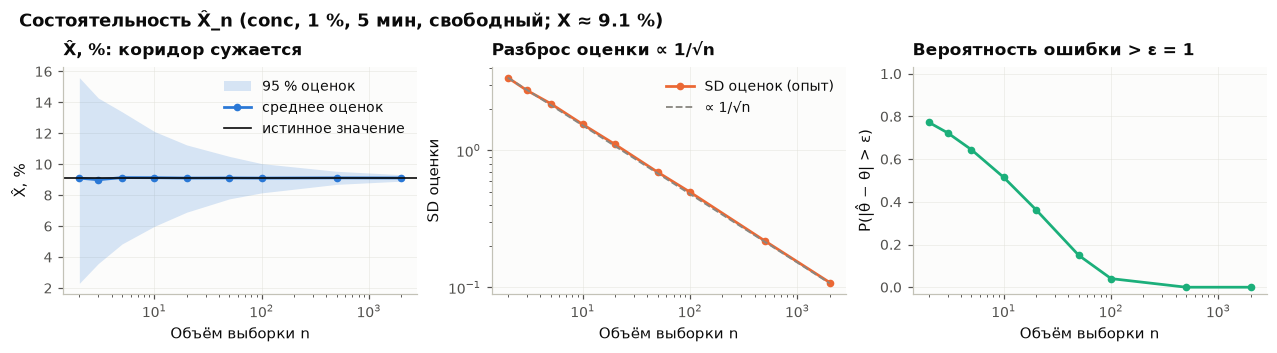

In [40]:
row = hyd[(hyd["experiment"] == "conc") & (hyd["substrate_pct"] == 1.0) & (hyd["time_min"] == 5) & (hyd["sample_type"] == "free")].iloc[0]
mu_p, mu_k = row["a_sample"], row["a_control"]   # медианы логнормальных ОП одного сосуда

def draw_x(rng, size):
    reps, n = size
    a_p = mu_p * np.exp(rng.normal(0, rel_sd["free"], (reps, n))).mean(axis=1, keepdims=True)
    a_k = mu_k * np.exp(rng.normal(0, rel_sd["control"], (reps, n))).mean(axis=1, keepdims=True)
    return 100 * (1 - a_p / a_k)

sim_x = st.consistency_sim(draw_x, {"X̂_n": lambda s: s[:, 0]}, [2, 3, 5, 10, 20, 50, 100, 500, 2000], n_rep=4000, seed=SEED)
# истинное значение — X при истинных средних μ = E A = μ_ист·e^{σ²/2} (логнормальный шум)
x_true = 100 * (1 - mu_p * np.exp(rel_sd["free"] ** 2 / 2) / (mu_k * np.exp(rel_sd["control"] ** 2 / 2)))
summ_x = st.consistency_summary(sim_x, {"X̂_n": x_true}, {"X̂_n": 1.0})
display(summ_x.set_index("n")[["истинное", "среднее оценок", "смещение", "SD оценок", "P(|θ̂ − θ| > ε)"]])
pl.consistency_figure(summ_x, ["X̂_n"], {"X̂_n": "X̂, %"}, f"Состоятельность X̂_n (conc, 1 %, 5 мин, свободный; X ≈ {x_true:.1f} %)")
plt.show()

**Что видно.** Смещение по теории есть, но при CV контроля 1,8 % оно около −0,015 п.п. при $n = 2$ ($\approx -100R\,\mathrm{CV}_\text{к}^2/n$) и тонет в шуме моделирования. Средние оценок совпадают с истинным значением при любом $n$. Разброс оценки убывает как $1/\sqrt n$, а вероятность ошибиться больше чем на 1 п.п. падает от 0,77 при $n = 2$ до 0 при $n \ge 500$. Значит, $\hat X_n$ состоятельна. Для практики: при двух сосудах типичная ошибка $X$ в этом условии около 3,4 п.п. Чтобы уменьшить её вдвое, нужно вчетверо больше сосудов.

<a id="rv3-sampling"></a>
### Sampling

Генеральная совокупность — 142 пересчитанные степени гидролиза, по одной на условие ($N = 142$). Сравниваем выборки $n = 40$ (28 %) с возвращением и без, затем дисперсию выборочного среднего при многократном отборе.

,совокупность (N),с возвращением,без возвращения
n,142,40,40
среднее,29.17,35.03,33.65
дисперсия,521,683.7,599.9
SD,22.82,26.15,24.49
медиана,21.35,29.88,29.17
Q1,10.09,10.09,16.55
Q3,41.9,49.37,46.79
минимум,-0.4311,3.209,-0.4311
максимум,90.49,87.51,87.51
разных элементов,142,34,40


,n,доля N,Var с возвр. (опыт),Var с возвр. (теория),Var без возвр. (опыт),Var без возвр. (теория)
0,5,0.03521,106.8,104.2,104.2,101.2
1,10,0.07042,52.29,52.1,50.73,48.77
2,20,0.1408,26.85,26.05,22.42,22.54
3,40,0.2817,13.28,13.02,9.405,9.422
4,60,0.4225,8.638,8.683,4.989,5.05
5,80,0.5634,6.308,6.512,2.882,2.864
6,100,0.7042,5.159,5.21,1.57,1.552
7,120,0.8451,4.336,4.341,0.6452,0.6774


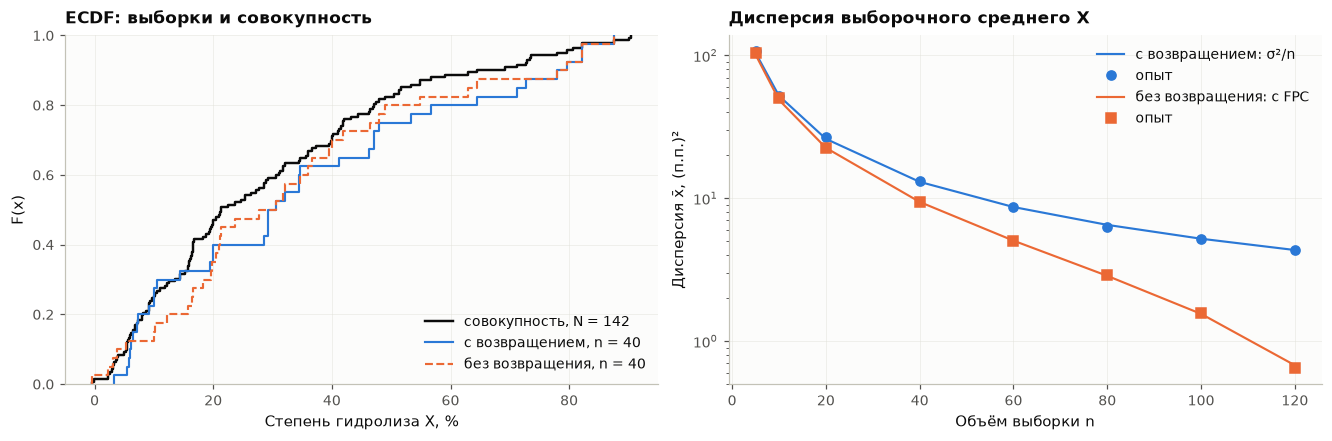

In [41]:
pop3 = hyd["x_pct"].to_numpy()
cmp3, s_with3, s_without3 = st.population_vs_samples(pop3, n=40, seed=SEED)
display(cmp3)
samp3 = st.sampling_distribution(pop3, ns=[5, 10, 20, 40, 60, 80, 100, 120], n_rep=5000, seed=SEED)
display(samp3)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
ax = axes[0]
ax.ecdf(pop3, color=pl.INK, lw=1.6, label=f"совокупность, N = {len(pop3)}")
ax.ecdf(s_with3, color=pl.SERIES[0], lw=1.4, label="с возвращением, n = 40")
ax.ecdf(s_without3, color=pl.SERIES[1], lw=1.4, ls="--", label="без возвращения, n = 40")
ax.set(xlabel=pl.AXIS_LABELS["X"], ylabel="F(x)", title="ECDF: выборки и совокупность")
ax.legend(loc="lower right")
ax = axes[1]
n = samp3["n"]
ax.plot(n, samp3["Var с возвр. (теория)"], color=pl.SERIES[0], lw=1.4, label="с возвращением: σ²/n")
ax.plot(n, samp3["Var с возвр. (опыт)"], color=pl.SERIES[0], ls="none", marker="o", label="опыт")
ax.plot(n, samp3["Var без возвр. (теория)"], color=pl.SERIES[1], lw=1.4, label="без возвращения: с FPC")
ax.plot(n, samp3["Var без возвр. (опыт)"], color=pl.SERIES[1], ls="none", marker="s", label="опыт")
ax.set_yscale("log")
ax.set(xlabel=pl.AXIS_LABELS["n"], ylabel="Дисперсия x̄, (п.п.)²", title="Дисперсия выборочного среднего X")
ax.legend()
plt.show()

**Что видно.** Обе выборки по 40 условий передают общую форму распределения: ECDF идут рядом, КС-тест различий не находит ($p = 0{,}33$ и $0{,}45$). Средние выше, чем у совокупности, на 4–6 п.п., медианы — на 8 п.п. Это одна-полторы стандартные ошибки ($\sigma/\sqrt{40} \approx 3{,}6$ п.п.) — ожидаемая выборочная ошибка для неоднородной совокупности. При повторном отборе эмпирические дисперсии среднего совпадают с теорией для обеих схем, а при $n \to N$ дисперсия выборки без возвращения стремится к нулю.

<a id="rv3-hypotheses"></a>
### Hypothesis Testing

Четыре вопроса о ферменте, $\alpha = 0{,}05$, поправка Холма — в [Lab resume](#resume).

#### H3.1. Отличается ли степень гидролиза свободного и иммобилизованного фермента (цикл 1)

- $H_0$: средняя разность $X_\text{своб} - X_\text{иммоб}$ при одинаковых условиях равна 0;
- $H_1$: $\ne 0$.

**Парный план.** Сравниваем фермент в одном и том же условии, так что влияние условий вычитается. Единица анализа — серия: 9 средних разностей, потому что условия одной серии делят общее приготовление. Для сравнения приведён и расчёт по 54 условиям, который игнорирует эту зависимость.

In [42]:
fi["d"] = fi["x_pct_f"] - fi["x_pct_i"]
d_series = fi.groupby("series")["d"].mean()
display(d_series.to_frame("средняя разность X_своб − X_иммоб, п.п."))
h31 = st.paired_test(d_series.to_numpy())
h31_cond = st.paired_test(fi["d"].to_numpy())
h31_w = stats.wilcoxon(d_series, method="exact").pvalue
display(pd.DataFrame({"по 9 сериям (верно)": h31, "по 54 условиям (псевдоповторности)": h31_cond}))
print(f"Точный тест Уилкоксона по сериям: p = {h31_w:.3f}")

,"средняя разность X_своб − X_иммоб, п.п."
series,
conc 0.25 %,3.419
conc 0.5 %,1.528
conc 0.75 %,-2.96
conc 1 %,2.935
conc 1.25 %,-2.146
kin60,3.512
kin90,2.824
ph,3.52
temp,-1.004


,по 9 сериям (верно),по 54 условиям (псевдоповторности)
n пар,9,54
средняя разность,1.292,1.292
SD разностей,2.615,5.629
ДИ 95 % — низ,-0.7178,-0.2445
ДИ 95 % — верх,3.302,2.828
медиана разностей,2.824,1.282
d_z (размер эффекта),0.4941,0.2295
p (парный t-тест),0.1765,0.09756
p (Уилкоксон),0.1641,0.01649
p (Шапиро для разностей),0.02723,0.002871


Точный тест Уилкоксона по сериям: p = 0.164


**Результат.** Средняя разность +1,3 п.п. в пользу свободного фермента, 95 % ДИ от −0,7 до +3,3 п.п. По сериям $p = 0{,}18$ по t-тесту и $p = 0{,}16$ по Уилкоксону. $H_0$ не отвергается. По 54 условиям тест Уилкоксона дал бы $p = 0{,}017$ — «значимое» различие, созданное псевдоповторностями. Это наглядный пример, почему важна единица анализа.

**Интерпретация.** В первом цикле иммобилизация на TiO₂ заметно не снижает активность глюкоамилазы. Возможная разница не больше примерно 3 п.п. — это верхняя граница доверительного интервала. Отсутствие значимости не доказывает равенства, но существенной потери активности при иммобилизации данные не показывают.

#### H3.2. Теряет ли иммобилизованный фермент активность при повторном использовании

- $H_0$: средняя степень гидролиза в цикле 1 равна средней в циклах 2–3;
- $H_1$: $\ne 0$.

В 7 сериях есть все три цикла. Для каждой серии берём разность «цикл 1 минус среднее циклов 2 и 3» и проверяем t-тестом и точным тестом Уилкоксона. Дополнительно проверяем ранговый критерий Фридмана по трём циклам и отдельно сравниваем циклы 2 и 3.

In [43]:
cyc_series = hyd[hyd["sample_type"] == "immobilized"].pivot_table(
    index=["series", "time_min", "substrate_pct"], columns="cycle", values="x_pct").dropna().groupby("series").mean()
cyc_series["цикл 1 − (2+3)/2"] = cyc_series[1] - cyc_series[[2, 3]].mean(axis=1)
cyc_series["сохранилось, %"] = 100 * cyc_series[[2, 3]].mean(axis=1) / cyc_series[1]
display(cyc_series)
h32_t = stats.ttest_1samp(cyc_series["цикл 1 − (2+3)/2"], 0.0)
h32_w = stats.wilcoxon(cyc_series["цикл 1 − (2+3)/2"], method="exact").pvalue
h32_f = stats.friedmanchisquare(cyc_series[1], cyc_series[2], cyc_series[3])
h32_23 = stats.wilcoxon(cyc_series[2], cyc_series[3], method="exact").pvalue
ci32 = h32_t.confidence_interval(0.95)
print(f"Средняя потеря: {cyc_series['цикл 1 − (2+3)/2'].mean():.1f} п.п., 95 % ДИ {ci32.low:.1f}…{ci32.high:.1f}; "
      f"t-тест p = {h32_t.pvalue:.4f}; Уилкоксон p = {h32_w:.4f}")
print(f"Фридман по циклам 1–3: χ² = {h32_f.statistic:.2f}, p = {h32_f.pvalue:.4f}; цикл 2 против 3: Уилкоксон p = {h32_23:.2f}")
print(f"Медиана сохранённой активности: {cyc_series['сохранилось, %'].median():.0f} %")

cycle,1,2,3,цикл 1 − (2+3)/2,"сохранилось, %"
series,,,,,
conc 0.25 %,69.15,3.873,3.81,65.31,5.555
conc 0.5 %,51.69,8.113,3.027,46.12,10.78
conc 0.75 %,48.02,5.873,5.341,42.41,11.68
conc 1 %,19.11,4.943,3.254,15.01,21.45
conc 1.25 %,34.62,3.209,10.1,27.96,19.23
kin60,60.79,8.047,8.718,52.41,13.79
kin90,15.27,5.007,6.1,9.72,36.36


Средняя потеря: 37.0 п.п., 95 % ДИ 18.3…55.7; t-тест p = 0.0029; Уилкоксон p = 0.0156
Фридман по циклам 1–3: χ² = 10.57, p = 0.0051; цикл 2 против 3: Уилкоксон p = 1.00
Медиана сохранённой активности: 14 %


**Результат.** Во всех 7 сериях степень гидролиза в цикле 1 выше. Средняя потеря 37 п.п., 95 % ДИ 18–56 п.п., $p = 0{,}003$ по t-тесту; точный тест Уилкоксона даёт минимально возможное при $n = 7$ значение $p = 0{,}016$. $H_0$ отвергается. Циклы 2 и 3 между собой не различаются ($p = 1$). После первого использования сохраняется около 14 % активности (медиана по сериям).

**Интерпретация.** Резкое падение именно после первого цикла и стабильность дальше — типичная картина для иммобилизации **адсорбцией**. Слабо связанный фермент десорбируется в раствор в первом цикле и работает как свободный. На носителе остаётся небольшая прочно связанная фракция. Проверить это можно, измерив активность раствора после удаления носителя; таких данных у нас нет, поэтому это гипотеза.

#### H3.3. Влияет ли температура на степень гидролиза

- $H_0$: средняя $X$ одинакова при 25, 40, 50, 70, 80 и 90 °C;
- $H_1$: хотя бы при одной температуре отличается.

Данные — только температурный эксперимент (одна постановка), 6 температур по 2 сосуда. Сосуд 1 и сосуд 2 систематически различаются (H2.2), поэтому используем **двухфакторный дисперсионный анализ**: фактор «температура» плюс блок «сосуд», без взаимодействия. Ещё выполняем **перестановочный тест**, которому не нужна нормальность. Размер эффекта — $\eta^2$, доля дисперсии, объяснённая температурой.

#### H3.4. Влияет ли pH на степень гидролиза

То же для pH-эксперимента: 6 значений pH по 2 сосуда.

In [44]:
anova_rows = []
for exp, fac, label in [("temp", "temperature_c", "H3.3 температура"), ("ph", "ph", "H3.4 pH")]:
    for tp in ["free", "immobilized"]:
        sub = hyd[(hyd["experiment"] == exp) & (hyd["sample_type"] == tp)]
        lg = pd.concat([sub.assign(vessel="1", xv=sub["x_vessel1"]), sub.assign(vessel="2", xv=sub["x_vessel2"])])
        fit = smf.ols(f"xv ~ C({fac}) + C(vessel)", data=lg).fit()
        aov = sm.stats.anova_lm(fit, typ=2)
        perm = st.permutation_oneway(lg["xv"], lg[fac].astype(str), n_perm=4999, seed=SEED)
        anova_rows.append({"гипотеза": label, "проба": pl.TYPE_LABELS[tp],
                           "F (фактор)": aov.loc[f"C({fac})", "F"], "p (фактор)": aov.loc[f"C({fac})", "PR(>F)"],
                           "p (сосуд-блок)": aov.loc["C(vessel)", "PR(>F)"], "p (перестановки)": perm["p (перестановки)"],
                           "η²": perm["η² (доля дисперсии от фактора)"],
                           "min X, %": sub["x_pct"].min(), "max X, %": sub["x_pct"].max()})
anova_tbl = pd.DataFrame(anova_rows)
display(anova_tbl)

,гипотеза,проба,F (фактор),p (фактор),p (сосуд-блок),p (перестановки),η²,"min X, %","max X, %"
0,H3.3 температура,свободный,190,1.071e-05,0.3231,0.0004,0.9935,-0.1105,90.49
1,H3.3 температура,иммобилизованный,97.95,5.517e-05,0.4157,0.0006,0.9883,16.29,90.11
2,H3.4 pH,свободный,16.88,0.003779,0.1826,0.005,0.9195,35.63,43.23
3,H3.4 pH,иммобилизованный,2,0.2326,0.8548,0.1434,0.665,27.26,48.95


**Результат.**

- **Температура (H3.3).** Влияние огромное у обоих типов фермента: $F$ = 190 и 98, $p \approx 10^{-5}$, $\eta^2 \approx 0{,}99$. Перестановочный тест даёт $p = 0{,}0004$: лишь одна из 4999 случайных перестановок дала $F$ не меньше наблюдаемого. $H_0$ отвергается. Оптимум около 70 °C, при 90 °C — денатурация.
- **pH (H3.4).** У свободного фермента влияние значимо: $p = 0{,}004$, $\eta^2 = 0{,}92$. Но сам эффект скромный: $X$ от 36 до 43 %, максимум около pH 4,7. У иммобилизованного фермента $p = 0{,}23$, $H_0$ не отвергается. Шум иммобилизованных проб (H2.1) при двух сосудах на точку не позволяет увидеть эффект такого размера. Это не доказывает, что pH на иммобилизованный фермент не влияет.
- **Блок «сосуд»** в обоих экспериментах незначим. При 30 мин реакции порядковый эффект мал по сравнению с влиянием температуры.

<a id="rv3-resume"></a>
### Resume

1. **Природа.** $X$ — функция двух случайных ОП, поэтому случайна. Прямое доказательство — измеренные отрицательные значения (−0,1 и −0,4 %) при отсутствии гидролиза. Погрешность считаем распространением ошибок с учётом контроля и множителя $1 - X/100$; исходная «Погрешность» — другая величина.
2. **Распределение.** При фиксированных условиях $X$ нормальна: отношение нормальных величин с малым CV знаменателя, что подтверждено Монте-Карло. По совокупности условий распределение задаётся дизайном опыта и многовершинно, поэтому закон для него не подбираем.
3. **Три уровня случайности.** Сосуды — около 4 п.п. Условия — 98 % дисперсии, это систематика. Эксперименты — до 29 п.п. при одинаковых номинальных условиях. Межэкспериментальная изменчивость — главное ограничение сравнений между опытами.
4. **Зависимость.** От СВ-01 и СВ-02 — функциональная. Свободный и иммобилизованный фермент связаны через общие условия ($r = 0{,}97$), их шум практически независим.
5. **Состоятельность.** $\hat X_n$ смещена при малых $n$ (Йенсен), но состоятельна: смещение $\propto 1/n$, разброс $\propto 1/\sqrt n$.
6. **Гипотезы.** Иммобилизация в цикле 1 активность заметно не снижает (+1,3 п.п., $p = 0{,}18$). Повторное использование снижает её примерно до 14 % ($p = 0{,}003$). Температура определяет гидролиз почти полностью (оптимум около 70 °C). pH влияет на свободный фермент слабо (максимум около 4,7), на иммобилизованный эффект не обнаружен.

<a id="comparative"></a>
## Comparative Analysis

### Итоговая таблица трёх случайных величин

Каждую величину описываем на двух уровнях. **Значения** — смесь условий опыта, их форму задаёт дизайн. **Случайная составляющая** — то, что остаётся при фиксированных условиях: это и есть «случайность» в смысле ТЗ.

In [45]:
x_noise = (hyd["x_vessel1"] - hyd["x_vessel2"]).to_numpy()   # разность сосудов для X, п.п.
summary = pd.DataFrame({
    "СВ-01: A_к": {
        "значений": len(a_ctrl), "среднее": a_ctrl["absorbance"].mean(), "SD": a_ctrl["absorbance"].std(ddof=1),
        "CV значений, %": 100 * a_ctrl["absorbance"].std(ddof=1) / a_ctrl["absorbance"].mean(),
        "случайная составляющая": "D = ln(A₁/A₂)", "n составляющей": len(D_c),
        "SD составляющей": D_c.std(ddof=1), "эксцесс составляющей": stats.kurtosis(D_c, bias=False),
        "Шапиро–Уилк p": stats.shapiro(D_c).pvalue, "модель шума": "нормальная",
        "ошибка одного сосуда": f"{100 * D_c.std(ddof=1) / np.sqrt(2):.1f} %"},
    "СВ-02: A_п (своб.)": {
        "значений": int((a_enz["sample_type"] == "free").sum()), "среднее": a_enz.loc[a_enz["sample_type"] == "free", "absorbance"].mean(),
        "SD": a_enz.loc[a_enz["sample_type"] == "free", "absorbance"].std(ddof=1),
        "CV значений, %": 100 * a_enz.loc[a_enz["sample_type"] == "free", "absorbance"].std(ddof=1) / a_enz.loc[a_enz["sample_type"] == "free", "absorbance"].mean(),
        "случайная составляющая": "D = ln(A₁/A₂)", "n составляющей": len(D_free),
        "SD составляющей": D_free.std(ddof=1), "эксцесс составляющей": stats.kurtosis(D_free, bias=False),
        "Шапиро–Уилк p": stats.shapiro(D_free).pvalue, "модель шума": "Лапласа (смесь нормальных)",
        "ошибка одного сосуда": f"{100 * D_free.std(ddof=1) / np.sqrt(2):.1f} %"},
    "СВ-02: A_п (иммоб., ц. 1)": {
        "значений": int(((a_enz["sample_type"] == "immobilized") & (a_enz["cycle"] == 1)).sum()),
        "среднее": a_enz.loc[a_enz["group"] == "иммоб., цикл 1", "absorbance"].mean(),
        "SD": a_enz.loc[a_enz["group"] == "иммоб., цикл 1", "absorbance"].std(ddof=1),
        "CV значений, %": 100 * a_enz.loc[a_enz["group"] == "иммоб., цикл 1", "absorbance"].std(ddof=1) / a_enz.loc[a_enz["group"] == "иммоб., цикл 1", "absorbance"].mean(),
        "случайная составляющая": "D = ln(A₁/A₂)", "n составляющей": len(D_imm),
        "SD составляющей": D_imm.std(ddof=1), "эксцесс составляющей": stats.kurtosis(D_imm, bias=False),
        "Шапиро–Уилк p": stats.shapiro(D_imm).pvalue, "модель шума": "Лапласа (смесь нормальных)",
        "ошибка одного сосуда": f"{100 * D_imm.std(ddof=1) / np.sqrt(2):.1f} %"},
    "СВ-03: X, %": {
        "значений": len(hyd), "среднее": hyd["x_pct"].mean(), "SD": hyd["x_pct"].std(ddof=1),
        "CV значений, %": 100 * hyd["x_pct"].std(ddof=1) / hyd["x_pct"].mean(),
        "случайная составляющая": "X₁ − X₂, п.п.", "n составляющей": len(x_noise),
        "SD составляющей": x_noise.std(ddof=1), "эксцесс составляющей": stats.kurtosis(x_noise, bias=False),
        "Шапиро–Уилк p": stats.shapiro(x_noise).pvalue, "модель шума": "нормальная в условии (дельта-метод)",
        "ошибка одного сосуда": f"{x_noise.std(ddof=1) / np.sqrt(2):.1f} п.п."},
})
display(summary)

,СВ-01: A_к,СВ-02: A_п (своб.),"СВ-02: A_п (иммоб., ц. 1)","СВ-03: X, %"
значений,108,108,108,142
среднее,1.044,0.6721,0.6841,29.17
SD,0.3501,0.3624,0.3556,22.91
"CV значений, %",33.54,53.93,51.98,78.52
случайная составляющая,D = ln(A₁/A₂),D = ln(A₁/A₂),D = ln(A₁/A₂),"X₁ − X₂, п.п."
n составляющей,54,54,54,142
SD составляющей,0.02498,0.07111,0.1062,5.266
эксцесс составляющей,-0.0345,2.784,2.403,1.441
Шапиро–Уилк p,0.3638,0.0007215,0.000591,4.577e-05
модель шума,нормальная,Лапласа (смесь нормальных),Лапласа (смесь нормальных),нормальная в условии (дельта-метод)


**Что видно.**

- **Ошибка растёт по цепочке измерения**: контроль около 1,8 % на сосуд, свободный фермент около 5 %, иммобилизованный около 7,5 %.
- **Форма шума меняется.** У контроля нормальная, у проб с ферментом — тяжёлые хвосты. В $X$ шум пробы и контроля складываются, поэтому разность сосудов $X_1 - X_2$ тоже не нормальна по совокупности условий. Её разброс зависит от условия, а в каждом условии $X$ нормальна (Монте-Карло).
- **Порядок значений.** У значений всех величин CV 30–80 %, у случайных составляющих — единицы процентов. Условия опыта доминируют, и это хорошо: эксперимент чувствителен к факторам.

### Откуда берётся неопределённость степени гидролиза

In [46]:
contrib = hyd.merge(pairs[["triplet_id", "sd"]], on="triplet_id").merge(
    ctrl[["experiment", "temperature_c", "ph", "substrate_pct", "time_min", "sd"]].rename(columns={"sd": "sd_c"}),
    on=["experiment", "temperature_c", "ph", "substrate_pct", "time_min"])
rel_p = (contrib["sd"] / np.sqrt(2) / contrib["a_sample"]) ** 2
rel_c = (contrib["sd_c"] / np.sqrt(2) / contrib["a_control"]) ** 2
contrib["доля от пробы"] = rel_p / (rel_p + rel_c)
display(contrib.groupby("group")["доля от пробы"].describe()[["count", "25%", "50%", "75%"]]
        .rename(columns={"50%": "медиана"}))

,count,25%,медиана,75%
group,,,,
"иммоб., цикл 1",54,0.2648,0.8852,0.9784
"иммоб., циклы 2–3",34,0.8822,0.9449,0.9739
свободный,54,0.4973,0.8519,0.9737


**Что видно.** В типичном условии 85–95 % дисперсии $u^2(X)$ даёт проба, а не контроль (медианы по группам). Но разброс большой: у иммобилизованного фермента в первом цикле в четверти условий доля пробы ниже 26 %, и главный вклад там даёт контроль. Отсюда практический совет. Чтобы уточнить степень гидролиза, сосудов пробы нужно больше, чем сосудов контроля. Для иммобилизованного фермента это особенно важно.

### Сводка зависимостей

| Пара | Вид зависимости | Чем показано |
|---|---|---|
| СВ-01 ↔ СВ-02, средние | через общие факторы: $C$ (+), время (−) | Пирсон 0,72–0,74; частная корреляция внутри $C$ −0,30…−0,51 |
| СВ-01 ↔ СВ-02, шум | не обнаружена | Спирмен −0,13…−0,19, перестановочный $p > 0{,}15$ |
| СВ-03 ↔ СВ-01, СВ-02 | функциональная, по построению | формула $X = 100(1-A_\text{п}/A_\text{к})$, частные производные |
| $X_\text{своб}$ ↔ $X_\text{иммоб}$ | через условия | $r = 0{,}97$; шум $\rho = 0{,}25$, $p = 0{,}06$ |
| сосуды одной серии | общая ошибка приготовления | ANOVA $p \approx 5\cdot10^{-5}$, ICC = 0,44 (контроль) |
| сосуд 1 ↔ сосуд 2 (с ферментом) | сдвиг на 2,4 % | 8 серий из 9, $p = 0{,}009$ (Холм: 0,051) |

<a id="resume"></a>
## Lab resume

### Проверенные гипотезы

Все гипотезы о систематических эффектах сведены в одну таблицу с **поправкой Холма**. Если проверить 11 гипотез на уровне 0,05 каждую, вероятность хотя бы одной ложной «значимости» при верных $H_0$ доходит до $1 - 0{,}95^{11} \approx 0{,}43$. Метод Холма контролирует эту вероятность (FWER) на уровне 0,05. Он упорядочивает p-value по возрастанию и сравнивает $k$-е с $\alpha/(m-k+1)$, поэтому он мощнее поправки Бонферрони. Проверки моделей — нормальность, бутстреп КС, корреляции шума — в семейство не входят: это проверки предположений, а не научные утверждения.

In [47]:
hyp = pd.DataFrame([
    ("H1.1", "СВ-01", "ОП контроля не меняется со временем", "t-тест наклонов", "7 серий", h11.pvalue),
    ("H1.2", "СВ-01", "калибровка без фона (a = 0)", "МНК по средним уровней C", "5 уровней", calib.loc["МНК по 5 средним (серии)", "p"]),
    ("H1.3", "СВ-01", "у контроля нет разницы сосудов 1 и 2", "t-тест средних D", "9 серий", h13_t.pvalue),
    ("H2.1", "СВ-02", "разброс одинаков у трёх типов проб", "Браун–Форсайт", "186 остатков в сериях", h21.pvalue),
    ("H2.2", "СВ-02", "у проб с ферментом нет разницы сосудов 1 и 2", "t-тест средних D", "9 серий", h22_t.pvalue),
    ("H3.1", "СВ-03", "X свободного = X иммобилизованного (цикл 1)", "парный t-тест", "9 серий", h31["p (парный t-тест)"]),
    ("H3.2", "СВ-03", "X в цикле 1 = X в циклах 2–3", "парный t-тест", "7 серий", h32_t.pvalue),
    ("H3.3а", "СВ-03", "температура не влияет (свободный)", "ANOVA T + блок", "12 сосудов", anova_tbl.loc[0, "p (фактор)"]),
    ("H3.3б", "СВ-03", "температура не влияет (иммобилизованный)", "ANOVA T + блок", "12 сосудов", anova_tbl.loc[1, "p (фактор)"]),
    ("H3.4а", "СВ-03", "pH не влияет (свободный)", "ANOVA pH + блок", "12 сосудов", anova_tbl.loc[2, "p (фактор)"]),
    ("H3.4б", "СВ-03", "pH не влияет (иммобилизованный)", "ANOVA pH + блок", "12 сосудов", anova_tbl.loc[3, "p (фактор)"]),
], columns=["№", "СВ", "H₀", "критерий", "единица анализа", "p"])
hyp["p (Холм)"] = st.holm(hyp["p"])[1]
hyp["решение (α = 0,05)"] = np.where(hyp["p (Холм)"] < 0.05, "H₀ отвергается", "нет оснований отвергнуть H₀")
display(hyp)
print(f"Проверено гипотез: {len(hyp)}; отвергнуто после поправки Холма: {(hyp['p (Холм)'] < 0.05).sum()}")

,№,СВ,H₀,критерий,единица анализа,p,p (Холм),"решение (α = 0,05)"
0,H1.1,СВ-01,ОП контроля не меняется со временем,t-тест наклонов,7 серий,0.01949,0.09747,нет оснований отвергнуть H₀
1,H1.2,СВ-01,калибровка без фона (a = 0),МНК по средним уровней C,5 уровней,0.0652,0.2608,нет оснований отвергнуть H₀
2,H1.3,СВ-01,у контроля нет разницы сосудов 1 и 2,t-тест средних D,9 серий,0.7984,0.7984,нет оснований отвергнуть H₀
3,H2.1,СВ-02,разброс одинаков у трёх типов проб,Браун–Форсайт,186 остатков в сериях,8.942e-05,0.0008048,H₀ отвергается
4,H2.2,СВ-02,у проб с ферментом нет разницы сосудов 1 и 2,t-тест средних D,9 серий,0.008529,0.05118,нет оснований отвергнуть H₀
5,H3.1,СВ-03,X свободного = X иммобилизованного (цикл 1),парный t-тест,9 серий,0.1765,0.5296,нет оснований отвергнуть H₀
6,H3.2,СВ-03,X в цикле 1 = X в циклах 2–3,парный t-тест,7 серий,0.002902,0.02322,H₀ отвергается
7,H3.3а,СВ-03,температура не влияет (свободный),ANOVA T + блок,12 сосудов,1.071e-05,0.0001178,H₀ отвергается
8,H3.3б,СВ-03,температура не влияет (иммобилизованный),ANOVA T + блок,12 сосудов,5.517e-05,0.0005517,H₀ отвергается
9,H3.4а,СВ-03,pH не влияет (свободный),ANOVA pH + блок,12 сосудов,0.003779,0.02645,H₀ отвергается


Проверено гипотез: 11; отвергнуто после поправки Холма: 5


**Что видно.** После поправки Холма отвергаются пять гипотез: о влиянии температуры (оба фермента), о разном разбросе типов проб, о потере активности при повторном использовании и о влиянии pH на свободный фермент. Систематическая разница сосудов 1 и 2 у проб с ферментом (H2.2) — на грани: $p = 0{,}009$ без поправки и 0,051 с поправкой. Дрейф контроля (H1.1) значим без поправки ($p = 0{,}019$), но после неё — нет. Это эффекты на пределе чувствительности 7–9 серий, их стоит перепроверить в отдельном опыте, где это будет основной вопрос.

### Основные результаты

1. **Данные.** В 163 из 196 троек третье значение ОП вычислено из первых двух. В анализе используем только два измеренных сосуда, иначе меняются погрешности и выводы тестов: 12 «значимых» различий против 3. Датасет 2 пересчитан, его исходная «Погрешность» — относительное среднее абсолютное отклонение ОП пробы, а не погрешность степени гидролиза.
2. **СВ-01, ОП контроля.** Определяется концентрацией крахмала ($A = 0{,}051 + 1{,}104\,C$). Случайная составляющая нормальна, ошибка около 1,8 % на сосуд, почти половина её — общий сдвиг серии (ICC = 0,44).
3. **СВ-02, ОП проб с ферментом.** Шум в 3–4 раза больше, с тяжёлыми хвостами; лучшая модель — закон Лапласа как смесь нормальных. Сосуд 1 в 8 сериях из 9 ниже в среднем на 2,4 % — вероятно, сказывается порядок запуска ($p = 0{,}009$, после поправки Холма 0,051). Случайные составляющие СВ-01 и СВ-02 независимы, средние связаны через общие факторы.
4. **СВ-03, степень гидролиза.** В фиксированном условии нормальна (отношение нормальных при малом CV знаменателя), погрешность — по закону распространения ошибок. Изменчивость между экспериментами (до 29 п.п.) намного больше изменчивости между сосудами (около 4 п.п.).
5. **Химия.** Температурный оптимум около 70 °C, денатурация при 90 °C. Иммобилизация на TiO₂ в первом цикле активность заметно не снижает (разница +1,3 п.п., не значима). Повторное использование оставляет около 14 % активности, что согласуется с десорбцией фермента, адсорбированного на носителе. pH влияет на свободный фермент слабо, максимум около pH 4,7.
6. **Статистика.** Состоятельность оценок проверена моделированием для всех трёх величин. Выборки без возвращения точнее выборок с возвращением (FPC), стратификация по слоям даёт выигрыш в разы. Главный методический урок — **единица анализа**: при подсчёте по отдельным точкам вместо серий получаются ложные «значимые» результаты (H1.2, H3.1).

### Ограничения

- **Мало повторностей.** На условие только два измеренных сосуда: у отдельных условий широкие доверительные интервалы, слабые эффекты (pH у иммобилизованного фермента) не видны.
- **Мало независимых единиц.** Эффективный объём для систематических эффектов — 7–9 серий, а не 54–142 условия.
- **Однофакторный дизайн.** Взаимодействия факторов не оцениваются. Сравнения между экспериментами смешаны с межэкспериментальной изменчивостью.
- **Нет бланков.** Без бланка «йод без крахмала» фоновое поглощение (около 0,05 ОП) не доказано и не исключено. Без контроля «носитель без фермента» нельзя отделить адсорбцию крахмала на TiO₂ от гидролиза: при 25 °C $X \approx 20\,\%$ у иммобилизованного фермента против 0 у свободного.
- **Датасет 2 воспроизводится не полностью.** 34 из 148 строк не получаются из текущих ОП, первичные данные для них неизвестны.
- **Выбросы сохранены.** 17 пар сосудов с $|z| > 3$ оставлены, поэтому выводы о форме шума проб с ферментом приблизительны.

<a id="cat-mark-table"></a>
### cat_mark_table

Столбец `cat_id` заполняется по таблице критериев курса, её в тексте ТЗ нет. `coeff` — множитель к номиналу категории: например, «за каждое распределение» × число распределений.

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| _(из таблицы курса)_ | [Dataset Description](#dataset), [Data Validation](#validation) | 1 | датасет по направлению; проверка данных, вычисленные повторности, пересчёт датасета 2 |
| _(из таблицы курса)_ | [СВ-01](#rv1-description), [СВ-02](#rv2-description), [СВ-03](#rv3-description) | 3 | три случайные величины, обоснование стохастической природы |
| _(из таблицы курса)_ | [СВ-02: Independence](#rv2-independence), [СВ-03: Independence](#rv3-independence) | 1 | зависимость и независимость СВ одной природы |
| _(из таблицы курса)_ | [СВ-01](#rv1-independence), [СВ-02](#rv2-independence), [СВ-03](#rv3-independence) | 3 | состоятельность оценок, эмпирически |
| _(из таблицы курса)_ | [СВ-01](#rv1-eda), [СВ-02](#rv2-eda), [СВ-03](#rv3-eda) | 3 | EDA и нормализация (z, робастный z, относительная активность) |
| _(из таблицы курса)_ | [СВ-01](#rv1-sampling), [СВ-02](#rv2-sampling), [СВ-03](#rv3-sampling) | 3 | выборки с возвращением и без, FPC, стратификация |
| _(из таблицы курса)_ | [нормальное](#rv1-eda), [Лапласа и Стьюдента](#rv2-eda), [отношение нормальных](#rv3-eda) | 3 | математическая база распределений |
| _(из таблицы курса)_ | [Lab resume](#resume) | 1 | 11 гипотез, поправка Холма |
| _(из таблицы курса)_ | [СВ-01: стандартизация](#rv1-eda) | 1 | доп.: приведение к стандартному нормальному |
| _(из таблицы курса)_ | [СВ-01](#rv1-eda), [СВ-02](#rv2-eda), [СВ-03](#rv3-eda) | 4 | доп.: распределения — нормальное, Лапласа, Стьюдента, отношения нормальных |
| _(из таблицы курса)_ | [Comparative Analysis](#comparative) | 1 | доп.: табличное представление итоговых метрик |
| _(из таблицы курса)_ | [References](#references) | 1 | доп.: список литературы с проверенными DOI |

<a id="references"></a>
## References

**Научные источники**

1. Гмурман В. Е. Руководство к решению задач по теории вероятностей и математической статистике : учеб. пособие. — 11-е изд., перераб. — М. : Высшее образование, 2007. — 404 с. — (Основы наук). *Описательные статистики, оценки, выборки, проверка гипотез.*
2. Wasserman L. All of Statistics: A Concise Course in Statistical Inference. — New York : Springer, 2004. — (Springer Texts in Statistics). — DOI: [10.1007/978-0-387-21736-9](https://doi.org/10.1007/978-0-387-21736-9). *Состоятельность, закон больших чисел, дельта-метод, бутстреп.*
3. Cochran W. G. Sampling Techniques. — 3rd ed. — New York : John Wiley & Sons, 1977. — ISBN 978-0-471-16240-7. *Выборки с возвращением и без, поправка на конечность совокупности, стратификация.*
4. Efron B., Tibshirani R. J. An Introduction to the Bootstrap. — New York : Chapman & Hall, 1993. — 436 p. — ISBN 978-0-412-04231-7. *Параметрический бутстреп p-value критерия КС.*
5. Shapiro S. S., Wilk M. B. An analysis of variance test for normality (complete samples) // Biometrika. — 1965. — Vol. 52, № 3–4. — P. 591–611. — DOI: [10.1093/biomet/52.3-4.591](https://doi.org/10.1093/biomet/52.3-4.591). *Критерий Шапиро–Уилка.*
6. Anderson T. W., Darling D. A. A Test of Goodness of Fit // Journal of the American Statistical Association. — 1954. — Vol. 49, № 268. — P. 765–769. — DOI: [10.2307/2281537](https://doi.org/10.2307/2281537). *Критерий Андерсона–Дарлинга.*
7. Lilliefors H. W. On the Kolmogorov–Smirnov Test for Normality with Mean and Variance Unknown // Journal of the American Statistical Association. — 1967. — Vol. 62, № 318. — P. 399–402. — DOI: [10.1080/01621459.1967.10482916](https://doi.org/10.1080/01621459.1967.10482916). *Критерий Лиллиефорса.*
8. D'Agostino R. B., Pearson E. S. Tests for Departure from Normality. Empirical Results for the Distributions of b₂ and √b₁ // Biometrika. — 1973. — Vol. 60, № 3. — P. 613–622. — JSTOR: [2335012](https://www.jstor.org/stable/2335012). *Критерий Д'Агостино–Пирсона.*
9. Brown M. B., Forsythe A. B. Robust tests for the equality of variances // Journal of the American Statistical Association. — 1974. — Vol. 69, № 346. — P. 364–367. — DOI: [10.1080/01621459.1974.10482955](https://doi.org/10.1080/01621459.1974.10482955). *H2.1.*
10. Fligner M. A., Killeen T. J. Distribution-free two-sample tests for scale // Journal of the American Statistical Association. — 1976. — Vol. 71, № 353. — P. 210–213. *H2.1, проверка.*
11. Wilcoxon F. Individual comparisons by ranking methods // Biometrics Bulletin. — 1945. — Vol. 1, № 6. — P. 80–83. — DOI: [10.2307/3001968](https://doi.org/10.2307/3001968). *Знаково-ранговый критерий.*
12. Friedman M. The use of ranks to avoid the assumption of normality implicit in the analysis of variance // Journal of the American Statistical Association. — 1937. — Vol. 32, № 200. — P. 675–701. — DOI: [10.1080/01621459.1937.10503522](https://doi.org/10.1080/01621459.1937.10503522). *H3.2, проверка.*
13. Holm S. A simple sequentially rejective multiple test procedure // Scandinavian Journal of Statistics. — 1979. — Vol. 6, № 2. — P. 65–70. — JSTOR: [4615733](https://www.jstor.org/stable/4615733). *Поправка на множественные сравнения.*
14. Akaike H. A new look at the statistical model identification // IEEE Transactions on Automatic Control. — 1974. — Vol. 19, № 6. — P. 716–723. — DOI: [10.1109/TAC.1974.1100705](https://doi.org/10.1109/TAC.1974.1100705). *Критерий AIC.*
15. Geary R. C. The Frequency Distribution of the Quotient of Two Normal Variates // Journal of the Royal Statistical Society. — 1930. — Vol. 93, № 3. — P. 442–446. — DOI: [10.2307/2342070](https://doi.org/10.2307/2342070). *Распределение отношения, СВ-03.*
16. Hinkley D. V. On the Ratio of Two Correlated Normal Random Variables // Biometrika. — 1969. — Vol. 56, № 3. — P. 635–639. — DOI: [10.2307/2334671](https://doi.org/10.2307/2334671). *Распределение отношения, СВ-03.*
17. Hurlbert S. H. Pseudoreplication and the design of ecological field experiments // Ecological Monographs. — 1984. — Vol. 54, № 2. — P. 187–211. — DOI: [10.2307/1942661](https://doi.org/10.2307/1942661). *Псевдоповторности, единица анализа.*
18. JCGM 100:2008. Evaluation of measurement data — Guide to the expression of uncertainty in measurement (GUM). — BIPM, 2008. — DOI: [10.59161/JCGM100-2008E](https://doi.org/10.59161/JCGM100-2008E). *Закон распространения неопределённостей, u(X).*
19. ISO 5725-3:2023. Accuracy (trueness and precision) of measurement methods and results — Part 3: Intermediate precision and alternative designs for collaborative studies. — ISO, 2023. *Сходимость и промежуточная прецизионность.*
20. Xiao Z., Storms R., Tsang A. A quantitative starch-iodine method for measuring alpha-amylase and glucoamylase activities // Analytical Biochemistry. — 2006. — Vol. 351, № 1. — P. 146–148. — DOI: [10.1016/j.ab.2006.01.036](https://doi.org/10.1016/j.ab.2006.01.036). *Йод-крахмальный метод.*

**Техническая документация**

21. Virtanen P., Gommers R., et al. SciPy 1.0: fundamental algorithms for scientific computing in Python // Nature Methods. — 2020. — Vol. 17. — P. 261–272. — DOI: [10.1038/s41592-019-0686-2](https://doi.org/10.1038/s41592-019-0686-2).
22. Seabold S., Perktold J. Statsmodels: Econometric and Statistical Modeling with Python // Proceedings of the 9th Python in Science Conference. — 2010. — P. 92–96. — DOI: [10.25080/Majora-92bf1922-011](https://doi.org/10.25080/Majora-92bf1922-011).
23. Harris C. R., Millman K. J., van der Walt S. J., et al. Array programming with NumPy // Nature. — 2020. — Vol. 585, № 7825. — P. 357–362. — DOI: [10.1038/s41586-020-2649-2](https://doi.org/10.1038/s41586-020-2649-2).
24. McKinney W. Data Structures for Statistical Computing in Python // Proceedings of the 9th Python in Science Conference. — 2010. — P. 56–61. — DOI: [10.25080/Majora-92bf1922-00a](https://doi.org/10.25080/Majora-92bf1922-00a).
25. Hunter J. D. Matplotlib: A 2D graphics environment // Computing in Science & Engineering. — 2007. — Vol. 9, № 3. — P. 90–95. — DOI: [10.1109/MCSE.2007.55](https://doi.org/10.1109/MCSE.2007.55).